# Normalize sqY2H consensus scores

This script applies various QA/QC steps and then computes a normalized interaction score. For QA/QC we:

1.   Check whether 6 media controls on each mega-plate meet various condition-specific thresholds
2.   Check for autoactivation mating failures
3.   Adjust consensus score based on autoactivation score and filter if score invalid

# Automated

In [2]:
import polars as pl 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import sys
sys.path.append("../../../1_allele_collection/2_analysis")
from plot_utils import *

sys.path.append("../..")
from analyses_plot_utils import *

In [3]:
inputs_dir = "../1_inputs/sqY2H"
outputs_dir = "../3_outputs/sqY2H"
meta_inputs = "../../../1_allele_collection/1_inputs"
meta_outputs = "../../../1_allele_collection/3_outputs"

scoring_conditions = ['LWH1', 'LWH10', 'LWH25', 'LWA']
max_score = 4
aa_id = 0
rrs_id = 999999.0

In [4]:
# get media control thresholds
media_score_thresholds = pd.read_csv(f"{inputs_dir}/media_control_score_thresholds.csv")
media_score_thresholds.rename(columns={'control_96': 'scoring_pos'}, inplace=True)

In [5]:
scores = pd.read_csv(f"{outputs_dir}/2_automated_raw_consensus_scores.csv") 

# Split into media controls
media_ctrls = scores[scores['media_control'] == True]
scores = scores[scores['media_control'] == False]

# Check media controls
media_ctrls = media_ctrls[['db_orf_id', 'condition_name', 'retest_batch', 'consensus_score']]
media_ctrls[['scoring_pos', 'retest_pla']] = media_ctrls['db_orf_id'].str.split('_', n=1, expand=True)
media_ctrls = media_ctrls.merge(media_score_thresholds, on=['scoring_pos', 'condition_name'])
media_ctrls['score_in_bounds'] = media_ctrls['consensus_score'].between(media_ctrls['lower_bound'], media_ctrls['upper_bound'], inclusive='both')

# replace failure due to variable scoring (99999) with NaN to group with other technical failures
scores['consensus_score'] = scores['consensus_score'].replace(99999, np.nan)

# Fix data types before converting to polars
scores['db_orf_id'] = pd.to_numeric(scores['db_orf_id'], errors='coerce')
scores['db_mut_id'] = pd.to_numeric(scores['db_mut_id'], errors='coerce')
scores['ad_orf_id'] = pd.to_numeric(scores['ad_orf_id'], errors='coerce')
scores['ad_mut_id'] = pd.to_numeric(scores['ad_mut_id'], errors='coerce')
scores['consensus_score'] = pd.to_numeric(scores['consensus_score'], errors='coerce')

# add IDs for groups used for filtering
scores = pl.DataFrame(scores)

scores = scores.with_columns(
    pl.col("retest_batch").str.extract(r"VUSAPWT(\d)B\d+", 1).alias("assay_id")
)

scores = scores.with_columns(
    pl.concat_str([
            pl.col('db_orf_id').cast(pl.String),
            pl.col('db_mut_id').cast(pl.String)
    ], separator="_").alias("db_group"),
    pl.concat_str([
            pl.col('db_orf_id').cast(pl.String),
            pl.col('db_mut_id').cast(pl.String),
            pl.col('condition_name').cast(pl.String),
            pl.col('retest_batch').cast(pl.String)
    ], separator="_").alias("db_condition_group"),
    pl.concat_str([
            pl.col('ad_orf_id').cast(pl.String),
            pl.col('db_orf_id').cast(pl.String),
            pl.col('db_mut_id').cast(pl.String),
            pl.col('retest_batch').cast(pl.String)
    ], separator="_").alias("ppi_group"),
    pl.concat_str([
            pl.col('ad_orf_id').cast(pl.String),
            pl.col('db_orf_id').cast(pl.String),
            pl.col('retest_batch').cast(pl.String)
    ], separator="_").alias("edge_group")
)

scores_before_seq = scores.clone()

scores

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_4660/2564219339.py:1: DtypeWarning: Columns (7) have mixed types. Specify dtype option on import or set low_memory=False.
  scores = pd.read_csv(f"{outputs_dir}/2_automated_raw_consensus_scores.csv")


scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,db_source_plate,db_source_well,ad_source_plate,ad_source_well,manual_score_growth,per_well_integrated_intensity_gray,contamination,automated_log2,consensus_score,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,db_group,db_condition_group,ppi_group,edge_group
str,str,str,str,str,str,str,bool,f64,f64,f64,f64,str,str,str,str,f64,f64,bool,f64,f64,str,str,str,str,str,str,str,f64,f64,str,str,str,str,str
"""VUSAPWT1B1r01_001""","""A03""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,0.0,null,2651.0,0.0,"""DisWTGDEh02""","""G09""","""CEGSint_Y8A1_2_6""","""A01""",4.0,455.65623,false,8.982013,494.701983,"""empty_ad""","""CLN6""",null,null,"""ENSG00000128973""",null,null,null,null,"""CLN6""","""2651.0_0.0""","""2651.0_0.0_LW_VUSAPWT1B1""","""0.0_2651.0_0.0_VUSAPWT1B1""","""0.0_2651.0_VUSAPWT1B1"""
"""VUSAPWT1B1r01_001""","""A05""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,0.0,null,7215.0,0.0,"""DisWTGDEh03""","""E01""","""CEGSint_Y8A1_2_6""","""A01""",4.0,505.925513,false,9.118748,512.738259,"""empty_ad""","""NR0B1""",null,null,"""ENSG00000169297""",null,null,null,null,"""NR0B1""","""7215.0_0.0""","""7215.0_0.0_LW_VUSAPWT1B1""","""0.0_7215.0_0.0_VUSAPWT1B1""","""0.0_7215.0_VUSAPWT1B1"""
"""VUSAPWT1B1r01_001""","""A07""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,279.0,null,11451.0,9.99999e5,"""RRS_VUS1_DB_1""","""B01""","""RRS_VUS1_AD_1""","""B01""",4.0,498.666689,false,9.099786,532.80656,"""CALCOCO2""",null,null,null,null,null,null,null,null,null,"""11451.0_999999.0""","""11451.0_999999.0_LW_VUSAPWT1B1""","""279.0_11451.0_999999.0_VUSAPWT…","""279.0_11451.0_VUSAPWT1B1"""
"""VUSAPWT1B1r01_001""","""A09""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,0.0,null,1.00016069e8,0.0,"""DisWTGDEh03""","""G03""","""CEGSint_Y8A1_2_6""","""A01""",4.0,496.091526,false,9.092999,528.079763,"""empty_ad""","""KCNJ2""",null,null,"""ENSG00000123700""",null,null,null,null,"""KCNJ2""","""100016069.0_0.0""","""100016069.0_0.0_LW_VUSAPWT1B1""","""0.0_100016069.0_0.0_VUSAPWT1B1""","""0.0_100016069.0_VUSAPWT1B1"""
"""VUSAPWT1B1r01_001""","""A11""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,15066.0,null,2713.0,0.0,"""DisWTGDEh03""","""A04""","""CEGSint_Y8A_3""","""F07""",4.0,557.534667,false,9.246823,569.41408,"""CXorf57""","""MLH1""",null,null,"""ENSG00000076242""",null,null,null,null,"""MLH1""","""2713.0_0.0""","""2713.0_0.0_LW_VUSAPWT1B1""","""15066.0_2713.0_0.0_VUSAPWT1B1""","""15066.0_2713.0_VUSAPWT1B1"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""VUSAPWT1B1r06_036""","""O13""","""VUSAPWT1B1r06_031_032_033_034_…","""VUSAPWT1B1""","""r12""","""LWAH1""","""1""",false,1.00063955e8,null,52920.0,218637.0,"""VUSMutY8Dh022""","""F07""","""CEGSint_Y8A_3""","""C07""",4.0,0.0,false,5.643856,null,"""N4BP1""","""LITAF""","""Leu122Val""","""364C>G""","""ENSG00000189067""","""Edgotyping3""","""1_Pathogenic""",null,null,"""LITAF_Leu122Val""","""52920.0_218637.0""","""52920.0_218637.0_LWAH1_VUSAPWT…","""100063955.0_52920.0_218637.0_V…","""100063955.0_52920.0_VUSAPWT1B1"""
"""VUSAPWT1B1r06_036""","""O15""","""VUSAPWT1B1r06_031_032_033_034_…","""VUSAPWT1B1""","""r12""","""LWAH1""","""1""",false,3598.0,null,52920.0,218637.0,"""VUSMutY8Dh022""","""F07""","""CEGSint_Y8A_6""","""B02""",2.0,0.0,false,5.643856,null,"""DAZAP2""","""LITAF""","""Leu122Val""","""364C>G""","""ENSG00000189067""","""Edgotyping3""","""1_Pathogenic""",null,null,"""LITAF_Leu122Val""","""52920.0_218637.0""","""52920.0_218637.0_LWAH1_VUSAPWT…","""3598.0_52920.0_218637.0_VUSAPW…","""3598.0_52920.0_VUSAPWT1B1"""
"""VUSAPWT1B1r06_036""","""O17""","""VUSAPWT1B1r06_031_032

In [6]:
scores.to_pandas().condition.unique()

array(['r07', 'r08', 'r09', 'r10', 'r11', 'r12', 'r13', 'r14', 'r15',
       'r16', 'r17', 'r18'], dtype=object)

In [7]:
def get_filtering_stats(scores_df, aa_id, rrs_id, step_name=""):
    """
    Get filtering statistics for a scores dataframe and return as dictionary
    
    Parameters:
    scores_df: polars DataFrame with the scores data
    aa_id: autoactivation ID to exclude 
    rrs_id: RRS ID to exclude
    step_name: optional name for the filtering step
    
    Returns:
    dict: Dictionary containing various counts
    """
    
    # Filter for non-autoactivation, non-RRS entries
    filtered_scores = scores_df.filter(
        (pl.col("ad_orf_id") != aa_id) & 
        (pl.col("db_mut_id") != rrs_id)
    )
    
    stats = {
        'step_name': step_name,
        'total_rows': scores_df.shape[0],
        'ppi_groups': filtered_scores.select(pl.col("ppi_group").n_unique()).item(),
        'db_orf_ids': filtered_scores.select(pl.col("db_orf_id").n_unique()).item(),
        'ad_orf_ids': filtered_scores.select(pl.col("ad_orf_id").n_unique()).item(),
        'db_groups': filtered_scores.select(pl.col("db_group").n_unique()).item(),
        'edge_groups': filtered_scores.select(pl.col("edge_group").n_unique()).item()
    }
    
    # Add counts for db_orf_ids with both WT and variants
    try:
        # Find db_orf_ids with WT data
        db_orfs_with_wt = filtered_scores.filter(pl.col("db_mut_id") == 0).select("db_orf_id").unique()
        
        # Find db_orf_ids with variant data  
        db_orfs_with_variants = filtered_scores.filter(pl.col("db_mut_id") != 0).select("db_orf_id").unique()
        
        # Get intersection - db_orf_ids that have both WT and variants
        db_orfs_with_both = db_orfs_with_wt.join(
            db_orfs_with_variants, 
            on="db_orf_id", 
            how="inner"
        )
        
        stats['db_orfs_with_wt'] = db_orfs_with_wt.height
        stats['db_orfs_with_variants'] = db_orfs_with_variants.height  
        stats['db_orfs_with_both_wt_and_variants'] = db_orfs_with_both.height
        
        # Filter to only include db_orf_ids that have both WT and variants
        scores_both = scores_df.filter(pl.col("db_orf_id").is_in(db_orfs_with_both.select("db_orf_id").to_series().to_list()))
        filtered_scores_both = scores_both.filter(
            (pl.col("ad_orf_id") != aa_id) & 
            (pl.col("db_mut_id") != rrs_id)
        )
        
        # Get ALL the statistics for the WT+variant filtered dataset
        stats['ppi_groups_with_both_wt_variants'] = filtered_scores_both.select(pl.col("ppi_group").n_unique()).item()
        stats['db_orf_ids_with_both_wt_variants'] = filtered_scores_both.select(pl.col("db_orf_id").n_unique()).item()
        stats['ad_orf_ids_with_both_wt_variants'] = filtered_scores_both.select(pl.col("ad_orf_id").n_unique()).item()
        stats['db_groups_with_both_wt_variants'] = filtered_scores_both.select(pl.col("db_group").n_unique()).item()
        stats['edge_groups_with_both_wt_variants'] = filtered_scores_both.select(pl.col("edge_group").n_unique()).item()
        
    except Exception as e:
        print(f"Warning: Could not calculate WT/variant stats for {step_name}: {e}")
        stats['db_orfs_with_wt'] = None
        stats['db_orfs_with_variants'] = None
        stats['db_orfs_with_both_wt_and_variants'] = None
        stats['ppi_groups_with_both_wt_variants'] = None
        stats['db_orf_ids_with_both_wt_variants'] = None
        stats['ad_orf_ids_with_both_wt_variants'] = None
        stats['db_groups_with_both_wt_variants'] = None
        stats['edge_groups_with_both_wt_variants'] = None
    
    return stats

def create_comprehensive_filtering_table(filtering_stats_list):
    """
    Create a comprehensive table showing all filtering steps with counts and percentages
    """
    import pandas as pd
    
    # Initialize the summary table
    summary_data = []
    
    for i, stats in enumerate(filtering_stats_list):
        if i == 0:
            # First step - no previous comparison
            row = {
                'Step': stats['step_name'],
                'Total_Rows': stats['total_rows'],
                'PPI_Groups': stats['ppi_groups'],
                'DB_ORF_IDs': stats['db_orf_ids'],
                'AD_ORF_IDs': stats['ad_orf_ids'],
                'DB_Groups': stats['db_groups'],
                'Edge_Groups': stats['edge_groups'],
                'DB_ORFs_Both_WT_Variants': stats.get('db_orfs_with_both_wt_and_variants', 'N/A'),
                'PPI_Groups_Both': stats.get('ppi_groups_with_both_wt_variants', 'N/A'),
                'DB_ORF_IDs_Both': stats.get('db_orf_ids_with_both_wt_variants', 'N/A'),
                'AD_ORF_IDs_Both': stats.get('ad_orf_ids_with_both_wt_variants', 'N/A'),
                'DB_Groups_Both': stats.get('db_groups_with_both_wt_variants', 'N/A'),
                'Edge_Groups_Both': stats.get('edge_groups_with_both_wt_variants', 'N/A'),
                'Rows_Dropped': 0,
                'PPIs_Dropped': 0,
                'DB_ORFs_Dropped': 0,
                'AD_ORFs_Dropped': 0,
                'DB_Groups_Dropped': 0,
                'Edge_Groups_Dropped': 0,
                'DB_ORFs_Both_Dropped': 0,
                'PPI_Groups_Both_Dropped': 0,
                'DB_ORF_IDs_Both_Dropped': 0,
                'AD_ORF_IDs_Both_Dropped': 0,
                'DB_Groups_Both_Dropped': 0,
                'Edge_Groups_Both_Dropped': 0,
                'Percent_Rows_Dropped': 0.0,
                'Percent_PPIs_Dropped': 0.0,
                'Percent_DB_ORFs_Dropped': 0.0,
                'Percent_AD_ORFs_Dropped': 0.0,
                'Percent_DB_Groups_Dropped': 0.0,
                'Percent_Edge_Groups_Dropped': 0.0,
                'Percent_DB_ORFs_Both_Dropped': 0.0,
                'Percent_PPI_Groups_Both_Dropped': 0.0,
                'Percent_DB_ORF_IDs_Both_Dropped': 0.0,
                'Percent_AD_ORF_IDs_Both_Dropped': 0.0,
                'Percent_DB_Groups_Both_Dropped': 0.0,
                'Percent_Edge_Groups_Both_Dropped': 0.0
            }
        else:
            # Compare with previous step
            prev_stats = filtering_stats_list[i-1]
            
            rows_dropped = prev_stats['total_rows'] - stats['total_rows']
            ppis_dropped = prev_stats['ppi_groups'] - stats['ppi_groups']
            db_orfs_dropped = prev_stats['db_orf_ids'] - stats['db_orf_ids']
            ad_orfs_dropped = prev_stats['ad_orf_ids'] - stats['ad_orf_ids']
            db_groups_dropped = prev_stats['db_groups'] - stats['db_groups']
            edge_groups_dropped = prev_stats['edge_groups'] - stats['edge_groups']
            
            # Handle WT/variant specific drops for ALL metrics
            db_orfs_both_dropped = 0
            ppi_groups_both_dropped = 0
            db_orf_ids_both_dropped = 0
            ad_orf_ids_both_dropped = 0
            db_groups_both_dropped = 0
            edge_groups_both_dropped = 0
            
            if (prev_stats.get('db_orfs_with_both_wt_and_variants') is not None and 
                stats.get('db_orfs_with_both_wt_and_variants') is not None):
                db_orfs_both_dropped = prev_stats['db_orfs_with_both_wt_and_variants'] - stats['db_orfs_with_both_wt_and_variants']
                ppi_groups_both_dropped = prev_stats['ppi_groups_with_both_wt_variants'] - stats['ppi_groups_with_both_wt_variants']
                db_orf_ids_both_dropped = prev_stats['db_orf_ids_with_both_wt_variants'] - stats['db_orf_ids_with_both_wt_variants']
                ad_orf_ids_both_dropped = prev_stats['ad_orf_ids_with_both_wt_variants'] - stats['ad_orf_ids_with_both_wt_variants']
                db_groups_both_dropped = prev_stats['db_groups_with_both_wt_variants'] - stats['db_groups_with_both_wt_variants']
                edge_groups_both_dropped = prev_stats['edge_groups_with_both_wt_variants'] - stats['edge_groups_with_both_wt_variants']
            
            row = {
                'Step': stats['step_name'],
                'Total_Rows': stats['total_rows'],
                'PPI_Groups': stats['ppi_groups'],
                'DB_ORF_IDs': stats['db_orf_ids'],
                'AD_ORF_IDs': stats['ad_orf_ids'],
                'DB_Groups': stats['db_groups'],
                'Edge_Groups': stats['edge_groups'],
                'DB_ORFs_Both_WT_Variants': stats.get('db_orfs_with_both_wt_and_variants', 'N/A'),
                'PPI_Groups_Both': stats.get('ppi_groups_with_both_wt_variants', 'N/A'),
                'DB_ORF_IDs_Both': stats.get('db_orf_ids_with_both_wt_variants', 'N/A'),
                'AD_ORF_IDs_Both': stats.get('ad_orf_ids_with_both_wt_variants', 'N/A'),
                'DB_Groups_Both': stats.get('db_groups_with_both_wt_variants', 'N/A'),
                'Edge_Groups_Both': stats.get('edge_groups_with_both_wt_variants', 'N/A'),
                'Rows_Dropped': rows_dropped,
                'PPIs_Dropped': ppis_dropped,
                'DB_ORFs_Dropped': db_orfs_dropped,
                'AD_ORFs_Dropped': ad_orfs_dropped,
                'DB_Groups_Dropped': db_groups_dropped,
                'Edge_Groups_Dropped': edge_groups_dropped,
                'DB_ORFs_Both_Dropped': db_orfs_both_dropped,
                'PPI_Groups_Both_Dropped': ppi_groups_both_dropped,
                'DB_ORF_IDs_Both_Dropped': db_orf_ids_both_dropped,
                'AD_ORF_IDs_Both_Dropped': ad_orf_ids_both_dropped,
                'DB_Groups_Both_Dropped': db_groups_both_dropped,
                'Edge_Groups_Both_Dropped': edge_groups_both_dropped,
                'Percent_Rows_Dropped': round((rows_dropped / prev_stats['total_rows']) * 100, 2) if prev_stats['total_rows'] > 0 else 0,
                'Percent_PPIs_Dropped': round((ppis_dropped / prev_stats['ppi_groups']) * 100, 2) if prev_stats['ppi_groups'] > 0 else 0,
                'Percent_DB_ORFs_Dropped': round((db_orfs_dropped / prev_stats['db_orf_ids']) * 100, 2) if prev_stats['db_orf_ids'] > 0 else 0,
                'Percent_AD_ORFs_Dropped': round((ad_orfs_dropped / prev_stats['ad_orf_ids']) * 100, 2) if prev_stats['ad_orf_ids'] > 0 else 0,
                'Percent_DB_Groups_Dropped': round((db_groups_dropped / prev_stats['db_groups']) * 100, 2) if prev_stats['db_groups'] > 0 else 0,
                'Percent_Edge_Groups_Dropped': round((edge_groups_dropped / prev_stats['edge_groups']) * 100, 2) if prev_stats['edge_groups'] > 0 else 0,
                'Percent_DB_ORFs_Both_Dropped': round((db_orfs_both_dropped / prev_stats['db_orfs_with_both_wt_and_variants']) * 100, 2) if prev_stats.get('db_orfs_with_both_wt_and_variants', 0) > 0 else 0,
                'Percent_PPI_Groups_Both_Dropped': round((ppi_groups_both_dropped / prev_stats['ppi_groups_with_both_wt_variants']) * 100, 2) if prev_stats.get('ppi_groups_with_both_wt_variants', 0) > 0 else 0,
                'Percent_DB_ORF_IDs_Both_Dropped': round((db_orf_ids_both_dropped / prev_stats['db_orf_ids_with_both_wt_variants']) * 100, 2) if prev_stats.get('db_orf_ids_with_both_wt_variants', 0) > 0 else 0,
                'Percent_AD_ORF_IDs_Both_Dropped': round((ad_orf_ids_both_dropped / prev_stats['ad_orf_ids_with_both_wt_variants']) * 100, 2) if prev_stats.get('ad_orf_ids_with_both_wt_variants', 0) > 0 else 0,
                'Percent_DB_Groups_Both_Dropped': round((db_groups_both_dropped / prev_stats['db_groups_with_both_wt_variants']) * 100, 2) if prev_stats.get('db_groups_with_both_wt_variants', 0) > 0 else 0,
                'Percent_Edge_Groups_Both_Dropped': round((edge_groups_both_dropped / prev_stats['edge_groups_with_both_wt_variants']) * 100, 2) if prev_stats.get('edge_groups_with_both_wt_variants', 0) > 0 else 0
            }
        
        summary_data.append(row)
    
    # Create DataFrame
    df = pd.DataFrame(summary_data)
    
    return df

In [8]:
# read in sequence confirmation files
ad_seq = pl.read_csv(f"{inputs_dir}/swimseq_confirmation/vus_ad_interactors.csv").rename({
    "swim_seq_validated": "seq_ad"
}).select([
    "ad_orf_id", "assay_id", "seq_ad"
])

db_var_seq = pl.read_csv(f"{inputs_dir}/swimseq_confirmation/vus_db_alleles.csv").rename({
    "orf_id": "db_orf_id",
    "mut_id": "db_mut_id",
    "swim_seq_validated": "seq_db"
}).select(["db_orf_id", "db_mut_id", "seq_db"])

db_ref_seq = pl.read_csv(f"{inputs_dir}/swimseq_confirmation/wt_disease_nodes_summary.csv").rename({
    "disease_orf_id": "db_orf_id",
    "swim_seq_validated": "seq_db"
}).select(["db_orf_id", "seq_db"]).with_columns(
    pl.lit(0).cast(pl.Int64).alias("db_mut_id")
).select(["db_orf_id", "db_mut_id", "seq_db"])

db_seq = pl.concat([db_var_seq, db_ref_seq])


# cast all to same format
scores = scores.with_columns(
    pl.col("ad_orf_id").cast(pl.Float64).cast(pl.Int64).alias("ad_orf_id"),
    pl.col("db_orf_id").cast(pl.Float64).cast(pl.Int64).alias("db_orf_id"),
    pl.col("db_mut_id").cast(pl.Float64).cast(pl.Int64).alias("db_mut_id"),
    pl.col("assay_id").cast(pl.String).alias("assay_id"),
)

db_seq = db_seq.with_columns(
    pl.col("db_orf_id").cast(pl.Float64).cast(pl.Int64).alias("db_orf_id"),
    pl.col("db_mut_id").cast(pl.Float64).cast(pl.Int64).alias("db_mut_id"),
    pl.col("seq_db").cast(pl.String).alias("seq_db")
)

ad_seq = ad_seq.with_columns(
    pl.col("ad_orf_id").cast(pl.Float64).cast(pl.Int64).alias("ad_orf_id"),
    pl.col("seq_ad").cast(pl.String).alias("seq_ad"),
    pl.col("assay_id").cast(pl.String).alias("assay_id"),
)

scores = scores.join(ad_seq, on=["ad_orf_id", "assay_id"], how="left")
scores = scores.join(db_seq, on=["db_orf_id", "db_mut_id"], how="left")

final_sequencing_df = pd.read_csv(f"{meta_outputs}/VarChampSeqConfirmationResult_final_call.tsv", sep="\t").rename({'mut_id': 'db_mut_id', 'orf_id': 'db_orf_id'}, axis=1)

final_sequencing_df

# Convert final_sequencing_df to polars and ensure matching data types
final_sequencing_pl = pl.DataFrame(final_sequencing_df).with_columns(
    pl.col("db_orf_id").cast(pl.Float64).cast(pl.Int64).alias("db_orf_id"),
    pl.col("db_mut_id").cast(pl.Float64).cast(pl.Int64).alias("db_mut_id")
).select(["db_orf_id", "db_mut_id", "db_seq_final"])

# Join the db_seq_final column onto scores
scores = scores.join(final_sequencing_pl, on=["db_orf_id", "db_mut_id"], how="left")

print(f"Scores shape: {scores.shape}")
print(f"Unique values in db_seq_final: {scores.select('db_seq_final').unique().to_pandas()['db_seq_final'].tolist()}")


scores_aa_rrs = scores.filter(
    (pl.col("ad_orf_id") == aa_id) | 
    (pl.col("db_mut_id") == rrs_id)
)

scores = scores.filter(
    (pl.col("seq_ad") == "1") & (pl.col("seq_db") == "1") & 
    (
        (pl.col("db_mut_id") == 0) |  # WT is always good
        (pl.col("db_seq_final") == "Y")  # Use the final Y/N decision from sequence confirmation
    )
)

scores = pl.concat([scores, scores_aa_rrs])

print("After sequence confirmation filtering:")
print(f"Scores shape: {scores.shape}")
print(f"Unique db_seq_final values: {scores.select('db_seq_final').unique().to_pandas()['db_seq_final'].tolist()}")

scores
scores_after_seq = scores.clone()

Scores shape: (71490, 38)
Unique values in db_seq_final: ['N', None, 'Y']
After sequence confirmation filtering:
Scores shape: (48282, 38)
Unique db_seq_final values: ['N', None, 'Y']


In [9]:
final_sequencing_df

,symbol,ensembl_gene_id,db_orf_id,db_mut_id,ccsb_mutation_id,ccsb_allele_id,spdi,nt_change,aa_change,collection,...,chr_num,nuc_loc,ref_allele,alt_allele,Chrom,entry_seq_final,db_seq_final,n2h_seq_final,dualip_seq_final,mislocalization_seq_final
0,GBA1,ENSG00000177628,2,6,CCSBVarC000001,ALE0000584,NC_000001.11:155240033:C:G,160G>C,Val54Leu,RC4,...,1,155240033,C,G,1,Y,Y,N,N,N
1,GBA1,ENSG00000177628,2,73,CCSBVarC000002,ALE00000002,NC_000001.11:155238225:G:A,670C>T,Leu224Phe,RC4,...,1,155238225,G,A,1,Y,Y,N,N,N
2,GBA1,ENSG00000177628,2,113,CCSBVarC000003,ALE00000003,NC_000001.11:155237453:C:T,887G>A,Arg296Gln,RC4,...,1,155237453,C,T,1,Y,Y,N,N,N
3,GBA1,ENSG00000177628,2,231,CCSBVarC000004,ALE00000004,NC_000001.11:155235252:A:G,1448T>C,Leu483Pro,RC4,...,1,155235252,A,G,1,Y,Y,N,N,N
4,GBA1,ENSG00000177628,2,213510,CCSBVarC003869,ALE00003869,NC_000001.11:155239934:G:A,259C>T,Arg87Trp,CEGS2,...,1,155239934,G,A,1,Y,Y,N,N,N
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8705,CTNNB1,ENSG00000168036,100070227,212487,CCSBVarC007073,ALE00007071,NC_000003.12:41225785:A:G,860A>G,Asn287Ser,CEGS2,...,3,41225785,A,G,3,Y,N,N,N,N
8706,TBX19,ENSG00000143178,100070258,212488,CCSBVarC007074,ALE00007072,NC_000001.11:168291339:C:T,383C>T,Ser128Phe,CEGS2,...,1,168291339,C,T,1,N,N,N,N,N
8707,TBX19,ENSG00000143178,100070258,212489,CCSBVarC007075,ALE00007073,NC_000001.11:168291213:T:G,257T>G,Met86Arg,CEGS2,...,1,168291213,T,G,1,Y,Y,N,N,N
8708,GDF2,ENSG00000263761,100070273,212491,CCSBVarC007076,ALE00007074,NC_000010.11:47322871:G:T,203G>T,Arg68Leu,CEGS2,...,10,47322871,G,T,10,N,N,N,N,N


In [10]:
scores_pd = scores.to_pandas()
scores_pd

,scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,...,gnomad_af,StarStatus,allele_0,db_group,db_condition_group,ppi_group,edge_group,seq_ad,seq_db,db_seq_final
0,VUSAPWT1B1r01_001,A15,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1,False,71704,NaN,...,NaN,NaN,SMAD3,11805.0_0.0,11805.0_0.0_LW_VUSAPWT1B1,71704.0_11805.0_0.0_VUSAPWT1B1,71704.0_11805.0_VUSAPWT1B1,1,1,None
1,VUSAPWT1B1r01_001,A17,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1,False,13662,NaN,...,NaN,NaN,AGXT,70497.0_0.0,70497.0_0.0_LW_VUSAPWT1B1,13662.0_70497.0_0.0_VUSAPWT1B1,13662.0_70497.0_VUSAPWT1B1,1,1,None
2,VUSAPWT1B1r01_001,A23,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1,False,11567,NaN,...,NaN,NaN,LITAF,52920.0_0.0,52920.0_0.0_LW_VUSAPWT1B1,11567.0_52920.0_0.0_VUSAPWT1B1,11567.0_52920.0_VUSAPWT1B1,1,1,None
3,VUSAPWT1B1r01_001,C03,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1,False,12260,NaN,...,NaN,NaN,CLN6,2651.0_0.0,2651.0_0.0_LW_VUSAPWT1B1,12260.0_2651.0_0.0_VUSAPWT1B1,12260.0_2651.0_VUSAPWT1B1,1,1,None
4,VUSAPWT1B1r01_001,C07,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1,False,5441,NaN,...,NaN,NaN,TH,71892.0_0.0,71892.0_0.0_LW_VUSAPWT1B1,5441.0_71892.0_0.0_VUSAPWT1B1,5441.0_71892.0_VUSAPWT1B1,1,1,None
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48277,VUSAPWT1B1r06_036,M19,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1,False,0,NaN,...,NaN,NaN,None,8420.0_999999.0,8420.0_999999.0_LWAH1_VUSAPWT1B1,0.0_8420.0_999999.0_VUSAPWT1B1,0.0_8420.0_VUSAPWT1B1,None,None,None
48278,VUSAPWT1B1r06_033,O07,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1,False,0,NaN,...,NaN,NaN,None,4910.0_999999.0,4910.0_999999.0_LWAH1_VUSAPWT1B1,0.0_4910.0_999999.0_VUSAPWT1B1,0.0_4910.0_VUSAPWT1B1,None,None,None
48279,VUSAPWT1B1r06_036,O05,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1,False,0,NaN,...,NaN,2.0,TTPA_His101Gln,13295.0_218058.0,13295.0_218058.0_LWAH1_VUSAPWT1B1,0.0_13295.0_218058.0_VUSAPWT1B1,0.0_13295.0_VUSAPWT1B1,None,0,Y
48280,VUSAPWT1B1r06_036,O09,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1,False,0,NaN,...,NaN,NaN,None,2595.0_999999.0,2595.0_999999.0_LWAH1_VUSAPWT1B1,0.0_2595.0_999999.0_VUSAPWT1B1,0.0_2595.0_VUSAPWT1B1,None,None,None


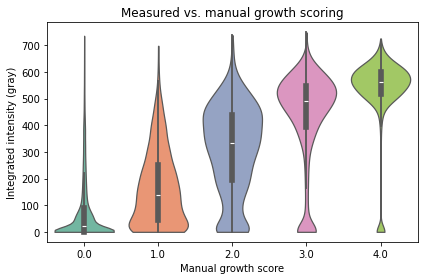

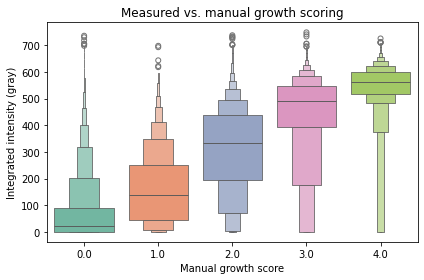

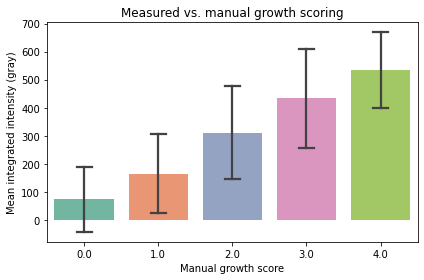

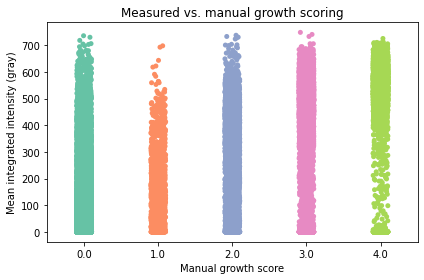

In [11]:
import os
import seaborn as sns
import matplotlib.pyplot as plt

scores_pd = scores_pd.dropna(subset=['manual_score_growth']).copy()


# Plot
y      = scores_pd['manual_score_growth'].astype(int)

# Violin
plt.figure(figsize=(6, 4))
sns.violinplot(
    data=scores_pd,
    x='manual_score_growth',
    y='per_well_integrated_intensity_gray',
    inner='box',         
    density_norm='width',
    cut=0,
    hue='manual_score_growth',
    palette='Set2',
    legend=False
)
plt.xlabel('Manual growth score')
plt.ylabel('Integrated intensity (gray)')
plt.title('Measured vs. manual growth scoring')
plt.tight_layout()
# plt.ylim(0, 1800) # Trim outliers on plot
# Export plot
# violinValidationPlotPath = os.path.join(PATH, "violin_plot_validation_against_GT.png")
# plt.savefig(violinValidationPlotPath, dpi=300)
plt.show()

# Boxen
plt.figure(figsize=(6, 4))
sns.boxenplot(
    data=scores_pd,
    x='manual_score_growth',
    y='per_well_integrated_intensity_gray',
    hue='manual_score_growth',
    palette='Set2',
    legend=False
)
# plt.ylim(0, 1500) # Trim outliers on the plot
plt.xlabel('Manual growth score')
plt.ylabel('Integrated intensity (gray)')
plt.title('Measured vs. manual growth scoring')
plt.tight_layout()
# Export plot
# boxenValidationPlotPath = os.path.join(PATH, "boxen_plot_validation_against_GT.png")
# plt.savefig(boxenValidationPlotPath, dpi=300)
plt.show()

# Bar
plt.figure(figsize=(6, 4))
sns.barplot(
    data=scores_pd,
    x='manual_score_growth',
    y='per_well_integrated_intensity_gray',
    errorbar='sd',   
    capsize=0.2,
    hue='manual_score_growth',
    palette='Set2',
    legend=False
)
plt.xlabel('Manual growth score')
plt.ylabel('Mean integrated intensity (gray)')
plt.title('Measured vs. manual growth scoring')
plt.tight_layout()
# Export plot
# barValidationPlotPath = os.path.join(PATH, "bar_plot_validation_against_GT.png")
# plt.savefig(barValidationPlotPath, dpi=300)
plt.show()


# swarmplot
plt.figure(figsize=(6, 4))
sns.stripplot(
    data=scores_pd,
    x='manual_score_growth',
    y='per_well_integrated_intensity_gray',
    # errorbar='sd',   
    # capsize=0.2,
    hue='manual_score_growth',
    palette='Set2',
    legend=False
)
plt.xlabel('Manual growth score')
plt.ylabel('Mean integrated intensity (gray)')
plt.title('Measured vs. manual growth scoring')
plt.tight_layout()
# Export plot
# barValidationPlotPath = os.path.join(PATH, "bar_plot_validation_against_GT.png")
# plt.savefig(barValidationPlotPath, dpi=300)
plt.show()

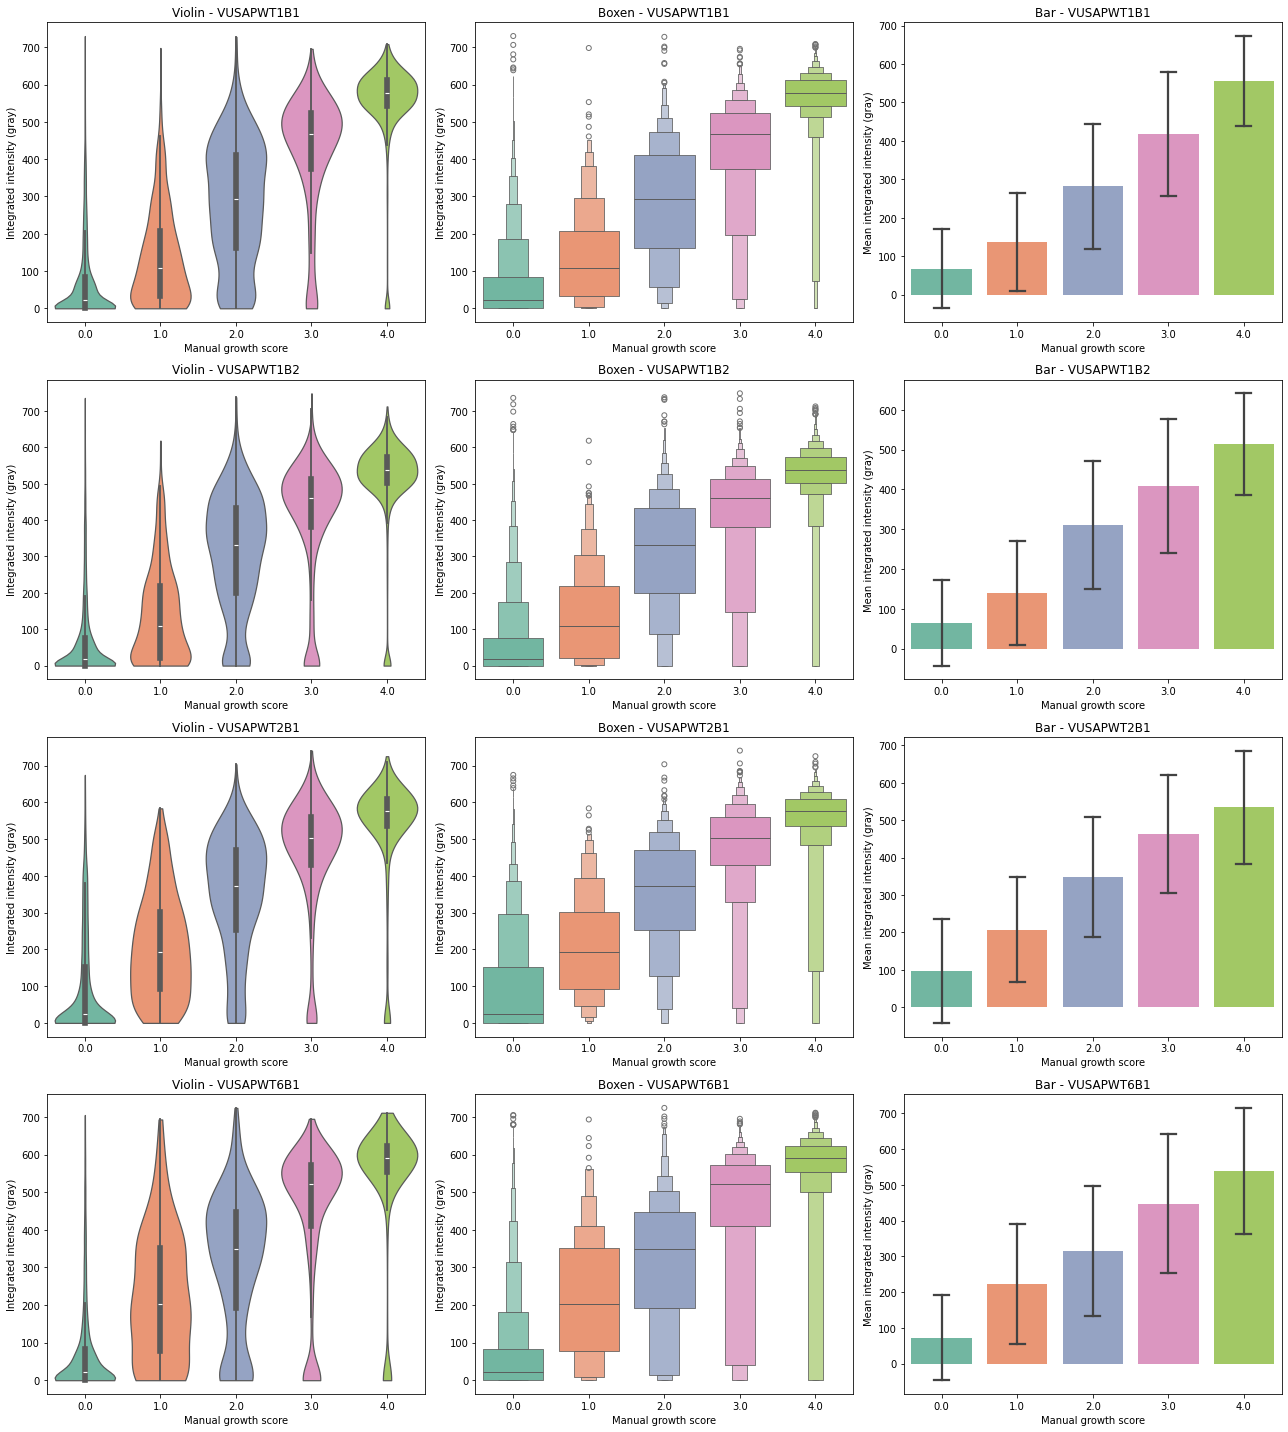

In [12]:
import os
import seaborn as sns
import matplotlib.pyplot as plt

scores_pd = scores_pd.dropna(subset=['manual_score_growth']).copy()

# Get unique retest_batch values
unique_batches = scores_pd['retest_batch'].unique()
n_batches = len(unique_batches)

# Create figure with subplots: rows = batches, columns = 3 plot types
fig, axes = plt.subplots(n_batches, 3, figsize=(18, 5*n_batches))

# If only one batch, make sure axes is 2D
if n_batches == 1:
    axes = axes.reshape(1, -1)

plot_types = ['Violin', 'Boxen', 'Bar']

for i, batch in enumerate(unique_batches):
    batch_data = scores_pd[scores_pd['retest_batch'] == batch].copy()
    
    if len(batch_data) == 0:
        # Hide empty subplots
        for j in range(3):
            axes[i, j].set_visible(False)
        continue
    
    # Violin plot
    sns.violinplot(
        data=batch_data,
        x='manual_score_growth',
        y='per_well_integrated_intensity_gray',
        inner='box',         
        density_norm='width',
        cut=0,
        hue='manual_score_growth',
        palette='Set2',
        legend=False,
        ax=axes[i, 0]
    )
    axes[i, 0].set_xlabel('Manual growth score')
    axes[i, 0].set_ylabel('Integrated intensity (gray)')
    axes[i, 0].set_title(f'Violin - {batch}')

    # Boxen plot
    sns.boxenplot(
        data=batch_data,
        x='manual_score_growth',
        y='per_well_integrated_intensity_gray',
        hue='manual_score_growth',
        palette='Set2',
        legend=False,
        ax=axes[i, 1]
    )
    axes[i, 1].set_xlabel('Manual growth score')
    axes[i, 1].set_ylabel('Integrated intensity (gray)')
    axes[i, 1].set_title(f'Boxen - {batch}')

    # Bar plot
    sns.barplot(
        data=batch_data,
        x='manual_score_growth',
        y='per_well_integrated_intensity_gray',
        errorbar='sd',   
        capsize=0.2,
        hue='manual_score_growth',
        palette='Set2',
        legend=False,
        ax=axes[i, 2]
    )
    axes[i, 2].set_xlabel('Manual growth score')
    axes[i, 2].set_ylabel('Mean integrated intensity (gray)')
    axes[i, 2].set_title(f'Bar - {batch}')

plt.tight_layout()
plt.show()

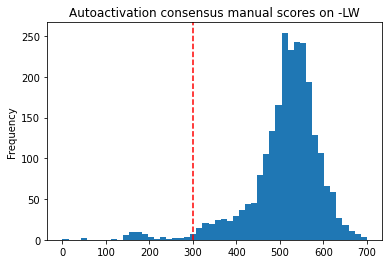

In [13]:
scores_pd = scores.to_pandas()

scores_pd[
    (scores_pd.ad_orf_id == aa_id) &
    (scores_pd.condition_name == 'LW')
].consensus_score.plot(kind='hist', bins=50, title='Autoactivation consensus manual scores on -LW')
plt.axvline(x=300, color='red', linestyle='--', label='Threshold')

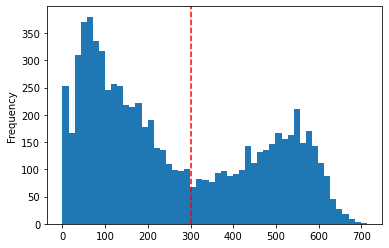

In [14]:

scores_pd[
    # (scores_pd.ad_orf_id == aa_id) &
    (scores_pd.condition_name == 'LWH1')
].consensus_score.plot(kind='hist', bins=50)#, title='Autoactivation consensus manual scores on -LW')
plt.axvline(x=300, color='red', linestyle='--', label='Threshold')

<Axes: title={'center': 'All consensus manual scores on all conditions'}, ylabel='Frequency'>

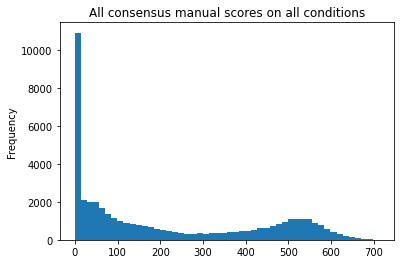

In [17]:
scores_pd.consensus_score.plot(kind='hist', bins=50, title='All consensus manual scores on all conditions')

<Axes: title={'center': 'All consensus manual scores on LWH1'}, ylabel='Frequency'>

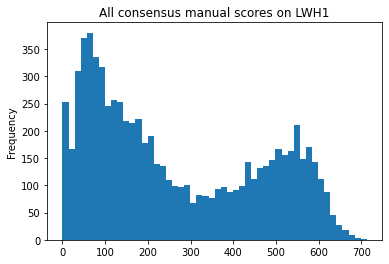

In [18]:
scores_pd[scores_pd.condition_name == 'LWH1'].consensus_score.plot(kind='hist', bins=50, title='All consensus manual scores on LWH1')

<Axes: title={'center': 'All consensus manual scores on LW'}, ylabel='Frequency'>

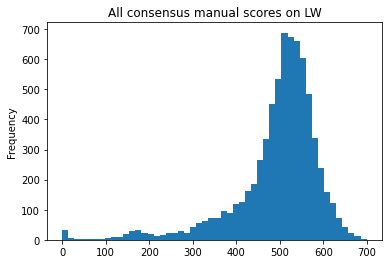

In [19]:
scores_pd[scores_pd.condition_name == 'LW'].consensus_score.plot(kind='hist', bins=50, title='All consensus manual scores on LW')

<Axes: title={'center': 'WT consensus manual scores on all conditions'}, ylabel='Frequency'>

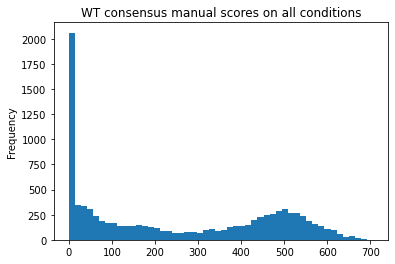

In [23]:
scores_pd[scores_pd.db_mut_id == 0].consensus_score.plot(kind='hist', bins=50, title='WT consensus manual scores on all conditions')

<Axes: title={'center': 'WT consensus manual scores on LWH1'}, ylabel='Frequency'>

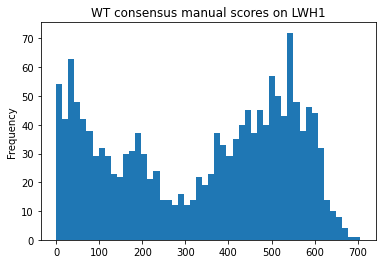

In [24]:
scores_pd[scores_pd.db_mut_id == 0][scores_pd[scores_pd.db_mut_id == 0].condition_name == 'LWH1'].consensus_score.plot(kind='hist', bins=50, title='WT consensus manual scores on LWH1')


<Axes: title={'center': 'WT consensus manual scores on LW'}, ylabel='Frequency'>

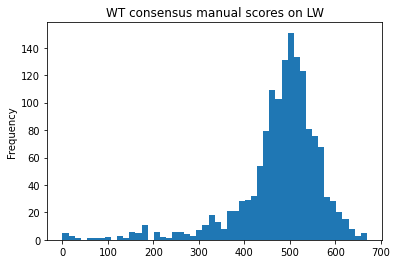

In [25]:
scores_pd[scores_pd.db_mut_id == 0][scores_pd[scores_pd.db_mut_id == 0].condition_name == 'LW'].consensus_score.plot(kind='hist', bins=50, title='WT consensus manual scores on LW')


In [16]:
stop

NameError: name 'stop' is not defined

## QA/QC filtering steps

In [ ]:
# print('Before filtering:')
# print(scores.shape)
# print('ppi_group', scores.filter(
#     (pl.col("ad_orf_id") != aa_id) & 
#     (pl.col("db_mut_id") != rrs_id)
# ).select(pl.col("ppi_group").n_unique()).item())
# print('db_orf_ids', scores.filter(
#     (pl.col("ad_orf_id") != aa_id) & 
#     (pl.col("db_mut_id") != rrs_id)
# ).select(pl.col("db_orf_id").n_unique()).item())
# print('ad_orf_ids', scores.filter(
#     (pl.col("ad_orf_id") != aa_id) & 
#     (pl.col("db_mut_id") != rrs_id)
# ).select(pl.col("ad_orf_id").n_unique()).item())
# print('db_groups', scores.filter(
#     (pl.col("ad_orf_id") != aa_id) & 
#     (pl.col("db_mut_id") != rrs_id)
# ).select(pl.col("db_group").n_unique()).item())
# print('edge_groups', scores.filter(
#     (pl.col("ad_orf_id") != aa_id) & 
#     (pl.col("db_mut_id") != rrs_id)
# ).select(pl.col("edge_group").n_unique()).item())



# Usage example - replace your current print statements with:
# stats_before = get_filtering_stats(scores, aa_id, rrs_id, "Before filtering")
# print_filtering_stats(stats_before)

# Remove all db groups with the same allele if there was an autoactivation mating failure
aa_db_group_mating_failures = (scores.filter(pl.col("ad_orf_id") == aa_id)
                              .filter(pl.col("condition_name") == "LW")
                              .filter(pl.col("consensus_score") <= 300)
                              .select("db_group")
                              .to_series().unique().to_list())
scores = scores.filter(~pl.col("db_group").is_in(aa_db_group_mating_failures))

print('After aa mating failure LW:')
print(scores.shape)
print('ppis', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ppi_group").n_unique()).item())
print('nodes', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("db_orf_id").n_unique()).item())
print('ads', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ad_orf_id").n_unique()).item())


scores_pd = scores.to_pandas()

print(len(scores_pd[
    (scores_pd['db_orf_id'] == 2803) & 
    (scores_pd['db_mut_id'] == 200947) 
    ]))


# Remove all db-condition groups with the same allele if there was an autoactivation mating failure
aa_db_group_tech_failures = (scores.filter(pl.col("ad_orf_id") == aa_id)
                                   .filter(pl.col("consensus_score").is_nan())
                                   .select("db_condition_group")
                                   .to_series().unique().to_list())
scores = scores.filter(~pl.col("db_condition_group").is_in(aa_db_group_tech_failures))

print('After aa mating failure other media:')
print(scores.shape)
print('ppis', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ppi_group").n_unique()).item())
print('nodes', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("db_orf_id").n_unique()).item())
print('ads', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ad_orf_id").n_unique()).item())

scores_pd = scores.to_pandas()

print(len(scores_pd[
    (scores_pd['db_orf_id'] == 2803) & 
    (scores_pd['db_mut_id'] == 200947) 
    ]))

# remove mating failures - condition 1 shows no or little yeast growth
mating_failures = (scores.filter(pl.col("condition_name") == "LW")
                         .filter(pl.col("consensus_score") <= 300)
                         .select("ppi_group").to_series().unique().to_list())
scores = scores.filter(~pl.col("ppi_group").is_in(mating_failures))


print('After mating failure LW step 1:')
print(scores.shape)
print('ppis', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ppi_group").n_unique()).item())
print('nodes', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("db_orf_id").n_unique()).item())
print('ads', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ad_orf_id").n_unique()).item())

scores_pd = scores.to_pandas()

print(len(scores_pd[
    (scores_pd['db_orf_id'] == 2803) & 
    (scores_pd['db_mut_id'] == 200947) 
    ]))


# Takes care of cases of mating failures where the consensus score is null
mating_failures_2 = (scores.filter(pl.col("condition_name") == "LW")
                         .filter(pl.col("consensus_score").is_null())
                         .select("ppi_group").to_series().unique().to_list())
scores = scores.filter(~pl.col("ppi_group").is_in(mating_failures_2))

print('After mating failure LW step 2:')
print(scores.shape)
print('ppis', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ppi_group").n_unique()).item())
print('nodes', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("db_orf_id").n_unique()).item())
print('ads', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ad_orf_id").n_unique()).item())

scores_pd = scores.to_pandas()

print(len(scores_pd[
    (scores_pd['db_orf_id'] == 2803) & 
    (scores_pd['db_mut_id'] == 200947) 
    ]))

# Adjust consensus score based on autoactivation score
aa_scores = scores.filter(pl.col("ad_orf_id") == aa_id).select([
    "db_condition_group", "consensus_score"
]).group_by("db_condition_group").agg(
    pl.col("consensus_score").mean().alias("aa_score")  # or .first() if you want the first value
)

# Remove autoactivation rows from the main scores df
# Add the aa_score to the dataframe, merged on the condition-specific db allele
scores = scores.filter(pl.col("ad_orf_id") != aa_id).join(aa_scores, on="db_condition_group", how="left")

print('remove aa rows:?')
print(scores.shape)
print('ppis', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ppi_group").n_unique()).item())
print('nodes', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("db_orf_id").n_unique()).item())
print('ads', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ad_orf_id").n_unique()).item())

scores_pd = scores.to_pandas()

print(len(scores_pd[
    (scores_pd['db_orf_id'] == 2803) & 
    (scores_pd['db_mut_id'] == 200947) 
    ]))


# substract aa values or
# remove if aa value > x (300)?

scores_adjusted = scores.with_columns(
    (pl.col("consensus_score") - pl.col("aa_score")).alias("adjusted_score")
).filter(
   ~((pl.col("adjusted_score") <= 0) & (pl.col("aa_score") > 0))
)

print('after adjusted score:')
print(scores_adjusted.shape)
print('ppis', scores_adjusted.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ppi_group").n_unique()).item())
print('nodes', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("db_orf_id").n_unique()).item())
print('ads', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ad_orf_id").n_unique()).item())

scores_before_aa = scores.clone()

# alternative approach, remove rows where aa score is greater than 300
# BUT keep all LW rows regardless of aa_score
scores_300 = scores.filter(
    (pl.col("condition_name") == "LW") |          # keep all LW
    pl.col("aa_score").is_null() |                # or no AA score
    (pl.col("aa_score") <= 300)                   # or AA score acceptable
)

print('after aa > 300:')
print(scores_300.shape)
print('ppis', scores_300.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ppi_group").n_unique()).item())
print('nodes', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("db_orf_id").n_unique()).item())
print('ads', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ad_orf_id").n_unique()).item())

scores_pd = scores.to_pandas()

print(len(scores_pd[
    (scores_pd['db_orf_id'] == 2803) & 
    (scores_pd['db_mut_id'] == 200947) 
    ]))


scores = scores_300
scores

After aa mating failure LW:
(46008, 38)
ppis 4373
nodes 244
ads 777
12
After aa mating failure other media:
(46008, 38)
ppis 4373
nodes 244
ads 777
12
After mating failure LW step 1:
(44484, 38)
ppis 4151
nodes 244
ads 757
12
After mating failure LW step 2:
(39066, 38)
ppis 3648
nodes 232
ads 695
0
remove aa rows:?
(25248, 39)
ppis 3648
nodes 232
ads 695
0
after adjusted score:
(15171, 40)
ppis 3263
nodes 232
ads 695
after aa > 300:
(24797, 39)
ppis 3648
nodes 232
ads 695
0


scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,db_source_plate,db_source_well,ad_source_plate,ad_source_well,manual_score_growth,per_well_integrated_intensity_gray,contamination,automated_log2,consensus_score,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,db_group,db_condition_group,ppi_group,edge_group,seq_ad,seq_db,db_seq_final,aa_score
str,str,str,str,str,str,str,bool,i64,f64,i64,i64,str,str,str,str,f64,f64,bool,f64,f64,str,str,str,str,str,str,str,f64,f64,str,str,str,str,str,str,str,str,f64
"""VUSAPWT1B1r01_001""","""A15""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,71704,null,11805,0,"""DisWTGDEh03""","""C04""","""CEGSint_Y8A_1""","""C01""",4.0,528.001331,false,9.174929,558.350679,"""SMURF2""","""SMAD3""",null,null,"""ENSG00000166949""",null,null,null,null,"""SMAD3""","""11805.0_0.0""","""11805.0_0.0_LW_VUSAPWT1B1""","""71704.0_11805.0_0.0_VUSAPWT1B1""","""71704.0_11805.0_VUSAPWT1B1""","""1""","""1""",null,509.083347
"""VUSAPWT1B1r01_001""","""A17""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,13662,null,70497,0,"""DisWTGDEh03""","""D04""","""CEGSint_Y8A_5""","""H07""",4.0,585.556892,false,9.311877,586.988591,"""CYSRT1""","""AGXT""",null,null,"""ENSG00000172482""",null,null,null,null,"""AGXT""","""70497.0_0.0""","""70497.0_0.0_LW_VUSAPWT1B1""","""13662.0_70497.0_0.0_VUSAPWT1B1""","""13662.0_70497.0_VUSAPWT1B1""","""1""","""1""",null,515.308517
"""VUSAPWT1B1r01_001""","""A23""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,11567,null,52920,0,"""DisWTGDEh03""","""A05""","""CEGSint_Y8A_5""","""A06""",4.0,572.135977,false,9.281086,578.211793,"""TAX1BP1""","""LITAF""",null,null,"""ENSG00000189067""",null,null,null,null,"""LITAF""","""52920.0_0.0""","""52920.0_0.0_LW_VUSAPWT1B1""","""11567.0_52920.0_0.0_VUSAPWT1B1""","""11567.0_52920.0_VUSAPWT1B1""","""1""","""1""",null,549.030745
"""VUSAPWT1B1r01_001""","""C03""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,12260,null,2651,0,"""DisWTGDEh02""","""G09""","""CEGSint_Y8A_7""","""B05""",4.0,476.3242,false,9.039808,509.349041,"""STX1A""","""CLN6""",null,null,"""ENSG00000128973""",null,null,null,null,"""CLN6""","""2651.0_0.0""","""2651.0_0.0_LW_VUSAPWT1B1""","""12260.0_2651.0_0.0_VUSAPWT1B1""","""12260.0_2651.0_VUSAPWT1B1""","""1""","""1""",null,494.701983
"""VUSAPWT1B1r01_001""","""C07""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,5441,null,71892,0,"""DisWTGDEh03""","""B03""","""CEGSint_Y8A_5""","""B07""",4.0,447.00917,false,8.957129,529.735972,"""PUF60""","""TH""",null,null,"""ENSG00000180176""",null,null,null,null,"""TH""","""71892.0_0.0""","""71892.0_0.0_LW_VUSAPWT1B1""","""5441.0_71892.0_0.0_VUSAPWT1B1""","""5441.0_71892.0_VUSAPWT1B1""","""1""","""1""",null,483.573543
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""VUSAPWT1B1r06_021""","""I15""","""VUSAPWT1B1r06_019_020_021_022_…","""VUSAPWT1B1""","""r12""","""LWAH1""","""1""",false,12137,null,5712,999999,"""RRS_VUS1_DB_2""","""A09""","""RRS_VUS1_AD_2""","""A09""",0.0,0.0,false,5.643856,5.902941,"""RGS20""",null,null,null,null,null,null,null,null,null,"""5712.0_999999.0""","""5712.0_999999.0_LWAH1_VUSAPWT1…","""12137.0_5712.0_999999.0_VUSAPW…","""12137.0_5712.0_VUSAPWT1B1""","""NULL""",null,null,0.0
"""VUSAPWT1B1r06_021""","""K09""","""VUSAPWT1B1r06_019_020_021_022_…","""VUSAPWT1B1""","""r12""","""LWAH1""","""1""",false,9939,null,4723,999999,"""RRS_VUS1_DB_2""","""G08""","""RRS_VUS1_AD_2""","""G08""",0.0,19.603922,false,6.121097,8.124183,"""NR5A1""",null,null,null,null,null,null,null,null,null,"""4723.0_999999.0""","""4723.0_999999.0_LWAH1_VUSAPWT1…","""9939.0_4723.0_999999.0_VUSAPWT…","""9939.0_4723.0_VUSAPWT1B1""","""0""",null,nul

In [ ]:
# Keep only scores that aren't RRS pairs
scores = scores.filter(pl.col('db_mut_id') != rrs_id)

scores = scores.with_columns(
    pl.col("retest_batch").str.extract(r"VUSAPWT(\d)B\d+", 1).alias("assay_id")
)

scores

scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,db_source_plate,db_source_well,ad_source_plate,ad_source_well,manual_score_growth,per_well_integrated_intensity_gray,contamination,automated_log2,consensus_score,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,db_group,db_condition_group,ppi_group,edge_group,seq_ad,seq_db,db_seq_final,aa_score
str,str,str,str,str,str,str,bool,i64,f64,i64,i64,str,str,str,str,f64,f64,bool,f64,f64,str,str,str,str,str,str,str,f64,f64,str,str,str,str,str,str,str,str,f64
"""VUSAPWT1B1r01_001""","""A15""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,71704,null,11805,0,"""DisWTGDEh03""","""C04""","""CEGSint_Y8A_1""","""C01""",4.0,528.001331,false,9.174929,558.350679,"""SMURF2""","""SMAD3""",null,null,"""ENSG00000166949""",null,null,null,null,"""SMAD3""","""11805.0_0.0""","""11805.0_0.0_LW_VUSAPWT1B1""","""71704.0_11805.0_0.0_VUSAPWT1B1""","""71704.0_11805.0_VUSAPWT1B1""","""1""","""1""",null,509.083347
"""VUSAPWT1B1r01_001""","""A17""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,13662,null,70497,0,"""DisWTGDEh03""","""D04""","""CEGSint_Y8A_5""","""H07""",4.0,585.556892,false,9.311877,586.988591,"""CYSRT1""","""AGXT""",null,null,"""ENSG00000172482""",null,null,null,null,"""AGXT""","""70497.0_0.0""","""70497.0_0.0_LW_VUSAPWT1B1""","""13662.0_70497.0_0.0_VUSAPWT1B1""","""13662.0_70497.0_VUSAPWT1B1""","""1""","""1""",null,515.308517
"""VUSAPWT1B1r01_001""","""A23""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,11567,null,52920,0,"""DisWTGDEh03""","""A05""","""CEGSint_Y8A_5""","""A06""",4.0,572.135977,false,9.281086,578.211793,"""TAX1BP1""","""LITAF""",null,null,"""ENSG00000189067""",null,null,null,null,"""LITAF""","""52920.0_0.0""","""52920.0_0.0_LW_VUSAPWT1B1""","""11567.0_52920.0_0.0_VUSAPWT1B1""","""11567.0_52920.0_VUSAPWT1B1""","""1""","""1""",null,549.030745
"""VUSAPWT1B1r01_001""","""C03""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,12260,null,2651,0,"""DisWTGDEh02""","""G09""","""CEGSint_Y8A_7""","""B05""",4.0,476.3242,false,9.039808,509.349041,"""STX1A""","""CLN6""",null,null,"""ENSG00000128973""",null,null,null,null,"""CLN6""","""2651.0_0.0""","""2651.0_0.0_LW_VUSAPWT1B1""","""12260.0_2651.0_0.0_VUSAPWT1B1""","""12260.0_2651.0_VUSAPWT1B1""","""1""","""1""",null,494.701983
"""VUSAPWT1B1r01_001""","""C07""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,5441,null,71892,0,"""DisWTGDEh03""","""B03""","""CEGSint_Y8A_5""","""B07""",4.0,447.00917,false,8.957129,529.735972,"""PUF60""","""TH""",null,null,"""ENSG00000180176""",null,null,null,null,"""TH""","""71892.0_0.0""","""71892.0_0.0_LW_VUSAPWT1B1""","""5441.0_71892.0_0.0_VUSAPWT1B1""","""5441.0_71892.0_VUSAPWT1B1""","""1""","""1""",null,483.573543
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""VUSAPWT1B1r06_033""","""O17""","""VUSAPWT1B1r06_031_032_033_034_…","""VUSAPWT1B1""","""r12""","""LWAH1""","""1""",false,1769,null,3535,201190,"""VUSMutY8Dh018""","""D11""","""CEGSint_Y8A_6""","""D08""",3.0,83.985622,false,7.065934,174.742486,"""CATSPER1""","""EMD""","""Met1Val""","""1A>G""","""ENSG00000102119""","""CEGS2""","""1_Pathogenic""",9.5000e-7,2.0,"""EMD_Met1Val""","""3535.0_201190.0""","""3535.0_201190.0_LWAH1_VUSAPWT1…","""1769.0_3535.0_201190.0_VUSAPWT…","""1769.0_3535.0_VUSAPWT1B1""","""1""","""1""","""Y""",0.0
"""VUSAPWT1B1r06_033""","""O21""","""VUSAPWT1B1r06_031_032_033_034_…","""VUSAPWT1B1""","""r12""","""LWAH1""","""1""",false,6811,null,4723,201739,"""VUSMutY8Dh019""","""H05""","""CEGSint_Y8A_3""","""A05""",3.0,0.0,false,5.643856,null,"""MAD1L1""","""TPM1""","""Leu185Arg""","""554T>G""","""ENSG00000140416""","""CEGS2""","""5_Others""",null,null,"""TPM1_L

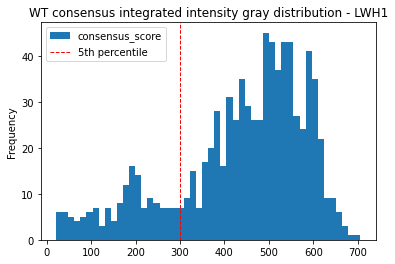

In [ ]:
scores_pd = scores.to_pandas()
fig = scores_pd[(scores_pd['db_mut_id'] == 0) &
                (scores_pd['condition_name'] == 'LWH1')].consensus_score.plot(kind='hist', bins=50, title='WT consensus integrated intensity gray distribution - LWH1')

plt.axvline(300, color='red', linestyle='dashed', linewidth=1, label='5th percentile')
plt.legend()

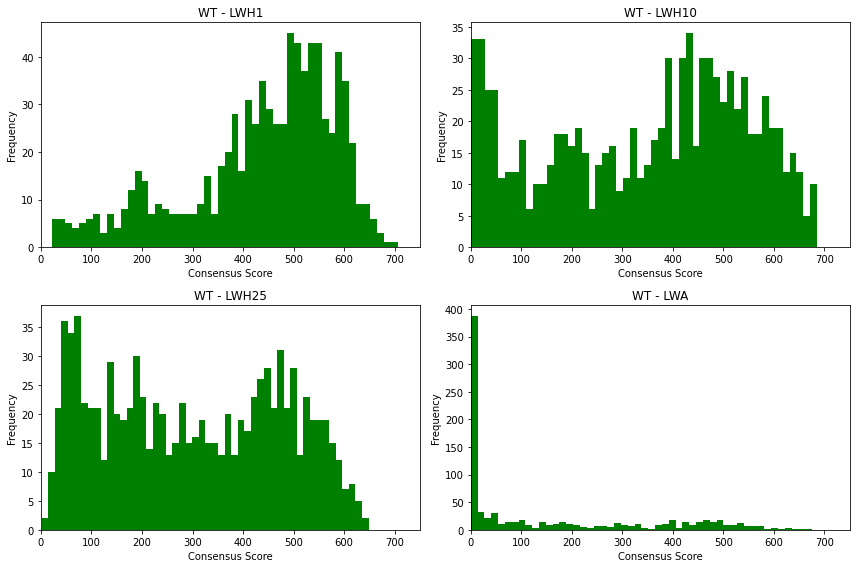

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()  # Make it easier to iterate

plot_df = scores_pd[scores_pd.db_mut_id == 0]

for i, condition in enumerate(scoring_conditions):
    df = plot_df[plot_df.condition_name == condition]
    df.consensus_score.plot(kind='hist', bins=50, 
                           title=f'WT - {condition}',
                           ax=axes[i],
                           color='green')
    axes[i].set_xlim(0, 750)  # Limit y-axis to better visualize WT distribution
    axes[i].set_xlabel('Consensus Score')
    axes[i].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

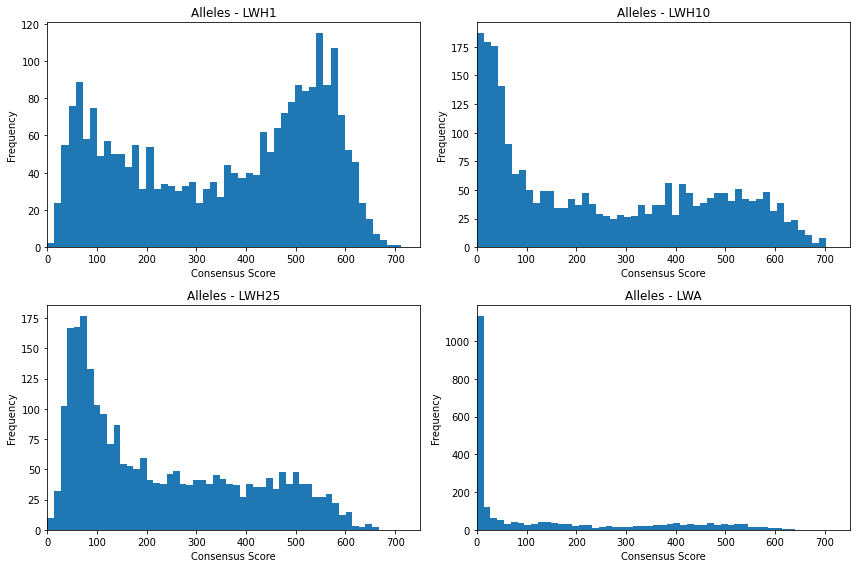

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()  # Make it easier to iterate

plot_df = scores_pd[scores_pd.db_mut_id != 0]

for i, condition in enumerate(scoring_conditions):
    df = plot_df[plot_df.condition_name == condition]
    df.consensus_score.plot(kind='hist', bins=50, 
                           title=f'Alleles - {condition}',
                           ax=axes[i])
    axes[i].set_xlim(0, 750)  # Limit y-axis to better visualize WT distribution
    axes[i].set_xlabel('Consensus Score')
    axes[i].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

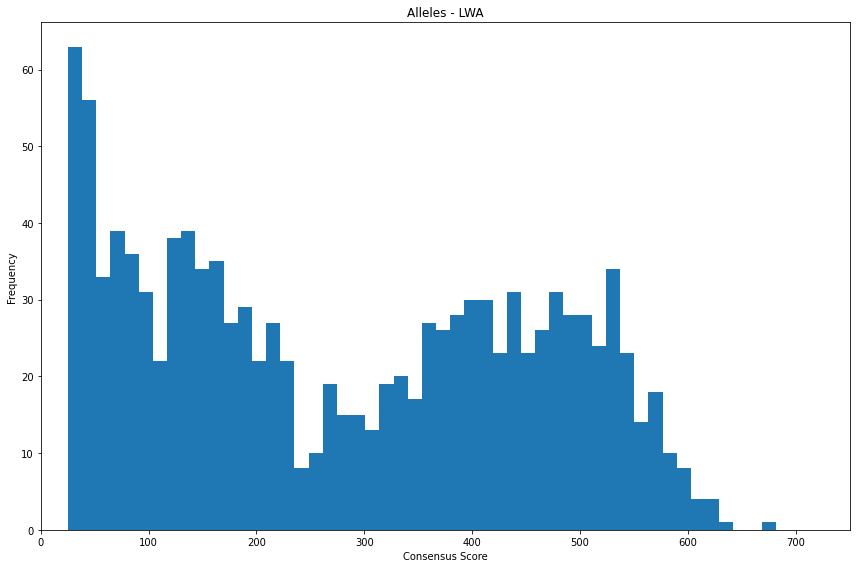

In [ ]:
fig, ax = plt.subplots(figsize=(12, 8))
# axes = axes.flatten()  # Make it easier to iterate

plot_df = scores_pd[(scores_pd.db_mut_id != 0) &
                    (scores_pd.consensus_score > 25)]

condition = 'LWA'

df = plot_df[plot_df.condition_name == condition]
df.consensus_score.plot(kind='hist', bins=50, 
                        title=f'Alleles - {condition}',
                        )
ax.set_xlim(0, 750)  # Limit y-axis to better visualize WT distribution
ax.set_xlabel('Consensus Score')
ax.set_ylabel('Frequency')

plt.tight_layout()
plt.show()

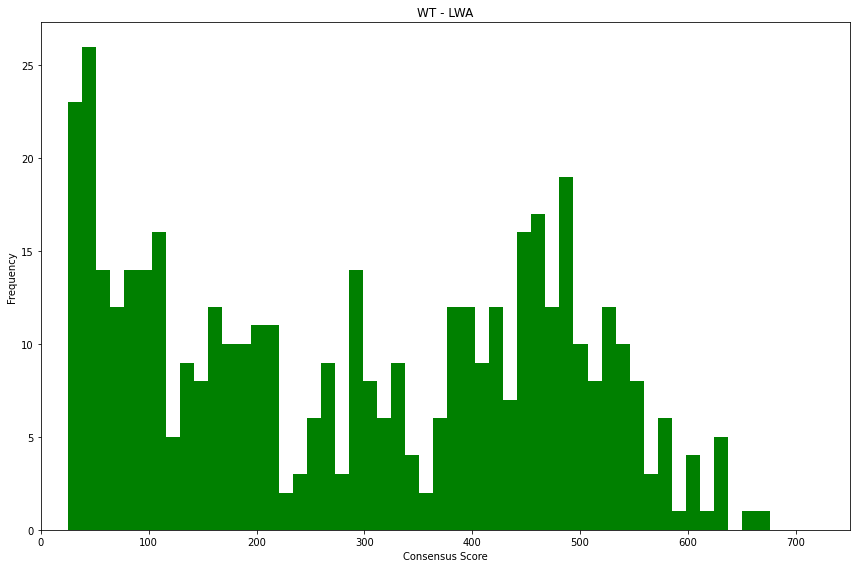

In [ ]:
fig, ax = plt.subplots(figsize=(12, 8))
# axes = axes.flatten()  # Make it easier to iterate

plot_df = scores_pd[(scores_pd.db_mut_id == 0) &
                    (scores_pd.consensus_score > 25)]

condition = 'LWA'

df = plot_df[plot_df.condition_name == condition]
df.consensus_score.plot(kind='hist', bins=50, 
                        title=f'WT - {condition}',
                        color='green'
                        )
ax.set_xlim(0, 750)  # Limit y-axis to better visualize WT distribution
ax.set_xlabel('Consensus Score')
ax.set_ylabel('Frequency')

plt.tight_layout()
plt.show()

In [ ]:
# Remove all WT and variants from an edge if the WT failed to grow substantially in the LWH1 condition
wt_failures = (scores.filter(pl.col("condition_name") == "LWH1")
                            .filter(pl.col("db_mut_id") == 0)
                            .filter(pl.col("consensus_score") < 300)
                            .select('edge_group')
                            .to_series().unique().to_list())
scores_dropped = scores.filter(pl.col("edge_group").is_in(wt_failures))
scores = scores.filter(~pl.col("edge_group").is_in(wt_failures))

print('removing WT failures:')
print(scores.shape)
print('ppis', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ppi_group").n_unique()).item())
print('nodes', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("db_orf_id").n_unique()).item())
print('ads', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ad_orf_id").n_unique()).item())


wt_failures

removing WT failures:
(17535, 39)
ppis 2977
nodes 204
ads 633


['7912.0_4062.0_VUSAPWT2B1',
 '71372.0_7634.0_VUSAPWT1B2',
 '11670.0_54230.0_VUSAPWT6B1',
 '13662.0_6137.0_VUSAPWT1B2',
 '56585.0_7198.0_VUSAPWT6B1',
 '54668.0_70497.0_VUSAPWT1B1',
 '52638.0_7038.0_VUSAPWT2B1',
 '13600.0_70497.0_VUSAPWT1B1',
 '100069021.0_5431.0_VUSAPWT2B1',
 '56508.0_6137.0_VUSAPWT1B2',
 '100066551.0_7652.0_VUSAPWT6B1',
 '978.0_7463.0_VUSAPWT1B2',
 '7408.0_6408.0_VUSAPWT6B1',
 '2304.0_7634.0_VUSAPWT1B2',
 '2265.0_7201.0_VUSAPWT1B2',
 '100068189.0_13943.0_VUSAPWT1B2',
 '53212.0_54308.0_VUSAPWT1B1',
 '6319.0_53737.0_VUSAPWT1B2',
 '13662.0_11895.0_VUSAPWT1B2',
 '2347.0_10950.0_VUSAPWT1B2',
 '11830.0_7675.0_VUSAPWT2B1',
 '11452.0_5712.0_VUSAPWT6B1',
 '10844.0_7198.0_VUSAPWT6B1',
 '3958.0_2448.0_VUSAPWT2B1',
 '11621.0_2012.0_VUSAPWT6B1',
 '100011278.0_2380.0_VUSAPWT1B2',
 '52634.0_3535.0_VUSAPWT6B1',
 '11648.0_2866.0_VUSAPWT1B2',
 '100070143.0_53965.0_VUSAPWT1B2',
 '56717.0_53065.0_VUSAPWT1B2',
 '10793.0_5645.0_VUSAPWT6B1',
 '2194.0_5933.0_VUSAPWT2B1',
 '56442.0_3535.0_VUS

In [ ]:
scores_pd = scores.to_pandas()

In [ ]:
# mapping manual consensus scores

manual_scores = pl.read_csv(f"{outputs_dir}/3_normalized_qaqc_consensus_scores.csv")

manual_scores = manual_scores.with_columns(
    pl.col("ad_orf_id").cast(pl.Float64).cast(pl.Int64).alias("ad_orf_id"),
    pl.col("db_orf_id").cast(pl.Float64).cast(pl.Int64).alias("db_orf_id"),
    pl.col("db_mut_id").cast(pl.Float64).cast(pl.Int64).alias("db_mut_id"),
    pl.col("retest_batch").str.extract(r"VUSAPWT(\d)B\d+", 1).alias("assay_id"),
    pl.col("consensus_score").alias("consensus_manual_score_growth")
)

# join to scores
scores = scores.join(manual_scores.select([
    "ad_orf_id", "db_orf_id", "db_mut_id", "assay_id", "condition_name", "consensus_manual_score_growth"
]), on=["ad_orf_id", "db_orf_id", "db_mut_id", "assay_id", "condition_name"], how="left")

scores

scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,db_source_plate,db_source_well,ad_source_plate,ad_source_well,manual_score_growth,per_well_integrated_intensity_gray,contamination,automated_log2,consensus_score,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,db_group,db_condition_group,ppi_group,edge_group,seq_ad,seq_db,db_seq_final,aa_score,consensus_manual_score_growth
str,str,str,str,str,str,str,bool,i64,f64,i64,i64,str,str,str,str,f64,f64,bool,f64,f64,str,str,str,str,str,str,str,f64,f64,str,str,str,str,str,str,str,str,f64,f64
"""VUSAPWT1B1r01_001""","""A15""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,71704,null,11805,0,"""DisWTGDEh03""","""C04""","""CEGSint_Y8A_1""","""C01""",4.0,528.001331,false,9.174929,558.350679,"""SMURF2""","""SMAD3""",null,null,"""ENSG00000166949""",null,null,null,null,"""SMAD3""","""11805.0_0.0""","""11805.0_0.0_LW_VUSAPWT1B1""","""71704.0_11805.0_0.0_VUSAPWT1B1""","""71704.0_11805.0_VUSAPWT1B1""","""1""","""1""",null,509.083347,null
"""VUSAPWT1B1r01_001""","""A17""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,13662,null,70497,0,"""DisWTGDEh03""","""D04""","""CEGSint_Y8A_5""","""H07""",4.0,585.556892,false,9.311877,586.988591,"""CYSRT1""","""AGXT""",null,null,"""ENSG00000172482""",null,null,null,null,"""AGXT""","""70497.0_0.0""","""70497.0_0.0_LW_VUSAPWT1B1""","""13662.0_70497.0_0.0_VUSAPWT1B1""","""13662.0_70497.0_VUSAPWT1B1""","""1""","""1""",null,515.308517,null
"""VUSAPWT1B1r01_001""","""A23""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,11567,null,52920,0,"""DisWTGDEh03""","""A05""","""CEGSint_Y8A_5""","""A06""",4.0,572.135977,false,9.281086,578.211793,"""TAX1BP1""","""LITAF""",null,null,"""ENSG00000189067""",null,null,null,null,"""LITAF""","""52920.0_0.0""","""52920.0_0.0_LW_VUSAPWT1B1""","""11567.0_52920.0_0.0_VUSAPWT1B1""","""11567.0_52920.0_VUSAPWT1B1""","""1""","""1""",null,549.030745,null
"""VUSAPWT1B1r01_001""","""C03""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,12260,null,2651,0,"""DisWTGDEh02""","""G09""","""CEGSint_Y8A_7""","""B05""",4.0,476.3242,false,9.039808,509.349041,"""STX1A""","""CLN6""",null,null,"""ENSG00000128973""",null,null,null,null,"""CLN6""","""2651.0_0.0""","""2651.0_0.0_LW_VUSAPWT1B1""","""12260.0_2651.0_0.0_VUSAPWT1B1""","""12260.0_2651.0_VUSAPWT1B1""","""1""","""1""",null,494.701983,null
"""VUSAPWT1B1r01_001""","""C07""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,5441,null,71892,0,"""DisWTGDEh03""","""B03""","""CEGSint_Y8A_5""","""B07""",4.0,447.00917,false,8.957129,529.735972,"""PUF60""","""TH""",null,null,"""ENSG00000180176""",null,null,null,null,"""TH""","""71892.0_0.0""","""71892.0_0.0_LW_VUSAPWT1B1""","""5441.0_71892.0_0.0_VUSAPWT1B1""","""5441.0_71892.0_VUSAPWT1B1""","""1""","""1""",null,483.573543,null
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""VUSAPWT1B1r06_033""","""O13""","""VUSAPWT1B1r06_031_032_033_034_…","""VUSAPWT1B1""","""r12""","""LWAH1""","""1""",false,11922,null,2713,200832,"""VUSMutY8Dh018""","""B04""","""CEGSint_Y8A_6""","""D05""",2.0,48.005229,false,6.614787,null,"""MYOG""","""MLH1""","""Gly147Arg""","""439G>C""","""ENSG00000076242""","""CEGS2""","""3_Conflicting""",null,1.0,"""MLH1_Gly147Arg""","""2713.0_200832.0""","""2713.0_200832.0_LWAH1_VUSAPWT1…","""11922.0_2713.0_200832.0_VUSAPW…","""11922.0_2713.0_VUSAPWT1B1""","""1""","""1""","""Y""",2.590196,2.0
"""VUSAPWT1B1r06_033""","""O15""","""VUSAPWT1B1r06_031_032_033_034_…","""VUSAPWT1B1""","""r12""","""LWAH1""","""1""",false,9267,null,3535,201190,"""VUSMutY8Dh018""","""D11""","""CEGSint_Y8A_4""","""G10""",3.0,0.0,false,5.643856,null,"""CCDC155""","""EMD""","""Met1Val""","""1A>G""","""ENS

In [ ]:
# write out results
scores.write_csv(f"{outputs_dir}/3_automated_qaqc_consensus_scores.csv")

In [ ]:
scores_pd

,scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,...,StarStatus,allele_0,db_group,db_condition_group,ppi_group,edge_group,seq_ad,seq_db,db_seq_final,aa_score
0,VUSAPWT1B1r01_001,A15,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1,False,71704,NaN,...,NaN,SMAD3,11805.0_0.0,11805.0_0.0_LW_VUSAPWT1B1,71704.0_11805.0_0.0_VUSAPWT1B1,71704.0_11805.0_VUSAPWT1B1,1,1,None,509.083347
1,VUSAPWT1B1r01_001,A17,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1,False,13662,NaN,...,NaN,AGXT,70497.0_0.0,70497.0_0.0_LW_VUSAPWT1B1,13662.0_70497.0_0.0_VUSAPWT1B1,13662.0_70497.0_VUSAPWT1B1,1,1,None,515.308517
2,VUSAPWT1B1r01_001,A23,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1,False,11567,NaN,...,NaN,LITAF,52920.0_0.0,52920.0_0.0_LW_VUSAPWT1B1,11567.0_52920.0_0.0_VUSAPWT1B1,11567.0_52920.0_VUSAPWT1B1,1,1,None,549.030745
3,VUSAPWT1B1r01_001,C03,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1,False,12260,NaN,...,NaN,CLN6,2651.0_0.0,2651.0_0.0_LW_VUSAPWT1B1,12260.0_2651.0_0.0_VUSAPWT1B1,12260.0_2651.0_VUSAPWT1B1,1,1,None,494.701983
4,VUSAPWT1B1r01_001,C07,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1,False,5441,NaN,...,NaN,TH,71892.0_0.0,71892.0_0.0_LW_VUSAPWT1B1,5441.0_71892.0_0.0_VUSAPWT1B1,5441.0_71892.0_VUSAPWT1B1,1,1,None,483.573543
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17530,VUSAPWT1B1r06_033,O13,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1,False,11922,NaN,...,1.0,MLH1_Gly147Arg,2713.0_200832.0,2713.0_200832.0_LWAH1_VUSAPWT1B1,11922.0_2713.0_200832.0_VUSAPWT1B1,11922.0_2713.0_VUSAPWT1B1,1,1,Y,2.590196
17531,VUSAPWT1B1r06_033,O15,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1,False,9267,NaN,...,2.0,EMD_Met1Val,3535.0_201190.0,3535.0_201190.0_LWAH1_VUSAPWT1B1,9267.0_3535.0_201190.0_VUSAPWT1B1,9267.0_3535.0_VUSAPWT1B1,1,1,Y,0.000000
17532,VUSAPWT1B1r06_033,O17,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1,False,1769,NaN,...,2.0,EMD_Met1Val,3535.0_201190.0,3535.0_201190.0_LWAH1_VUSAPWT1B1,1769.0_3535.0_201190.0_VUSAPWT1B1,1769.0_3535.0_VUSAPWT1B1,1,1,Y,0.000000
17533,VUSAPWT1B1r06_033,O21,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1,False,6811,NaN,...,NaN,TPM1_Leu185Arg,4723.0_201739.0,4723.0_201739.0_LWAH1_VUSAPWT1B1,6811.0_4723.0_201739.0_VUSAPWT1B1,6811.0_4723.0_VUSAPWT1B1,1,1,Y,0.000000


In [ ]:
scoring_conditions

['LWH1', 'LWH10', 'LWH25', 'LWA']

In [ ]:
scores_pd_nodup = scores_pd.drop_duplicates(subset=['db_condition_group'])
scores_pd_nodup = scores_pd_nodup[scores_pd_nodup.condition_name.isin(scoring_conditions)]
scores_pd_nodup

,scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,...,StarStatus,allele_0,db_group,db_condition_group,ppi_group,edge_group,seq_ad,seq_db,db_seq_final,aa_score
462,VUSAPWT1B1r02_001,A15,VUSAPWT1B1r02_001_002_003_004_005_006,VUSAPWT1B1,r08,LWA,1,False,71704,NaN,...,NaN,SMAD3,11805.0_0.0,11805.0_0.0_LWA_VUSAPWT1B1,71704.0_11805.0_0.0_VUSAPWT1B1,71704.0_11805.0_VUSAPWT1B1,1,1,None,0.000000
463,VUSAPWT1B1r02_001,A17,VUSAPWT1B1r02_001_002_003_004_005_006,VUSAPWT1B1,r08,LWA,1,False,13662,NaN,...,NaN,AGXT,70497.0_0.0,70497.0_0.0_LWA_VUSAPWT1B1,13662.0_70497.0_0.0_VUSAPWT1B1,13662.0_70497.0_VUSAPWT1B1,1,1,None,0.000000
464,VUSAPWT1B1r02_001,A23,VUSAPWT1B1r02_001_002_003_004_005_006,VUSAPWT1B1,r08,LWA,1,False,11567,NaN,...,NaN,LITAF,52920.0_0.0,52920.0_0.0_LWA_VUSAPWT1B1,11567.0_52920.0_0.0_VUSAPWT1B1,11567.0_52920.0_VUSAPWT1B1,1,1,None,0.000000
465,VUSAPWT1B1r02_001,C03,VUSAPWT1B1r02_001_002_003_004_005_006,VUSAPWT1B1,r08,LWA,1,False,12260,NaN,...,NaN,CLN6,2651.0_0.0,2651.0_0.0_LWA_VUSAPWT1B1,12260.0_2651.0_0.0_VUSAPWT1B1,12260.0_2651.0_VUSAPWT1B1,1,1,None,3.002941
466,VUSAPWT1B1r02_001,C07,VUSAPWT1B1r02_001_002_003_004_005_006,VUSAPWT1B1,r08,LWA,1,False,5441,NaN,...,NaN,TH,71892.0_0.0,71892.0_0.0_LWA_VUSAPWT1B1,5441.0_71892.0_0.0_VUSAPWT1B1,5441.0_71892.0_VUSAPWT1B1,1,1,None,1.627778
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17193,VUSAPWT1B1r05_033,C23,VUSAPWT1B1r05_031_032_033_034_035_036,VUSAPWT1B1,r11,LWH25,1,False,4621,NaN,...,2.0,TPM1_Ala63Val,4723.0_201733.0,4723.0_201733.0_LWH25_VUSAPWT1B1,4621.0_4723.0_201733.0_VUSAPWT1B1,4621.0_4723.0_VUSAPWT1B1,1,1,Y,NaN
17203,VUSAPWT1B1r05_033,G11,VUSAPWT1B1r05_031_032_033_034_035_036,VUSAPWT1B1,r11,LWH25,1,False,6552,NaN,...,1.0,MLH1_Gly147Arg,2713.0_200832.0,2713.0_200832.0_LWH25_VUSAPWT1B1,6552.0_2713.0_200832.0_VUSAPWT1B1,6552.0_2713.0_VUSAPWT1B1,1,1,Y,171.551964
17217,VUSAPWT1B1r05_036,K19,VUSAPWT1B1r05_031_032_033_034_035_036,VUSAPWT1B1,r11,LWH25,1,False,9746,NaN,...,2.0,PKP2_Phe424Ser,54308.0_218854.0,54308.0_218854.0_LWH25_VUSAPWT1B1,9746.0_54308.0_218854.0_VUSAPWT1B1,9746.0_54308.0_VUSAPWT1B1,1,1,Y,NaN
17225,VUSAPWT1B1r05_033,M21,VUSAPWT1B1r05_031_032_033_034_035_036,VUSAPWT1B1,r11,LWH25,1,False,4621,NaN,...,NaN,TPM1_Leu185Arg,4723.0_201739.0,4723.0_201739.0_LWH25_VUSAPWT1B1,4621.0_4723.0_201739.0_VUSAPWT1B1,4621.0_4723.0_VUSAPWT1B1,1,1,Y,70.710132


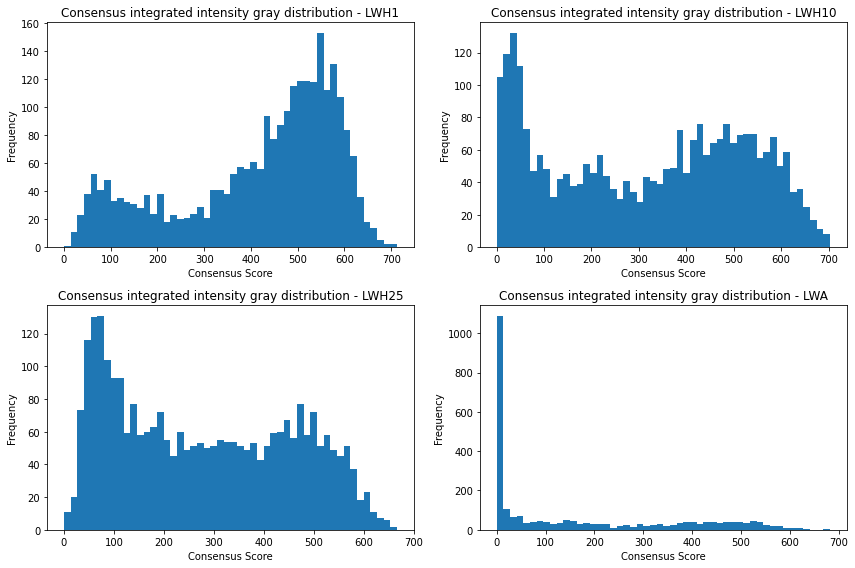

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()  # Make it easier to iterate

for i, condition in enumerate(scoring_conditions):
    df = scores_pd[scores_pd.condition_name == condition]
    df.consensus_score.plot(kind='hist', bins=50, 
                           title=f'Consensus integrated intensity gray distribution - {condition}',
                           ax=axes[i])
    axes[i].set_xlabel('Consensus Score')
    axes[i].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

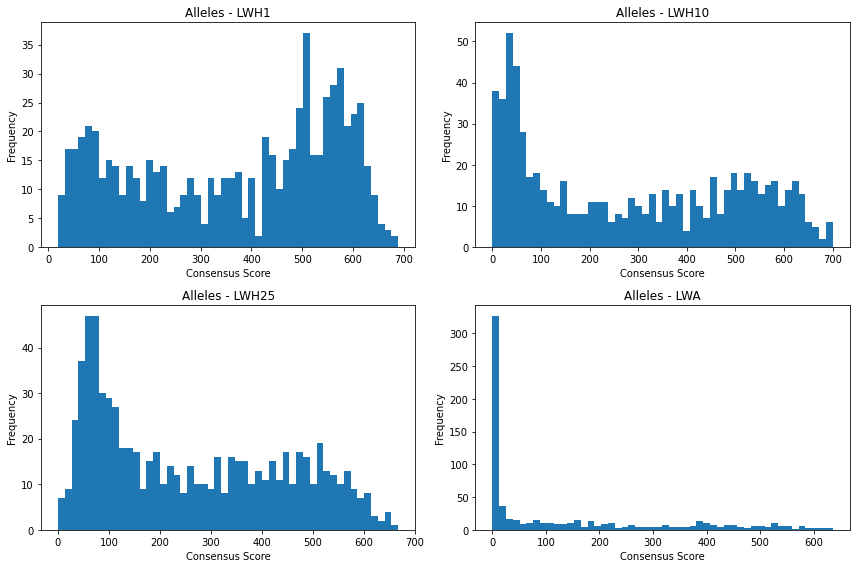

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()  # Make it easier to iterate

plot_df = scores_pd_nodup[scores_pd_nodup.db_mut_id != 0]

for i, condition in enumerate(scoring_conditions):
    df = plot_df[plot_df.condition_name == condition]
    df.consensus_score.plot(kind='hist', bins=50, 
                           title=f'Alleles - {condition}',
                           ax=axes[i])
    axes[i].set_xlabel('Consensus Score')
    axes[i].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

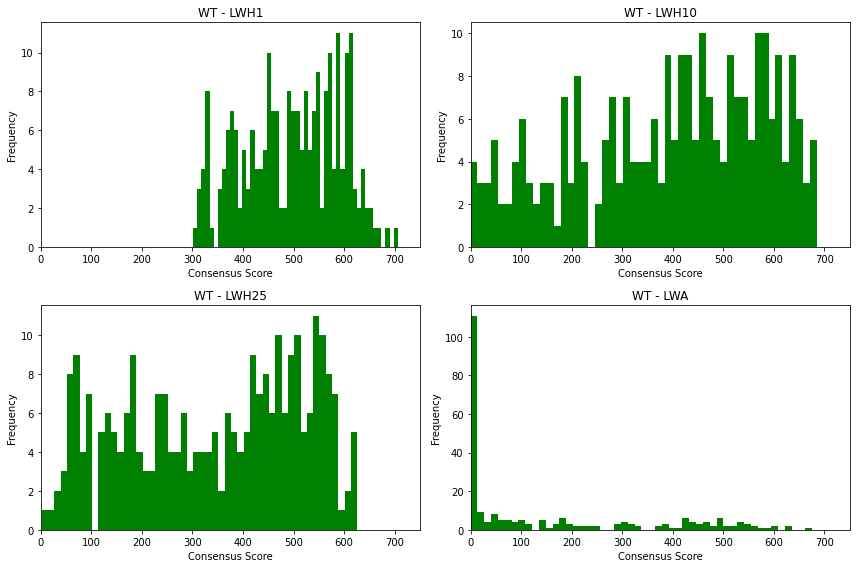

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()  # Make it easier to iterate

plot_df = scores_pd_nodup[scores_pd_nodup.db_mut_id == 0]

for i, condition in enumerate(scoring_conditions):
    df = plot_df[plot_df.condition_name == condition]
    df.consensus_score.plot(kind='hist', bins=50, 
                           title=f'WT - {condition}',
                           ax=axes[i],
                           color='green')
    axes[i].set_xlim(0, 750)  # Limit y-axis to better visualize WT distribution
    axes[i].set_xlabel('Consensus Score')
    axes[i].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

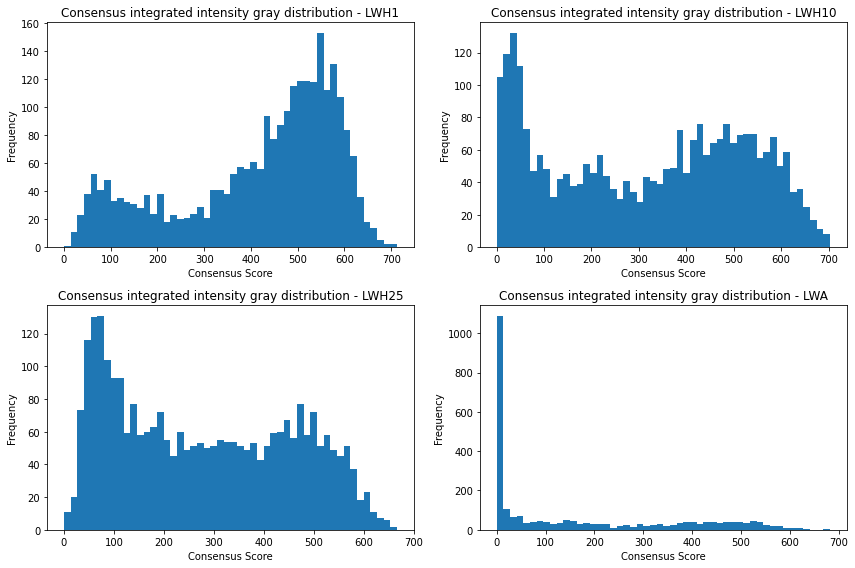

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()  # Make it easier to iterate

for i, condition in enumerate(scoring_conditions):
    df = scores_pd[scores_pd.condition_name == condition]
    df.consensus_score.plot(kind='hist', bins=50, 
                           title=f'Consensus integrated intensity gray distribution - {condition}',
                           ax=axes[i])
    axes[i].set_xlabel('Consensus Score')
    axes[i].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

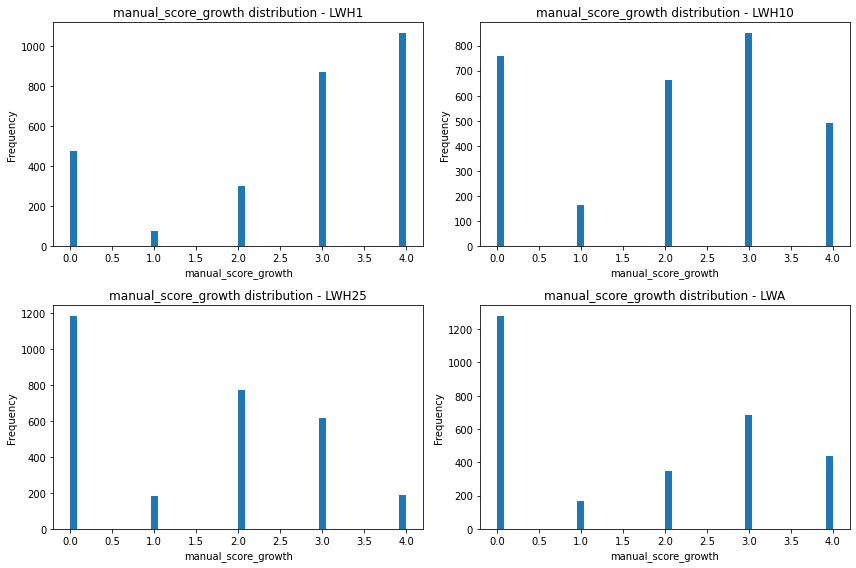

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()  # Make it easier to iterate

for i, condition in enumerate(scoring_conditions):
    df = scores_pd[scores_pd.condition_name == condition]
    df.manual_score_growth.plot(kind='hist', bins=50, 
                           title=f'manual_score_growth distribution - {condition}',
                           ax=axes[i])
    axes[i].set_xlabel('manual_score_growth')
    axes[i].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

In [ ]:
scores_pd[(scores_pd.symbol == 'ACSF3') &
          (scores_pd.aa_change == 'Arg471Trp') &
          (scores_pd.condition_name == 'LWH1')]

,scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,...,StarStatus,allele_0,db_group,db_condition_group,ppi_group,edge_group,seq_ad,seq_db,db_seq_final,aa_score
1340,VUSAPWT1B1r03_039,G05,VUSAPWT1B1r03_037_038_039_040_041_042,VUSAPWT1B1,r09,LWH1,1,False,152,NaN,...,1.0,ACSF3_Arg471Trp,71337.0_205772.0,71337.0_205772.0_LWH1_VUSAPWT1B1,152.0_71337.0_205772.0_VUSAPWT1B1,152.0_71337.0_VUSAPWT1B1,1,1,Y,247.910463
1345,VUSAPWT1B1r03_039,K05,VUSAPWT1B1r03_037_038_039_040_041_042,VUSAPWT1B1,r09,LWH1,1,False,54668,NaN,...,1.0,ACSF3_Arg471Trp,71337.0_205772.0,71337.0_205772.0_LWH1_VUSAPWT1B1,54668.0_71337.0_205772.0_VUSAPWT1B1,54668.0_71337.0_VUSAPWT1B1,1,1,Y,247.910463
13593,VUSAPWT6B1r03_010,I05,VUSAPWT6B1r03_007_008_009_010_011_012,VUSAPWT6B1,r15,LWH1,6,False,10441,NaN,...,1.0,ACSF3_Arg471Trp,71337.0_205772.0,71337.0_205772.0_LWH1_VUSAPWT6B1,10441.0_71337.0_205772.0_VUSAPWT6B1,10441.0_71337.0_VUSAPWT6B1,1,1,Y,255.208501


In [ ]:
# correlation between consensus score and manual score growth per media
print('correlation between consensus score and manual score growth per media:')
for condition in scoring_conditions:
    df = scores_pd[scores_pd.condition_name == condition]
    correlation = df['consensus_score'].corr(df['manual_score_growth'])
    print(f'for {condition}: {correlation:.2f}')

correlation between consensus score and manual score growth per media:
for LWH1: 0.86
for LWH10: 0.87
for LWH25: 0.83
for LWA: 0.85


Too many PPI groups (100) for legend - skipping legend


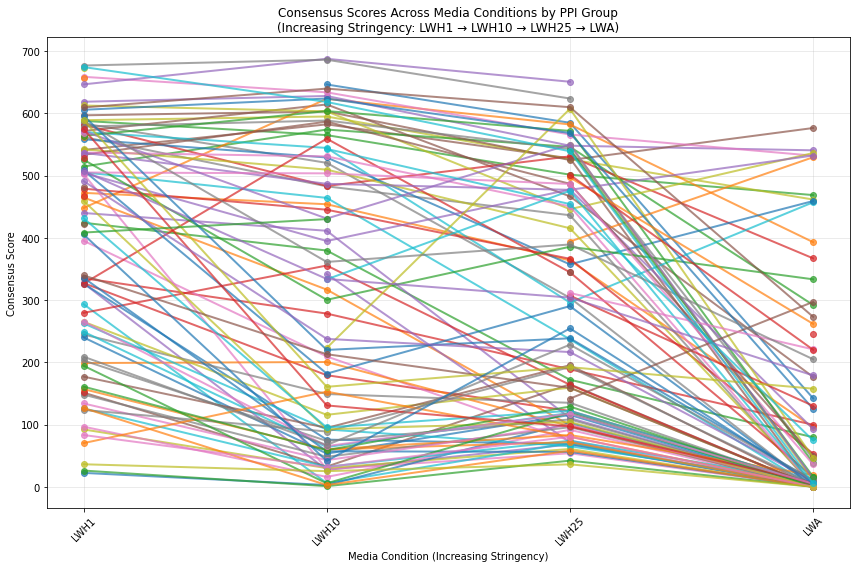

Plot created with 100 PPI groups as curves
X-axis order should be: ['LWH1', 'LWH10', 'LWH25', 'LWA']


In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

subset = scores_pd_nodup

# Get unique PPI groups and limit to first 20
unique_ppi_groups = scores_pd_nodup['ppi_group'].unique()[:100]

# Create a single figure
plt.figure(figsize=(12, 8))

# Plot each PPI group as a separate curve
for ppi_group in unique_ppi_groups:
    group_data = scores_pd_nodup[scores_pd_nodup['ppi_group'] == ppi_group].copy()
    
    # Ensure we have all scoring conditions and order them correctly
    group_data = group_data[group_data['condition_name'].isin(scoring_conditions)]
    
    # Create ordered categorical for proper x-axis ordering
    group_data['condition_name'] = pd.Categorical(
        group_data['condition_name'], 
        categories=scoring_conditions,  # This should be ['LWH1', 'LWH10', 'LWH25', 'LWA']
        ordered=True
    )
    
    # Sort by condition for proper line plot
    group_data = group_data.sort_values('condition_name')
    
    # Convert categorical to numeric positions for plotting
    group_data['condition_position'] = group_data['condition_name'].cat.codes
    
    # Plot consensus scores across conditions as a curve
    if len(group_data) > 0:
        plt.plot(group_data['condition_position'], group_data['consensus_score'], 
                marker='o', linewidth=2, markersize=6, alpha=0.7, label=ppi_group)

plt.xlabel('Media Condition (Increasing Stringency)')
plt.ylabel('Consensus Score')
plt.title('Consensus Scores Across Media Conditions by PPI Group\n(Increasing Stringency: LWH1 → LWH10 → LWH25 → LWA)')
plt.grid(True, alpha=0.3)

# Set the x-axis ticks and labels to match the scoring conditions
plt.xticks(range(len(scoring_conditions)), scoring_conditions, rotation=45)

# Add legend (you might want to limit this if there are too many groups)
if len(unique_ppi_groups) <= 20:
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)
else:
    print(f"Too many PPI groups ({len(unique_ppi_groups)}) for legend - skipping legend")


plt.tight_layout()
plt.show()

print(f"Plot created with {len(unique_ppi_groups)} PPI groups as curves")
print(f"X-axis order should be: {scoring_conditions}")

Too many PPI groups (1069) for legend - skipping legend


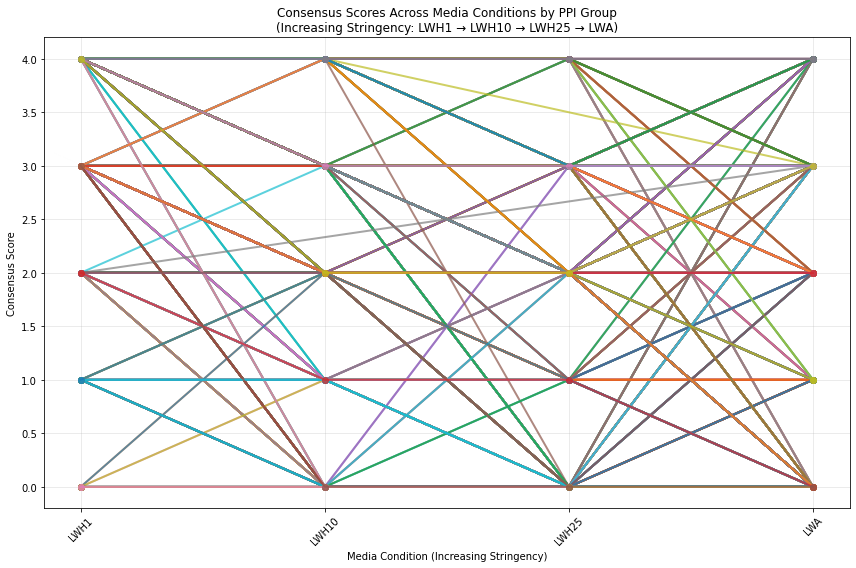

Plot created with 1069 PPI groups as curves
X-axis order should be: ['LWH1', 'LWH10', 'LWH25', 'LWA']


In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

subset = scores_pd_nodup

# Get unique PPI groups and limit to first 20
unique_ppi_groups = scores_pd_nodup['ppi_group'].unique()#[:200]

# Create a single figure
plt.figure(figsize=(12, 8))

# Plot each PPI group as a separate curve
for ppi_group in unique_ppi_groups:
    group_data = scores_pd_nodup[scores_pd_nodup['ppi_group'] == ppi_group].copy()
    
    # Ensure we have all scoring conditions and order them correctly
    group_data = group_data[group_data['condition_name'].isin(scoring_conditions)]
    
    # Create ordered categorical for proper x-axis ordering
    group_data['condition_name'] = pd.Categorical(
        group_data['condition_name'], 
        categories=scoring_conditions,  # This should be ['LWH1', 'LWH10', 'LWH25', 'LWA']
        ordered=True
    )
    
    # Sort by condition for proper line plot
    group_data = group_data.sort_values('condition_name')
    
    # Convert categorical to numeric positions for plotting
    group_data['condition_position'] = group_data['condition_name'].cat.codes
    
    # Plot consensus scores across conditions as a curve
    if len(group_data) > 0:
        plt.plot(group_data['condition_position'], group_data['manual_score_growth'], 
                marker='o', linewidth=2, markersize=6, alpha=0.7, label=ppi_group)

plt.xlabel('Media Condition (Increasing Stringency)')
plt.ylabel('Consensus Score')
plt.title('Consensus Scores Across Media Conditions by PPI Group\n(Increasing Stringency: LWH1 → LWH10 → LWH25 → LWA)')
plt.grid(True, alpha=0.3)

# Set the x-axis ticks and labels to match the scoring conditions
plt.xticks(range(len(scoring_conditions)), scoring_conditions, rotation=45)

# Add legend (you might want to limit this if there are too many groups)
if len(unique_ppi_groups) <= 20:
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)
else:
    print(f"Too many PPI groups ({len(unique_ppi_groups)}) for legend - skipping legend")


plt.tight_layout()
plt.show()

print(f"Plot created with {len(unique_ppi_groups)} PPI groups as curves")
print(f"X-axis order should be: {scoring_conditions}")

## summing score

In [ ]:
scores

scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,db_source_plate,db_source_well,ad_source_plate,ad_source_well,manual_score_growth,per_well_integrated_intensity_gray,contamination,automated_log2,consensus_score,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,db_group,db_condition_group,ppi_group,edge_group,seq_ad,seq_db,db_seq_final,aa_score,consensus_manual_score_growth
str,str,str,str,str,str,str,bool,i64,f64,i64,i64,str,str,str,str,f64,f64,bool,f64,f64,str,str,str,str,str,str,str,f64,f64,str,str,str,str,str,str,str,str,f64,f64
"""VUSAPWT1B1r01_001""","""A15""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,71704,null,11805,0,"""DisWTGDEh03""","""C04""","""CEGSint_Y8A_1""","""C01""",4.0,528.001331,false,9.174929,558.350679,"""SMURF2""","""SMAD3""",null,null,"""ENSG00000166949""",null,null,null,null,"""SMAD3""","""11805.0_0.0""","""11805.0_0.0_LW_VUSAPWT1B1""","""71704.0_11805.0_0.0_VUSAPWT1B1""","""71704.0_11805.0_VUSAPWT1B1""","""1""","""1""",null,509.083347,null
"""VUSAPWT1B1r01_001""","""A17""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,13662,null,70497,0,"""DisWTGDEh03""","""D04""","""CEGSint_Y8A_5""","""H07""",4.0,585.556892,false,9.311877,586.988591,"""CYSRT1""","""AGXT""",null,null,"""ENSG00000172482""",null,null,null,null,"""AGXT""","""70497.0_0.0""","""70497.0_0.0_LW_VUSAPWT1B1""","""13662.0_70497.0_0.0_VUSAPWT1B1""","""13662.0_70497.0_VUSAPWT1B1""","""1""","""1""",null,515.308517,null
"""VUSAPWT1B1r01_001""","""A23""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,11567,null,52920,0,"""DisWTGDEh03""","""A05""","""CEGSint_Y8A_5""","""A06""",4.0,572.135977,false,9.281086,578.211793,"""TAX1BP1""","""LITAF""",null,null,"""ENSG00000189067""",null,null,null,null,"""LITAF""","""52920.0_0.0""","""52920.0_0.0_LW_VUSAPWT1B1""","""11567.0_52920.0_0.0_VUSAPWT1B1""","""11567.0_52920.0_VUSAPWT1B1""","""1""","""1""",null,549.030745,null
"""VUSAPWT1B1r01_001""","""C03""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,12260,null,2651,0,"""DisWTGDEh02""","""G09""","""CEGSint_Y8A_7""","""B05""",4.0,476.3242,false,9.039808,509.349041,"""STX1A""","""CLN6""",null,null,"""ENSG00000128973""",null,null,null,null,"""CLN6""","""2651.0_0.0""","""2651.0_0.0_LW_VUSAPWT1B1""","""12260.0_2651.0_0.0_VUSAPWT1B1""","""12260.0_2651.0_VUSAPWT1B1""","""1""","""1""",null,494.701983,null
"""VUSAPWT1B1r01_001""","""C07""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,5441,null,71892,0,"""DisWTGDEh03""","""B03""","""CEGSint_Y8A_5""","""B07""",4.0,447.00917,false,8.957129,529.735972,"""PUF60""","""TH""",null,null,"""ENSG00000180176""",null,null,null,null,"""TH""","""71892.0_0.0""","""71892.0_0.0_LW_VUSAPWT1B1""","""5441.0_71892.0_0.0_VUSAPWT1B1""","""5441.0_71892.0_VUSAPWT1B1""","""1""","""1""",null,483.573543,null
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""VUSAPWT1B1r06_033""","""O13""","""VUSAPWT1B1r06_031_032_033_034_…","""VUSAPWT1B1""","""r12""","""LWAH1""","""1""",false,11922,null,2713,200832,"""VUSMutY8Dh018""","""B04""","""CEGSint_Y8A_6""","""D05""",2.0,48.005229,false,6.614787,null,"""MYOG""","""MLH1""","""Gly147Arg""","""439G>C""","""ENSG00000076242""","""CEGS2""","""3_Conflicting""",null,1.0,"""MLH1_Gly147Arg""","""2713.0_200832.0""","""2713.0_200832.0_LWAH1_VUSAPWT1…","""11922.0_2713.0_200832.0_VUSAPW…","""11922.0_2713.0_VUSAPWT1B1""","""1""","""1""","""Y""",2.590196,2.0
"""VUSAPWT1B1r06_033""","""O15""","""VUSAPWT1B1r06_031_032_033_034_…","""VUSAPWT1B1""","""r12""","""LWAH1""","""1""",false,9267,null,3535,201190,"""VUSMutY8Dh018""","""D11""","""CEGSint_Y8A_4""","""G10""",3.0,0.0,false,5.643856,null,"""CCDC155""","""EMD""","""Met1Val""","""1A>G""","""ENS

In [ ]:
scores.filter((pl.col("db_orf_id") == 7982) &
              (pl.col("db_mut_id") == 202799))

scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,db_source_plate,db_source_well,ad_source_plate,ad_source_well,manual_score_growth,per_well_integrated_intensity_gray,contamination,automated_log2,consensus_score,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,db_group,db_condition_group,ppi_group,edge_group,seq_ad,seq_db,db_seq_final,aa_score,consensus_manual_score_growth
str,str,str,str,str,str,str,bool,i64,f64,i64,i64,str,str,str,str,f64,f64,bool,f64,f64,str,str,str,str,str,str,str,f64,f64,str,str,str,str,str,str,str,str,f64,f64
"""VUSAPWT1B2r01_033""","""A09""","""VUSAPWT1B2r01_031_032_033_034_…","""VUSAPWT1B2""","""r07""","""LW""","""1""",false,2860,null,7982,202799,"""VUSMutY8Dh031""","""B04""","""CEGSint_Y8A_3""","""D10""",4.0,528.700667,false,9.176673,479.434651,"""PRTFDC1""","""HPRT1""","""Ile132Met""","""396T>G""","""ENSG00000165704""","""CEGS2""","""1_Pathogenic""",null,null,"""HPRT1_Ile132Met""","""7982.0_202799.0""","""7982.0_202799.0_LW_VUSAPWT1B2""","""2860.0_7982.0_202799.0_VUSAPWT…","""2860.0_7982.0_VUSAPWT1B2""","""1""","""1""","""Y""",560.985646,null
"""VUSAPWT1B2r01_033""","""C09""","""VUSAPWT1B2r01_031_032_033_034_…","""VUSAPWT1B2""","""r07""","""LW""","""1""",false,7982,null,7982,202799,"""VUSMutY8Dh031""","""B04""","""CEGSint_Y8A_6""","""G10""",4.0,500.537264,false,9.104696,477.098375,"""HPRT1""","""HPRT1""","""Ile132Met""","""396T>G""","""ENSG00000165704""","""CEGS2""","""1_Pathogenic""",null,null,"""HPRT1_Ile132Met""","""7982.0_202799.0""","""7982.0_202799.0_LW_VUSAPWT1B2""","""7982.0_7982.0_202799.0_VUSAPWT…","""7982.0_7982.0_VUSAPWT1B2""","""1""","""1""","""Y""",560.985646,null
"""VUSAPWT1B2r02_033""","""A09""","""VUSAPWT1B2r02_031_032_033_034_…","""VUSAPWT1B2""","""r08""","""LWA""","""1""",false,2860,null,7982,202799,"""VUSMutY8Dh031""","""B04""","""CEGSint_Y8A_3""","""D10""",4.0,0.0,false,5.643856,null,"""PRTFDC1""","""HPRT1""","""Ile132Met""","""396T>G""","""ENSG00000165704""","""CEGS2""","""1_Pathogenic""",null,null,"""HPRT1_Ile132Met""","""7982.0_202799.0""","""7982.0_202799.0_LWA_VUSAPWT1B2""","""2860.0_7982.0_202799.0_VUSAPWT…","""2860.0_7982.0_VUSAPWT1B2""","""1""","""1""","""Y""",87.204903,4.0
"""VUSAPWT1B2r02_033""","""C09""","""VUSAPWT1B2r02_031_032_033_034_…","""VUSAPWT1B2""","""r08""","""LWA""","""1""",false,7982,null,7982,202799,"""VUSMutY8Dh031""","""B04""","""CEGSint_Y8A_6""","""G10""",4.0,537.648388,false,9.198809,512.240864,"""HPRT1""","""HPRT1""","""Ile132Met""","""396T>G""","""ENSG00000165704""","""CEGS2""","""1_Pathogenic""",null,null,"""HPRT1_Ile132Met""","""7982.0_202799.0""","""7982.0_202799.0_LWA_VUSAPWT1B2""","""7982.0_7982.0_202799.0_VUSAPWT…","""7982.0_7982.0_VUSAPWT1B2""","""1""","""1""","""Y""",87.204903,4.0


In [ ]:
# !!!! using .sum() with null values returns 0

scores.filter(pl.col("condition_name").is_in(scoring_conditions)).filter((pl.col("db_orf_id") == 7982) &
              (pl.col("db_mut_id") == 202799)).group_by([
    'ad_orf_id', 'db_orf_id', 'db_mut_id', 'retest_batch'
]).agg([
    pl.col("condition_name").n_unique().alias("n_conditions"),
    pl.col("consensus_score").sum().alias("summed_consensus_score"),
    # Keep LWH1 scores separately
    pl.col("consensus_score").filter(pl.col("condition_name") == "LWH1").first().alias("lwh1_consensus_score")
])

ad_orf_id,db_orf_id,db_mut_id,retest_batch,n_conditions,summed_consensus_score,lwh1_consensus_score
i64,i64,i64,str,u32,f64,f64
2860,7982,202799,"""VUSAPWT1B2""",1,0.0,null
7982,7982,202799,"""VUSAPWT1B2""",1,512.240864,null


In [ ]:
print(scores.shape)
print('ppis', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ppi_group").n_unique()).item())
print('nodes', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("db_orf_id").n_unique()).item())
print('ads', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ad_orf_id").n_unique()).item())


(17535, 40)
ppis 2977
nodes 204
ads 633


In [ ]:
max_score = 750

In [ ]:
scoring_conditions

['LWH1', 'LWH10', 'LWH25', 'LWA']

In [ ]:
# Summing scores

# Keep a reference to original data with condition names
original_conditions = scores.filter(pl.col("condition_name").is_in(scoring_conditions)).select([
    'ad_orf_id', 'db_orf_id', 'db_mut_id', 'retest_batch', 'condition_name'
]).unique()

summed_scores = scores.filter(pl.col("condition_name").is_in(scoring_conditions))

summed_scores_pd = summed_scores.to_pandas()
print(summed_scores_pd.db_orf_id.nunique())

# First, sum adjusted scores across conditions for each variant + normalization test
summed_scores = summed_scores.group_by([
    'ad_orf_id', 'db_orf_id', 'db_mut_id', 'retest_batch'
]).agg([
    pl.col("condition_name").n_unique().alias("n_conditions"),
    pl.col("consensus_score").sum().alias("summed_consensus_score"),
    # Keep LWH1 scores separately
    pl.col("consensus_score").filter(pl.col("condition_name") == "LWH1").first().alias("lwh1_consensus_score")
])


# Normalization
summed_scores = summed_scores.with_columns(
    (pl.col("summed_consensus_score") / (len(scoring_conditions) * max_score)).alias("summed_consensus_score_normalized"),
    # Normalize LWH1 score
    (pl.col("lwh1_consensus_score") / max_score).alias("lwh1_consensus_score_normalized")
)



# # Normalization test
# summed_scores = summed_scores.group_by([
#     'ad_orf_id', 'db_orf_id', 'db_mut_id', 'retest_batch'
# ]).agg(
#     (pl.col("consensus_score").sum() / (len(scoring_conditions)*max_score)).alias("summed_consensus_score_normalized")
# )

summed_scores_pd = summed_scores.to_pandas()
print(summed_scores_pd.db_orf_id.nunique())

# Get WT scores (db_mut_id == 0) for normalization - now including LWH1
wt_scores = summed_scores.filter(pl.col("db_mut_id") == 0).select([
    "ad_orf_id", "db_orf_id", "retest_batch", 
    "summed_consensus_score", "summed_consensus_score_normalized",
    "lwh1_consensus_score", "lwh1_consensus_score_normalized"
]).rename({
    "summed_consensus_score": "wt_summed_score",
    "summed_consensus_score_normalized": "wt_summed_score_normalized",
    "lwh1_consensus_score": "wt_lwh1_score", 
    "lwh1_consensus_score_normalized": "wt_lwh1_score_normalized"
})

# Join variant scores with their corresponding WT scores
summed_scores = summed_scores.join(
    wt_scores, 
    on=["ad_orf_id", "db_orf_id", "retest_batch"], 
    how="left"
).filter(
    pl.col("wt_summed_score").is_not_null()  # Only keep variants that have a WT reference
)
# .select([
#     "ad_orf_id", "db_orf_id", "db_mut_id", "retest_batch", 
#     "summed_consensus_score", "wt_summed_score", 'condition_name'
# ])

# Join back with original to get condition names
summed_scores = summed_scores.join(
    original_conditions,
    on=["ad_orf_id", "db_orf_id", "db_mut_id", "retest_batch"],
    how="left"
)

summed_scores_pd = summed_scores.to_pandas()
print(summed_scores_pd.db_orf_id.nunique())

summed_scores = summed_scores.with_columns(
    pl.col("retest_batch").str.extract(r"VUSAPWT(\d)B\d+", 1).alias("assay_id")
)

summed_scores = summed_scores.with_columns(
    pl.concat_str([
        pl.col('ad_orf_id').cast(pl.String),
        pl.col('db_orf_id').cast(pl.String),
        pl.col('db_mut_id').cast(pl.String),
        pl.col('retest_batch').cast(pl.String)
    ], separator="_").alias("ppi_group")
)

summed_scores

204
204
195


ad_orf_id,db_orf_id,db_mut_id,retest_batch,n_conditions,summed_consensus_score,lwh1_consensus_score,summed_consensus_score_normalized,lwh1_consensus_score_normalized,wt_summed_score,wt_summed_score_normalized,wt_lwh1_score,wt_lwh1_score_normalized,condition_name,assay_id,ppi_group
i64,i64,i64,str,u32,f64,f64,f64,f64,f64,f64,f64,f64,str,str,str
14269,2920,0,"""VUSAPWT6B1""",4,1111.52325,548.388586,0.370508,0.731185,1111.52325,0.370508,548.388586,0.731185,"""LWA""","""6""","""14269_2920_0_VUSAPWT6B1"""
14269,2920,0,"""VUSAPWT6B1""",4,1111.52325,548.388586,0.370508,0.731185,1111.52325,0.370508,548.388586,0.731185,"""LWH10""","""6""","""14269_2920_0_VUSAPWT6B1"""
14269,2920,0,"""VUSAPWT6B1""",4,1111.52325,548.388586,0.370508,0.731185,1111.52325,0.370508,548.388586,0.731185,"""LWH1""","""6""","""14269_2920_0_VUSAPWT6B1"""
14269,2920,0,"""VUSAPWT6B1""",4,1111.52325,548.388586,0.370508,0.731185,1111.52325,0.370508,548.388586,0.731185,"""LWH25""","""6""","""14269_2920_0_VUSAPWT6B1"""
12387,6806,0,"""VUSAPWT1B2""",4,339.516997,null,0.113172,null,339.516997,0.113172,null,null,"""LWH10""","""1""","""12387_6806_0_VUSAPWT1B2"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
2845,52920,2688,"""VUSAPWT1B1""",4,1296.741536,458.837919,0.432247,0.611784,833.189232,0.27773,455.343474,0.607125,"""LWH10""","""1""","""2845_52920_2688_VUSAPWT1B1"""
53964,2713,200818,"""VUSAPWT1B1""",4,88.024838,48.337255,0.029342,0.06445,1288.531081,0.42951,569.921595,0.759895,"""LWH10""","""1""","""53964_2713_200818_VUSAPWT1B1"""
53964,2713,200818,"""VUSAPWT1B1""",4,88.024838,48.337255,0.029342,0.06445,1288.531081,0.42951,569.921595,0.759895,"""LWA""","""1""","""53964_2713_200818_VUSAPWT1B1"""


<Axes: >

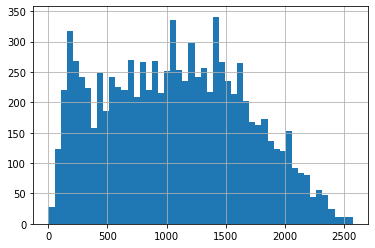

In [ ]:
summed_scores.to_pandas().summed_consensus_score.hist(bins=50)

In [ ]:
# # Summing scores

# # Keep a reference to original data with condition names
# original_conditions = scores.filter(pl.col("condition_name").is_in(scoring_conditions)).select([
#     'ad_orf_id', 'db_orf_id', 'db_mut_id', 'retest_batch', 'condition_name'
# ]).unique()

# summed_scores = scores.filter(pl.col("condition_name").is_in(scoring_conditions))

# summed_scores_pd = summed_scores.to_pandas()
# print(summed_scores_pd.db_orf_id.nunique())

# # First, sum adjusted scores across conditions for each variant + normalization test
# summed_scores = summed_scores.group_by([
#     'ad_orf_id', 'db_orf_id', 'db_mut_id', 'retest_batch'
# ]).agg([
#     pl.col("condition_name").n_unique().alias("n_conditions"),
#     pl.col("consensus_score").sum().alias("summed_consensus_score")
# ])

# # Normalization
# summed_scores = summed_scores.with_columns(
#     (pl.col("summed_consensus_score") / (pl.col("n_conditions") * max_score)).alias("summed_consensus_score_normalized")
# )



# # # Normalization test
# # summed_scores = summed_scores.group_by([
# #     'ad_orf_id', 'db_orf_id', 'db_mut_id', 'retest_batch'
# # ]).agg(
# #     (pl.col("consensus_score").sum() / (len(scoring_conditions)*max_score)).alias("summed_consensus_score_normalized")
# # )

# summed_scores_pd = summed_scores.to_pandas()
# print(summed_scores_pd.db_orf_id.nunique())

# # Get WT scores (db_mut_id == 0) for normalization
# wt_scores = summed_scores.filter(pl.col("db_mut_id") == 0).select([
#     "ad_orf_id", "db_orf_id", "retest_batch", "summed_consensus_score", "summed_consensus_score_normalized"
# ]).rename({
#     "summed_consensus_score": "wt_summed_score",
#     "summed_consensus_score_normalized": "wt_summed_score_normalized"
# })

# # Join variant scores with their corresponding WT scores
# summed_scores = summed_scores.join(
#     wt_scores, 
#     on=["ad_orf_id", "db_orf_id", "retest_batch"], 
#     how="left"
# ).filter(
#     pl.col("wt_summed_score").is_not_null()  # Only keep variants that have a WT reference
# )
# # .select([
# #     "ad_orf_id", "db_orf_id", "db_mut_id", "retest_batch", 
# #     "summed_consensus_score", "wt_summed_score", 'condition_name'
# # ])

# # Join back with original to get condition names
# summed_scores = summed_scores.join(
#     original_conditions,
#     on=["ad_orf_id", "db_orf_id", "db_mut_id", "retest_batch"],
#     how="left"
# )

# summed_scores_pd = summed_scores.to_pandas()
# print(summed_scores_pd.db_orf_id.nunique())

# summed_scores = summed_scores.with_columns(
#     pl.col("retest_batch").str.extract(r"VUSAPWT(\d)B\d+", 1).alias("assay_id")
# )

# summed_scores = summed_scores.with_columns(
#     pl.concat_str([
#         pl.col('ad_orf_id').cast(pl.String),
#         pl.col('db_orf_id').cast(pl.String),
#         pl.col('db_mut_id').cast(pl.String),
#         pl.col('retest_batch').cast(pl.String)
#     ], separator="_").alias("ppi_group")
# )

# summed_scores

In [ ]:
print(summed_scores.shape)
print('ppis', summed_scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ppi_group").n_unique()).item())
print('nodes', summed_scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("db_orf_id").n_unique()).item())
print('ads', summed_scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ad_orf_id").n_unique()).item())


(9259, 16)
ppis 2359
nodes 195
ads 543


In [ ]:
# cast all to same format
summed_scores = summed_scores.with_columns(
    pl.col("ad_orf_id").cast(pl.Float64).cast(pl.Int64).alias("ad_orf_id"),
    pl.col("db_orf_id").cast(pl.Float64).cast(pl.Int64).alias("db_orf_id"),
    pl.col("db_mut_id").cast(pl.Float64).cast(pl.Int64).alias("db_mut_id"),
    pl.col("assay_id").cast(pl.String).alias("assay_id"),
)

db_seq = db_seq.with_columns(
    pl.col("db_orf_id").cast(pl.Float64).cast(pl.Int64).alias("db_orf_id"),
    pl.col("db_mut_id").cast(pl.Float64).cast(pl.Int64).alias("db_mut_id"),
    pl.col("seq_db").cast(pl.String).alias("seq_db")
)

ad_seq = ad_seq.with_columns(
    pl.col("ad_orf_id").cast(pl.Float64).cast(pl.Int64).alias("ad_orf_id"),
    pl.col("seq_ad").cast(pl.String).alias("seq_ad"),
    pl.col("assay_id").cast(pl.String).alias("assay_id"),
)

summed_scores = summed_scores.join(ad_seq, on=["ad_orf_id", "assay_id"], how="left")
summed_scores = summed_scores.join(db_seq, on=["db_orf_id", "db_mut_id"], how="left")


# Filter to only keep interactions where both ad and db are confirmed
summed_scores = summed_scores.filter(
    (pl.col("seq_ad") == "1") & (pl.col("seq_db") == "1")
)
summed_scores

ad_orf_id,db_orf_id,db_mut_id,retest_batch,n_conditions,summed_consensus_score,lwh1_consensus_score,summed_consensus_score_normalized,lwh1_consensus_score_normalized,wt_summed_score,wt_summed_score_normalized,wt_lwh1_score,wt_lwh1_score_normalized,condition_name,assay_id,ppi_group,seq_ad,seq_db
i64,i64,i64,str,u32,f64,f64,f64,f64,f64,f64,f64,f64,str,str,str,str,str
14269,2920,0,"""VUSAPWT6B1""",4,1111.52325,548.388586,0.370508,0.731185,1111.52325,0.370508,548.388586,0.731185,"""LWA""","""6""","""14269_2920_0_VUSAPWT6B1""","""1""","""1"""
14269,2920,0,"""VUSAPWT6B1""",4,1111.52325,548.388586,0.370508,0.731185,1111.52325,0.370508,548.388586,0.731185,"""LWH10""","""6""","""14269_2920_0_VUSAPWT6B1""","""1""","""1"""
14269,2920,0,"""VUSAPWT6B1""",4,1111.52325,548.388586,0.370508,0.731185,1111.52325,0.370508,548.388586,0.731185,"""LWH1""","""6""","""14269_2920_0_VUSAPWT6B1""","""1""","""1"""
14269,2920,0,"""VUSAPWT6B1""",4,1111.52325,548.388586,0.370508,0.731185,1111.52325,0.370508,548.388586,0.731185,"""LWH25""","""6""","""14269_2920_0_VUSAPWT6B1""","""1""","""1"""
12387,6806,0,"""VUSAPWT1B2""",4,339.516997,null,0.113172,null,339.516997,0.113172,null,null,"""LWH10""","""1""","""12387_6806_0_VUSAPWT1B2""","""1""","""1"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
2845,52920,2688,"""VUSAPWT1B1""",4,1296.741536,458.837919,0.432247,0.611784,833.189232,0.27773,455.343474,0.607125,"""LWH10""","""1""","""2845_52920_2688_VUSAPWT1B1""","""1""","""1"""
53964,2713,200818,"""VUSAPWT1B1""",4,88.024838,48.337255,0.029342,0.06445,1288.531081,0.42951,569.921595,0.759895,"""LWH10""","""1""","""53964_2713_200818_VUSAPWT1B1""","""1""","""1"""
53964,2713,200818,"""VUSAPWT1B1""",4,88.024838,48.337255,0.029342,0.06445,1288.531081,0.42951,569.921595,0.759895,"""LWA""","""1""","""53964_2713_200818_VUSAPWT1B1""","""1""","""1"""


In [ ]:
# map ad_orf_id to ad_symbol
mapping_file = pd.read_csv(f"{inputs_dir}/cp_files/mapping_y2h.csv")
mapping_file.dropna(subset=['ad_orf_id'], inplace=True)
mapping_dict = mapping_file.set_index('ad_orf_id')['ad_symbol'].to_dict()

summed_scores = summed_scores.with_columns(
    pl.col("ad_orf_id").replace_strict(mapping_dict, default=None).alias("ad_symbol")
)
summed_scores

ad_orf_id,db_orf_id,db_mut_id,retest_batch,n_conditions,summed_consensus_score,lwh1_consensus_score,summed_consensus_score_normalized,lwh1_consensus_score_normalized,wt_summed_score,wt_summed_score_normalized,wt_lwh1_score,wt_lwh1_score_normalized,condition_name,assay_id,ppi_group,seq_ad,seq_db,ad_symbol
i64,i64,i64,str,u32,f64,f64,f64,f64,f64,f64,f64,f64,str,str,str,str,str,str
14269,2920,0,"""VUSAPWT6B1""",4,1111.52325,548.388586,0.370508,0.731185,1111.52325,0.370508,548.388586,0.731185,"""LWA""","""6""","""14269_2920_0_VUSAPWT6B1""","""1""","""1""","""ZNF774"""
14269,2920,0,"""VUSAPWT6B1""",4,1111.52325,548.388586,0.370508,0.731185,1111.52325,0.370508,548.388586,0.731185,"""LWH10""","""6""","""14269_2920_0_VUSAPWT6B1""","""1""","""1""","""ZNF774"""
14269,2920,0,"""VUSAPWT6B1""",4,1111.52325,548.388586,0.370508,0.731185,1111.52325,0.370508,548.388586,0.731185,"""LWH1""","""6""","""14269_2920_0_VUSAPWT6B1""","""1""","""1""","""ZNF774"""
14269,2920,0,"""VUSAPWT6B1""",4,1111.52325,548.388586,0.370508,0.731185,1111.52325,0.370508,548.388586,0.731185,"""LWH25""","""6""","""14269_2920_0_VUSAPWT6B1""","""1""","""1""","""ZNF774"""
12387,6806,0,"""VUSAPWT1B2""",4,339.516997,null,0.113172,null,339.516997,0.113172,null,null,"""LWH10""","""1""","""12387_6806_0_VUSAPWT1B2""","""1""","""1""","""NAB2"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
2845,52920,2688,"""VUSAPWT1B1""",4,1296.741536,458.837919,0.432247,0.611784,833.189232,0.27773,455.343474,0.607125,"""LWH10""","""1""","""2845_52920_2688_VUSAPWT1B1""","""1""","""1""","""REEP6"""
53964,2713,200818,"""VUSAPWT1B1""",4,88.024838,48.337255,0.029342,0.06445,1288.531081,0.42951,569.921595,0.759895,"""LWH10""","""1""","""53964_2713_200818_VUSAPWT1B1""","""1""","""1""","""NFIX"""
53964,2713,200818,"""VUSAPWT1B1""",4,88.024838,48.337255,0.029342,0.06445,1288.531081,0.42951,569.921595,0.759895,"""LWA""","""1""","""53964_2713_200818_VUSAPWT1B1""","""1""","""1""","""NFIX"""


In [ ]:
meta_outputs

'../../../1_allele_collection/3_outputs'

In [ ]:
# Append metadata and write out file
metadata = pl.read_csv(f"{meta_outputs}/slim_metadata.csv").rename({
    "orf_id": "db_orf_id",
    "mut_id": "db_mut_id"
})

summed_scores = summed_scores.join(metadata, on=["db_orf_id", "db_mut_id"], how="left")
summed_scores

ad_orf_id,db_orf_id,db_mut_id,retest_batch,n_conditions,summed_consensus_score,lwh1_consensus_score,summed_consensus_score_normalized,lwh1_consensus_score_normalized,wt_summed_score,wt_summed_score_normalized,wt_lwh1_score,wt_lwh1_score_normalized,condition_name,assay_id,ppi_group,seq_ad,seq_db,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0
i64,i64,i64,str,u32,f64,f64,f64,f64,f64,f64,f64,f64,str,str,str,str,str,str,str,str,str,str,str,str,f64,f64,str
14269,2920,0,"""VUSAPWT6B1""",4,1111.52325,548.388586,0.370508,0.731185,1111.52325,0.370508,548.388586,0.731185,"""LWA""","""6""","""14269_2920_0_VUSAPWT6B1""","""1""","""1""","""ZNF774""","""GFAP""",null,null,"""ENSG00000131095""",null,null,null,null,"""GFAP"""
14269,2920,0,"""VUSAPWT6B1""",4,1111.52325,548.388586,0.370508,0.731185,1111.52325,0.370508,548.388586,0.731185,"""LWH10""","""6""","""14269_2920_0_VUSAPWT6B1""","""1""","""1""","""ZNF774""","""GFAP""",null,null,"""ENSG00000131095""",null,null,null,null,"""GFAP"""
14269,2920,0,"""VUSAPWT6B1""",4,1111.52325,548.388586,0.370508,0.731185,1111.52325,0.370508,548.388586,0.731185,"""LWH1""","""6""","""14269_2920_0_VUSAPWT6B1""","""1""","""1""","""ZNF774""","""GFAP""",null,null,"""ENSG00000131095""",null,null,null,null,"""GFAP"""
14269,2920,0,"""VUSAPWT6B1""",4,1111.52325,548.388586,0.370508,0.731185,1111.52325,0.370508,548.388586,0.731185,"""LWH25""","""6""","""14269_2920_0_VUSAPWT6B1""","""1""","""1""","""ZNF774""","""GFAP""",null,null,"""ENSG00000131095""",null,null,null,null,"""GFAP"""
12387,6806,0,"""VUSAPWT1B2""",4,339.516997,null,0.113172,null,339.516997,0.113172,null,null,"""LWH10""","""1""","""12387_6806_0_VUSAPWT1B2""","""1""","""1""","""NAB2""","""PLOD3""",null,null,"""ENSG00000106397""",null,null,null,null,"""PLOD3"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
2845,52920,2688,"""VUSAPWT1B1""",4,1296.741536,458.837919,0.432247,0.611784,833.189232,0.27773,455.343474,0.607125,"""LWH10""","""1""","""2845_52920_2688_VUSAPWT1B1""","""1""","""1""","""REEP6""","""LITAF""","""Asn30Tyr""","""88A>T""","""ENSG00000189067""","""Edgotyping3""","""4_VUS""",null,2.0,"""LITAF_Asn30Tyr"""
53964,2713,200818,"""VUSAPWT1B1""",4,88.024838,48.337255,0.029342,0.06445,1288.531081,0.42951,569.921595,0.759895,"""LWH10""","""1""","""53964_2713_200818_VUSAPWT1B1""","""1""","""1""","""NFIX""","""MLH1""","""Leu73Arg""","""218T>G""","""ENSG00000076242""","""CEGS2""","""1_Pathogenic""",null,2.0,"""MLH1_Leu73Arg"""
53964,2713,200818,"""VUSAPWT1B1""",4,88.024838,48.337255,0.029342,0.06445,1288.531081,0.42951,569.921595,0.759895,"""LWA""","""1""","""53964_2713_200818_VUSAPWT1B1""","""1""","""1""","""NFIX""","""MLH1""","""Leu73Arg""","""218T>G""","""ENSG00000076242""","""CEGS2""","""1_Pathogenic""",null,2.0,"""MLH1_Leu73Arg"""


In [ ]:
print(summed_scores.shape)
print('ppis', summed_scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ppi_group").n_unique()).item())

(9259, 28)
ppis 2359


In [ ]:
manual_scores

ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,condition_name,retest_batch,media_control,consensus_score,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,assay_id,db_group,db_condition_group,ppi_group,aa_score,adjusted_score,seq_ad,seq_db,db_sequenced,db_sequence_confirmation_class,consensus_manual_score_growth
i64,str,i64,i64,str,str,bool,f64,str,str,str,str,str,str,str,f64,f64,str,str,str,str,str,f64,f64,i64,i64,f64,f64,f64
100014221,null,71001,205675,"""LWH25""","""VUSAPWT2B1""",false,0.0,"""WFDC12""","""UBQLN2""","""Pro506Thr""","""1516C>A""","""ENSG00000188021""","""CEGS2""","""1_Pathogenic""",null,1.0,"""UBQLN2_Pro506Thr""","""2""","""71001.0_205675.0""","""71001.0_205675.0_LWH25_VUSAPWT…","""100014221.0_71001.0_205675.0_V…",0.0,0.0,1,1,1.0,1.0,0.0
7845,null,4515,0,"""LWH1""","""VUSAPWT1B2""",false,3.0,"""AGTRAP""","""PNPO""",null,null,"""ENSG00000108439""",null,null,null,null,"""PNPO""","""1""","""4515.0_0.0""","""4515.0_0.0_LWH1_VUSAPWT1B2""","""7845.0_4515.0_0.0_VUSAPWT1B2""",0.0,3.0,1,1,null,null,3.0
100016069,null,100016069,2617,"""LWH10""","""VUSAPWT1B1""",false,0.0,"""KCNJ2""","""KCNJ2""","""Val86Phe""","""256G>T""","""ENSG00000123700""","""Edgotyping3""","""4_VUS""",null,2.0,"""KCNJ2_Val86Phe""","""1""","""100016069.0_2617.0""","""100016069.0_2617.0_LWH10_VUSAP…","""100016069.0_100016069.0_2617.0…",0.0,0.0,1,1,1.0,2.0,0.0
446,null,4862,0,"""LWH25""","""VUSAPWT6B1""",false,0.0,"""EBAG9""","""SLC30A2""",null,null,"""ENSG00000158014""",null,null,null,null,"""SLC30A2""","""6""","""4862.0_0.0""","""4862.0_0.0_LWH25_VUSAPWT6B1""","""446.0_4862.0_0.0_VUSAPWT6B1""",0.0,0.0,1,1,null,null,0.0
100016009,null,8416,216651,"""LWAH1""","""VUSAPWT1B2""",false,0.0,"""ZRANB1""","""DCX""","""Ile214Thr""","""641T>C""","""ENSG00000077279""","""CEGS2""","""1_Pathogenic""",null,1.0,"""DCX_Ile214Thr""","""1""","""8416.0_216651.0""","""8416.0_216651.0_LWAH1_VUSAPWT1…","""100016009.0_8416.0_216651.0_VU…",0.0,0.0,1,1,1.0,1.0,0.0
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
8359,null,11805,2117,"""LWA""","""VUSAPWT1B1""",false,null,"""CCDC33""","""SMAD3""","""Ile87Thr""","""260T>C""","""ENSG00000166949""","""Edgotyping3""","""4_VUS""",null,1.0,"""SMAD3_Ile87Thr""","""1""","""11805.0_2117.0""","""11805.0_2117.0_LWA_VUSAPWT1B1""","""8359.0_11805.0_2117.0_VUSAPWT1…",0.0,null,1,1,1.0,1.0,null
6811,null,4723,201750,"""LWH1""","""VUSAPWT1B1""",false,2.0,"""MAD1L1""","""TPM1""","""Asn279His""","""835A>C""","""ENSG00000140416""","""CEGS2""","""4_VUS""",null,2.0,"""TPM1_Asn279His""","""1""","""4723.0_201750.0""","""4723.0_201750.0_LWH1_VUSAPWT1B…","""6811.0_4723.0_201750.0_VUSAPWT…",0.0,2.0,1,1,1.0,1.0,2.0
13600,null,70497,3881,"""LWH1""","""VUSAPWT1B1""",false,1.0,"""KRT34""","""AGXT""","""Ile340Met""","""1020A>G""","""ENSG00000172482""","""Edgotyping3""","""2_Benign""",0.192825,2.0,"""AGXT_Ile340Met""","""1""","""70497.0_3881.0""","""70497.0_3881.0_LWH1_VUSAPWT1B1""","""13600.0_70497.0_3881.0_VUSAPWT…",0.0,1.0,1,1,1.0,1.0,1.0


In [ ]:
# Create a filtered version for saving - keep only one row per unique combination
summed_scores_for_export = summed_scores.unique(subset=["ad_orf_id", "db_orf_id", "db_mut_id", "retest_batch"])
summed_scores_for_export
# Write the filtered version (with only 1 row per combination)
summed_scores_for_export.write_csv(f"{outputs_dir}/4_automated_normalized_consensus_scores.csv")

In [ ]:
summed_scores_for_export.select(pl.col('symbol')).n_unique()

192

In [ ]:
manual_scores = pd.read_csv('../3_outputs/sqY2H/4_normalized_consensus_scores.csv')
# manual_scores.unique(subset=["ad_orf_id", "db_orf_id", "db_mut_id", "retest_batch"])

# keep only auto_df where there is at least one matched reference-variant set
auto_df_pl = pl.from_pandas(manual_scores)

orfs_with_alleles = auto_df_pl.filter(pl.col("db_mut_id") != 0).select("db_orf_id").unique().to_series().to_list()
orfs = auto_df_pl.filter(pl.col("db_mut_id") == 0).select("db_orf_id").unique().to_series().to_list()

complete_orf_pairs = [i for i in orfs if i in orfs_with_alleles]
auto_df_pl = auto_df_pl.filter(pl.col("db_orf_id").is_in(complete_orf_pairs))
genes = auto_df_pl.select("db_orf_id").to_series().unique().to_list()


auto_df_pl.select(pl.col('db_orf_id')).n_unique()

84

In [ ]:
summed_scores_for_export_pd = summed_scores_for_export.to_pandas()

In [ ]:
summed_scores_for_export_pd['log2fc'] = np.log2((summed_scores_for_export_pd['summed_consensus_score'] + 1) / (summed_scores_for_export_pd['wt_summed_score'] + 1))
summed_scores_for_export_pd

,ad_orf_id,db_orf_id,db_mut_id,retest_batch,n_conditions,summed_consensus_score,lwh1_consensus_score,summed_consensus_score_normalized,lwh1_consensus_score_normalized,wt_summed_score,...,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,log2fc
0,14441,52920,2686,VUSAPWT1B1,4,1359.299064,542.828128,0.453100,0.723771,1230.273887,...,LITAF,Pro39Ser,115C>T,ENSG00000189067,Edgotyping3,4_VUS,NaN,1.0,LITAF_Pro39Ser,0.143772
1,12260,2651,0,VUSAPWT1B1,4,634.149032,327.398046,0.211383,0.436531,634.149032,...,CLN6,None,None,ENSG00000128973,None,None,NaN,NaN,CLN6,0.000000
2,71163,52920,2681,VUSAPWT2B1,4,290.952620,193.119939,0.096984,0.257493,1247.363108,...,LITAF,Pro84Leu,251C>T,ENSG00000189067,Edgotyping3,4_VUS,NaN,2.0,LITAF_Pro84Leu,-2.096231
3,12920,7323,216370,VUSAPWT2B1,4,318.705886,178.802290,0.106235,0.238403,658.327792,...,PMP22,Gly150Cys,448G>T,ENSG00000109099,CEGS2,3_Conflicting,NaN,1.0,PMP22_Gly150Cys,-1.044251
4,14441,52920,2675,VUSAPWT1B1,4,1373.111809,578.396104,0.457704,0.771195,1230.273887,...,LITAF,Trp116Gly,346T>G,ENSG00000189067,Edgotyping3,1_Pathogenic,NaN,1.0,LITAF_Trp116Gly,0.158348
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2354,52785,54082,0,VUSAPWT2B1,3,642.499697,NaN,0.214167,NaN,642.499697,...,PRPF31,None,None,ENSG00000105618,None,None,NaN,NaN,PRPF31,0.000000
2355,54341,2713,200850,VUSAPWT1B1,4,548.592826,335.080077,0.182864,0.446773,977.437927,...,MLH1,Ser295Thr,884G>C,ENSG00000076242,CEGS2,4_VUS,NaN,3.0,MLH1_Ser295Thr,-0.832117
2356,10441,71337,205770,VUSAPWT6B1,4,275.321574,184.775495,0.091774,0.246367,2002.449417,...,ACSF3,Glu359Lys,1075G>A,ENSG00000176715,Edgotyping3,1_Pathogenic,0.001167,2.0,ACSF3_Glu359Lys,-2.858066
2357,439,52920,2682,VUSAPWT6B1,4,1036.794373,468.464070,0.345598,0.624619,167.461769,...,LITAF,Val81Met,241G>A,ENSG00000189067,Edgotyping3,2_Benign,NaN,2.0,LITAF_Val81Met,2.623027


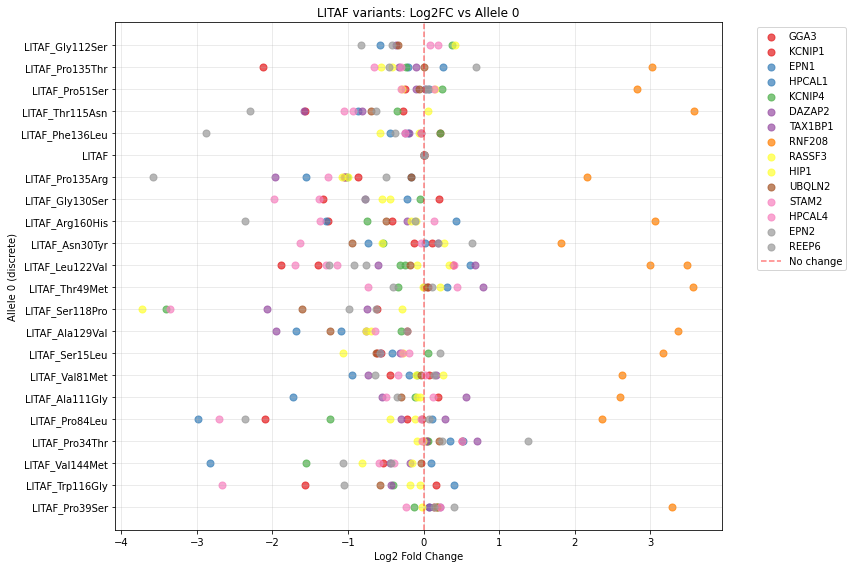

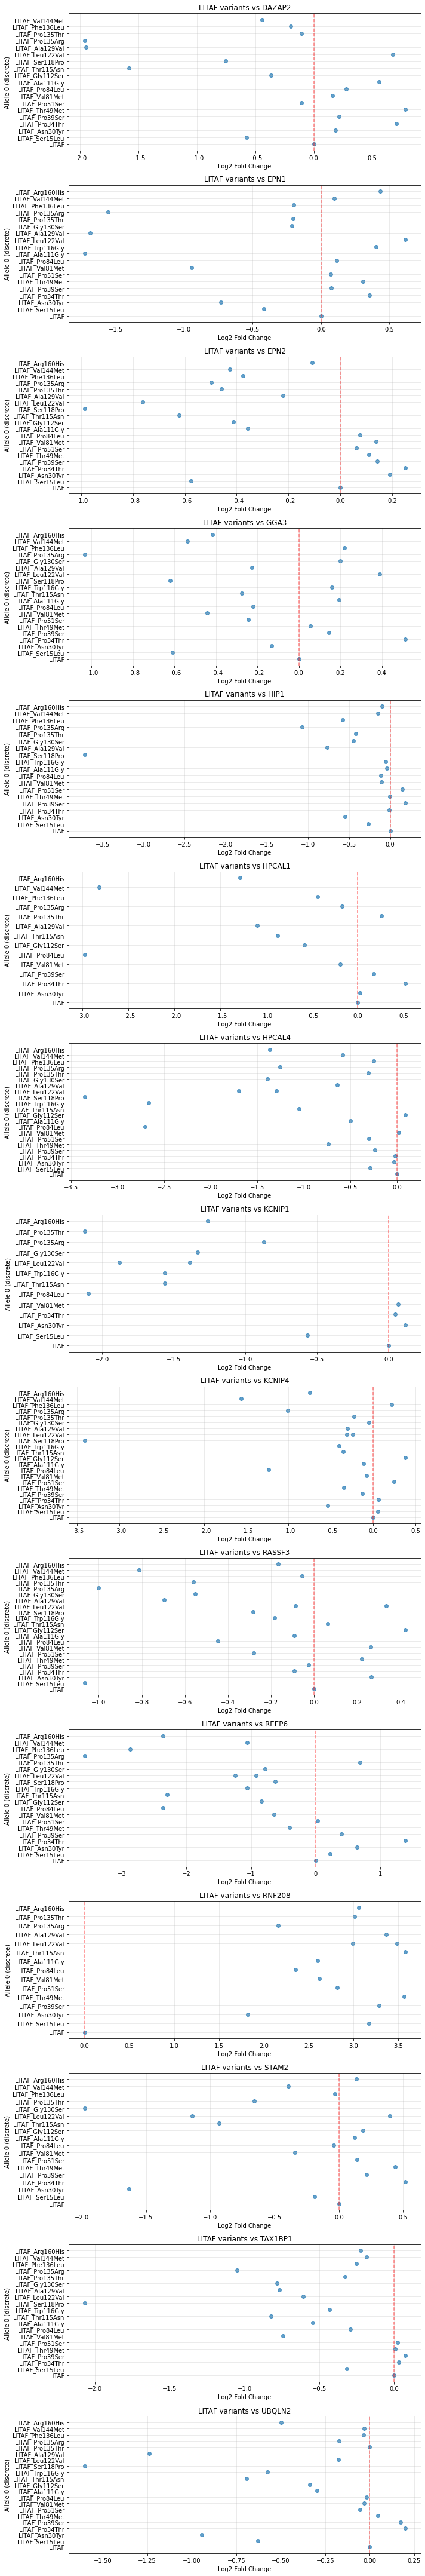

Figure saved to: ../3_outputs/sqY2H/LITAF_variants_log2fc_vs_allele0_subplots.png


In [ ]:
# Filter for LITAF data
litaf = summed_scores_for_export_pd[summed_scores_for_export_pd.symbol == 'LITAF']

# Create scatter plot with log2fc on x-axis and allele_0 on y-axis
plt.figure(figsize=(12, 8))

# Get unique interactors for color coding
unique_interactors = litaf['ad_symbol'].unique()
colors = plt.cm.Set1(np.linspace(0, 1, len(unique_interactors)))

for i, interactor in enumerate(unique_interactors):
    interactor_data = litaf[litaf['ad_symbol'] == interactor]
    plt.scatter(interactor_data['log2fc'], interactor_data['allele_0'], 
               alpha=0.7, label=interactor, color=colors[i], s=50)

# Add vertical line at x=0 for reference
plt.axvline(x=0, color='red', linestyle='--', alpha=0.5, label='No change')

plt.xlabel('Log2 Fold Change')
plt.ylabel('Allele 0 (discrete)')
plt.title('LITAF variants: Log2FC vs Allele 0')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
# ...existing code...

# Alternative: Create separate plots for each interactor with sorted alleles
unique_interactors = sorted(litaf['ad_symbol'].unique())
n_interactors = len(unique_interactors)

# Sort allele_0 values by position number (extract number from strings like "LITAF_Arg12Pro")
import re

def extract_position(allele_name):
    """Extract position number from allele name like 'LITAF_Arg12Pro'"""
    match = re.search(r'(\d+)', allele_name)
    return int(match.group(1)) if match else 0

unique_allele_0 = sorted(litaf['allele_0'].unique(), key=extract_position)

# Create a mapping from allele name to sorted position
allele_to_position = {allele: i for i, allele in enumerate(unique_allele_0)}

fig, axes = plt.subplots(n_interactors, 1, figsize=(10, 4*n_interactors))

# If only one interactor, make sure axes is iterable
if n_interactors == 1:
    axes = [axes]

for i, interactor in enumerate(unique_interactors):
    interactor_data = litaf[litaf['ad_symbol'] == interactor].copy()
    
    # Only include alleles that have data for this specific interactor
    available_alleles = interactor_data['allele_0'].unique()
    
    # Filter and sort only the alleles that have data for this interactor
    available_alleles_sorted = sorted(available_alleles, key=extract_position)
    
    # Create a mapping from available allele names to their sorted positions
    allele_to_position = {allele: j for j, allele in enumerate(available_alleles_sorted)}
    
    # Map allele names to their sorted positions
    interactor_data['allele_position'] = interactor_data['allele_0'].map(allele_to_position)
    
    # Create scatter plot using the mapped positions
    axes[i].scatter(interactor_data['log2fc'], interactor_data['allele_position'], alpha=0.7)
    
    # Add vertical line at x=0 for reference
    axes[i].axvline(x=0, color='red', linestyle='--', alpha=0.5)
    
    # Customize plot
    axes[i].set_xlabel('Log2 Fold Change')
    axes[i].set_ylabel('Allele 0 (discrete)')
    axes[i].set_title(f'LITAF variants vs {interactor}')
    axes[i].grid(True, alpha=0.3)
    
    # Set y-tick labels to show only the alleles available for this interactor
    axes[i].set_yticks(range(len(available_alleles_sorted)))
    axes[i].set_yticklabels(available_alleles_sorted, ha='right')

plt.tight_layout()

# Save the figure
plt.savefig(f"{outputs_dir}/LITAF_variants_log2fc_vs_allele0_subplots.png", 
            dpi=300, bbox_inches='tight')
plt.savefig(f"{outputs_dir}/LITAF_variants_log2fc_vs_allele0_subplots.pdf", 
            bbox_inches='tight')
plt.show()

print(f"Figure saved to: {outputs_dir}/LITAF_variants_log2fc_vs_allele0_subplots.png")

In [ ]:
summed_scores_for_export_pd_pl = pl.DataFrame(summed_scores_for_export_pd)
summed_scores_for_export_pd_pl

ad_orf_id,db_orf_id,db_mut_id,retest_batch,n_conditions,summed_consensus_score,lwh1_consensus_score,summed_consensus_score_normalized,lwh1_consensus_score_normalized,wt_summed_score,wt_summed_score_normalized,wt_lwh1_score,wt_lwh1_score_normalized,condition_name,assay_id,ppi_group,seq_ad,seq_db,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,log2fc
i64,i64,i64,str,u32,f64,f64,f64,f64,f64,f64,f64,f64,str,str,str,str,str,str,str,str,str,str,str,str,f64,f64,str,f64
14441,52920,2686,"""VUSAPWT1B1""",4,1359.299064,542.828128,0.4531,0.723771,1230.273887,0.410091,552.494468,0.736659,"""LWH10""","""1""","""14441_52920_2686_VUSAPWT1B1""","""1""","""1""","""GGA3""","""LITAF""","""Pro39Ser""","""115C>T""","""ENSG00000189067""","""Edgotyping3""","""4_VUS""",null,1.0,"""LITAF_Pro39Ser""",0.143772
12260,2651,0,"""VUSAPWT1B1""",4,634.149032,327.398046,0.211383,0.436531,634.149032,0.211383,327.398046,0.436531,"""LWH10""","""1""","""12260_2651_0_VUSAPWT1B1""","""1""","""1""","""STX1A""","""CLN6""",null,null,"""ENSG00000128973""",null,null,null,null,"""CLN6""",0.0
71163,52920,2681,"""VUSAPWT2B1""",4,290.95262,193.119939,0.096984,0.257493,1247.363108,0.415788,523.020282,0.69736,"""LWH25""","""2""","""71163_52920_2681_VUSAPWT2B1""","""1""","""1""","""KCNIP1""","""LITAF""","""Pro84Leu""","""251C>T""","""ENSG00000189067""","""Edgotyping3""","""4_VUS""",null,2.0,"""LITAF_Pro84Leu""",-2.096231
12920,7323,216370,"""VUSAPWT2B1""",4,318.705886,178.80229,0.106235,0.238403,658.327792,0.219443,399.65524,0.532874,"""LWH1""","""2""","""12920_7323_216370_VUSAPWT2B1""","""1""","""1""","""SDC4""","""PMP22""","""Gly150Cys""","""448G>T""","""ENSG00000109099""","""CEGS2""","""3_Conflicting""",null,1.0,"""PMP22_Gly150Cys""",-1.044251
14441,52920,2675,"""VUSAPWT1B1""",4,1373.111809,578.396104,0.457704,0.771195,1230.273887,0.410091,552.494468,0.736659,"""LWA""","""1""","""14441_52920_2675_VUSAPWT1B1""","""1""","""1""","""GGA3""","""LITAF""","""Trp116Gly""","""346T>G""","""ENSG00000189067""","""Edgotyping3""","""1_Pathogenic""",null,1.0,"""LITAF_Trp116Gly""",0.158348
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
52785,54082,0,"""VUSAPWT2B1""",3,642.499697,null,0.214167,null,642.499697,0.214167,null,null,"""LWH10""","""2""","""52785_54082_0_VUSAPWT2B1""","""1""","""1""","""USH1G""","""PRPF31""",null,null,"""ENSG00000105618""",null,null,null,null,"""PRPF31""",0.0
54341,2713,200850,"""VUSAPWT1B1""",4,548.592826,335.080077,0.182864,0.446773,977.437927,0.325813,505.55132,0.674068,"""LWA""","""1""","""54341_2713_200850_VUSAPWT1B1""","""1""","""1""","""PTPN3""","""MLH1""","""Ser295Thr""","""884G>C""","""ENSG00000076242""","""CEGS2""","""4_VUS""",null,3.0,"""MLH1_Ser295Thr""",-0.832117
10441,71337,205770,"""VUSAPWT6B1""",4,275.321574,184.775495,0.091774,0.246367,2002.449417,0.667483,453.093156,0.604124,"""LWH1""","""6""","""10441_71337_205770_VUSAPWT6B1""","""1""","""1""","""RAB28""","""ACSF3""","""Glu359Lys""","""1075G>A""","""ENSG00000176715""","""Edgotyping3""","""1_Pathogenic""",0.001167,2.0,"""ACSF3_Glu359Lys""",-2.858066


In [ ]:
# Find edges (ad_orf_id, db_orf_id, retest_batch) with WT data
edges_with_wt = summed_scores_for_export_pd_pl.filter(pl.col("db_mut_id") == 0).select([
    "db_orf_id"#, "ad_orf_id", "retest_batch"
]).unique()

# Find edges with variant data  
edges_with_variants = summed_scores_for_export_pd_pl.filter(pl.col("db_mut_id") != 0).select([
    "db_orf_id"#, "ad_orf_id", "retest_batch"
]).unique()

# Get intersection - edges that have both WT and variants
edges_with_both = edges_with_wt.join(
    edges_with_variants, 
    on=["db_orf_id"],#, "ad_orf_id", "retest_batch"], 
    how="inner"
)

# Filter summed_scores_for_export_pd_pl to only include these edges
summed_scores_for_export_pd_pl_filtered = summed_scores_for_export_pd_pl.join(
    edges_with_both,
    on=["db_orf_id"],# "ad_orf_id", "retest_batch"],
    how="inner"
)

In [ ]:
ummed_scores_for_export_pd_pl_filtered = summed_scores_for_export_pd_pl_filtered.filter(pl.col("db_mut_id") != 0)
ummed_scores_for_export_pd_pl_filtered

ad_orf_id,db_orf_id,db_mut_id,retest_batch,n_conditions,summed_consensus_score,lwh1_consensus_score,summed_consensus_score_normalized,lwh1_consensus_score_normalized,wt_summed_score,wt_summed_score_normalized,wt_lwh1_score,wt_lwh1_score_normalized,condition_name,assay_id,ppi_group,seq_ad,seq_db,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,log2fc
i64,i64,i64,str,u32,f64,f64,f64,f64,f64,f64,f64,f64,str,str,str,str,str,str,str,str,str,str,str,str,f64,f64,str,f64
14441,52920,2686,"""VUSAPWT1B1""",4,1359.299064,542.828128,0.4531,0.723771,1230.273887,0.410091,552.494468,0.736659,"""LWH10""","""1""","""14441_52920_2686_VUSAPWT1B1""","""1""","""1""","""GGA3""","""LITAF""","""Pro39Ser""","""115C>T""","""ENSG00000189067""","""Edgotyping3""","""4_VUS""",null,1.0,"""LITAF_Pro39Ser""",0.143772
71163,52920,2681,"""VUSAPWT2B1""",4,290.95262,193.119939,0.096984,0.257493,1247.363108,0.415788,523.020282,0.69736,"""LWH25""","""2""","""71163_52920_2681_VUSAPWT2B1""","""1""","""1""","""KCNIP1""","""LITAF""","""Pro84Leu""","""251C>T""","""ENSG00000189067""","""Edgotyping3""","""4_VUS""",null,2.0,"""LITAF_Pro84Leu""",-2.096231
12920,7323,216370,"""VUSAPWT2B1""",4,318.705886,178.80229,0.106235,0.238403,658.327792,0.219443,399.65524,0.532874,"""LWH1""","""2""","""12920_7323_216370_VUSAPWT2B1""","""1""","""1""","""SDC4""","""PMP22""","""Gly150Cys""","""448G>T""","""ENSG00000109099""","""CEGS2""","""3_Conflicting""",null,1.0,"""PMP22_Gly150Cys""",-1.044251
14441,52920,2675,"""VUSAPWT1B1""",4,1373.111809,578.396104,0.457704,0.771195,1230.273887,0.410091,552.494468,0.736659,"""LWA""","""1""","""14441_52920_2675_VUSAPWT1B1""","""1""","""1""","""GGA3""","""LITAF""","""Trp116Gly""","""346T>G""","""ENSG00000189067""","""Edgotyping3""","""1_Pathogenic""",null,1.0,"""LITAF_Trp116Gly""",0.158348
2918,3180,214556,"""VUSAPWT6B1""",4,2050.095387,432.429648,0.683365,0.576573,1019.636313,0.339879,null,null,"""LWH1""","""6""","""2918_3180_214556_VUSAPWT6B1""","""1""","""1""","""BAALC""","""NAA10""","""Arg116Trp""","""346C>T""","""ENSG00000102030""","""CEGS2""","""1_Pathogenic""",null,2.0,"""NAA10_Arg116Trp""",1.006926
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
2860,7982,202803,"""VUSAPWT1B2""",4,1401.269993,660.027805,0.46709,0.880037,2316.993879,0.772331,604.870945,0.806495,"""LWH1""","""1""","""2860_7982_202803_VUSAPWT1B2""","""1""","""1""","""PRTFDC1""","""HPRT1""","""Thr168Ile""","""503C>T""","""ENSG00000165704""","""CEGS2""","""1_Pathogenic""",null,null,"""HPRT1_Thr168Ile""",-0.725113
54341,2713,200850,"""VUSAPWT1B1""",4,548.592826,335.080077,0.182864,0.446773,977.437927,0.325813,505.55132,0.674068,"""LWA""","""1""","""54341_2713_200850_VUSAPWT1B1""","""1""","""1""","""PTPN3""","""MLH1""","""Ser295Thr""","""884G>C""","""ENSG00000076242""","""CEGS2""","""4_VUS""",null,3.0,"""MLH1_Ser295Thr""",-0.832117
10441,71337,205770,"""VUSAPWT6B1""",4,275.321574,184.775495,0.091774,0.246367,2002.449417,0.667483,453.093156,0.604124,"""LWH1""","""6""","""10441_71337_205770_VUSAPWT6B1""","""1""","""1""","""RAB28""","""ACSF3""","""Glu359Lys""","""1075G>A""","""ENSG00000176715""","""Edgotyping3""","""1_Pathogenic""",0.001167,2.0,"""ACSF3_Glu359Lys""",-2.858066


<Axes: title={'center': 'Log2 Fold Change Distribution for Edges with WT and Variants'}, ylabel='Frequency'>

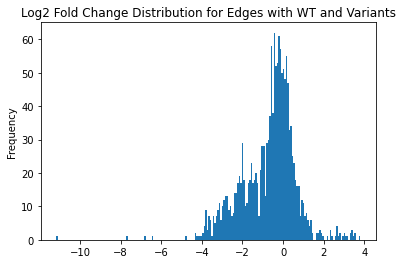

In [ ]:
summed_scores_for_export_pd_pl_filtered_pd = summed_scores_for_export_pd_pl_filtered.to_pandas()

summed_scores_for_export_pd_pl_filtered_pd[summed_scores_for_export_pd_pl_filtered_pd.db_mut_id != 0].log2fc.plot(kind='hist', bins=200, title='Log2 Fold Change Distribution for Edges with WT and Variants')

<Axes: title={'center': 'Log2 Fold Change Distribution for var'}, ylabel='Frequency'>

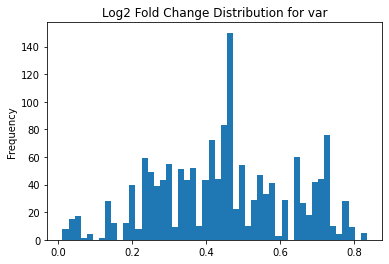

In [ ]:
summed_scores_for_export_pd_pl_filtered_pd[summed_scores_for_export_pd_pl_filtered_pd.db_mut_id != 0].wt_summed_score_normalized.plot(kind='hist', bins=50, title='Log2 Fold Change Distribution for var')

<Axes: title={'center': 'Log2 Fold Change Distribution for var'}, ylabel='Frequency'>

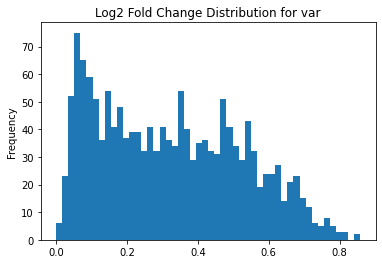

In [ ]:
summed_scores_for_export_pd_pl_filtered_pd[summed_scores_for_export_pd_pl_filtered_pd.db_mut_id != 0].summed_consensus_score_normalized.plot(kind='hist', bins=50, title='Log2 Fold Change Distribution for var')

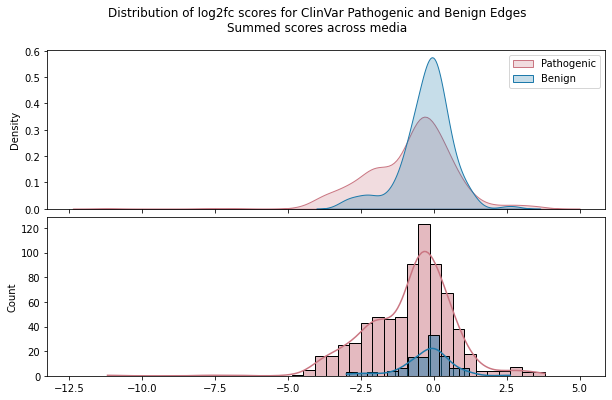

In [ ]:

path_thres = 0.42

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
sns.kdeplot(data=summed_scores_for_export_pd_pl_filtered.filter(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")["log2fc"].to_numpy(), label='Pathogenic', color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], fill=True, ax=axes[0])
sns.kdeplot(data=summed_scores_for_export_pd_pl_filtered.filter(pl.col("clinvar_clnsig_clean")=="2_Benign")["log2fc"].to_numpy(), label='Benign', color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], fill=True, ax=axes[0])
# axes[0].axvline(x=path_thres, color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres.')
axes[0].legend()

sns.histplot(summed_scores_for_export_pd_pl_filtered.filter(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")["log2fc"].to_numpy(), label='Pathogenic', color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], kde=True, ax=axes[1])
sns.histplot(summed_scores_for_export_pd_pl_filtered.filter(pl.col("clinvar_clnsig_clean")=="2_Benign")["log2fc"].to_numpy(), label='Benign', color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], kde=True, ax=axes[1])
# axes[1].axvline(x=path_thres, color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres.')
plt.subplots_adjust(hspace=.05)
plt.suptitle('Distribution of log2fc scores for ClinVar Pathogenic and Benign Edges\nSummed scores across media')
plt.show()

In [ ]:
summed_scores = summed_scores.with_columns(
    pl.concat_str([
            pl.col('db_orf_id').cast(pl.String),
            pl.col('db_mut_id').cast(pl.String)
    ], separator="_").alias("db_group"),
    pl.concat_str([
            pl.col('db_orf_id').cast(pl.String),
            pl.col('db_mut_id').cast(pl.String),
            pl.col('condition_name').cast(pl.String),
            pl.col('retest_batch').cast(pl.String)
    ], separator="_").alias("db_condition_group"),
    pl.concat_str([
            pl.col('ad_orf_id').cast(pl.String),
            pl.col('db_orf_id').cast(pl.String),
            pl.col('db_mut_id').cast(pl.String),
            pl.col('retest_batch').cast(pl.String)
    ], separator="_").alias("ppi_group"),
    pl.concat_str([
            pl.col('ad_orf_id').cast(pl.String),
            pl.col('db_orf_id').cast(pl.String),
            pl.col('retest_batch').cast(pl.String)
    ], separator="_").alias("edge_group")
)

In [ ]:
# =============================================================================
# COMPREHENSIVE FILTERING WORKFLOW TRACKING - POST-PROCESSING ANALYSIS
# =============================================================================

print("Reconstructing filtering workflow for comprehensive tracking...")
print("Note: This analysis recreates the filtering steps to track statistics")
print("="*80)

# Initialize tracking list
filtering_stats_list = []

# We need to start from before filtering and recreate the workflow
# Read the original scores before any filtering
print("Loading original scores to reconstruct filtering workflow...")

# Start by loading the original data before filtering

# Recreate the filtering workflow step by step
current_scores = scores_before_seq.clone()

# Step 0: Before any filtering (original data)
filtering_stats_list.append(get_filtering_stats(current_scores, aa_id, rrs_id, "0. Original Data"))

# Step 1: After sequence filtering (this is approximately where we start in the current workflow)
# We'll use a proxy since we can't perfectly recreate the sequence filtering
# The current 'scores' variable represents the state after sequence filtering
filtering_stats_list.append(get_filtering_stats(scores_after_seq, aa_id, rrs_id, "1. After Sequencing QC"))

# Now recreate the filtering steps that happened in the workflow
# Step 2: Autoactivation mating failures (db_group level)
aa_db_group_mating_failures = (scores_after_seq.filter(pl.col("ad_orf_id") == aa_id)
                              .filter(pl.col("condition_name") == "LW")
                              .filter(pl.col("consensus_score") <= 300)
                              .select("db_group")
                              .to_series().unique().to_list())
scores_step2 = scores_after_seq.filter(~pl.col("db_group").is_in(aa_db_group_mating_failures))
filtering_stats_list.append(get_filtering_stats(scores_step2, aa_id, rrs_id, "2. After AA Mating Failures (db_group)"))

# Step 3: Autoactivation technical failures
aa_db_group_tech_failures = (scores_step2.filter(pl.col("ad_orf_id") == aa_id)
                                   .filter(pl.col("consensus_score").is_nan())
                                   .select("db_condition_group")
                                   .to_series().unique().to_list())
scores_step3 = scores_step2.filter(~pl.col("db_condition_group").is_in(aa_db_group_tech_failures))
# filtering_stats_list.append(get_filtering_stats(scores_step3, aa_id, rrs_id, "3. After AA Technical Failures"))

# Step 4: Mating failures - LW <= 300
mating_failures = (scores_step3.filter(pl.col("condition_name") == "LW")
                         .filter(pl.col("consensus_score") <= 300)
                         .select("ppi_group").to_series().unique().to_list())
scores_step4 = scores_step3.filter(~pl.col("ppi_group").is_in(mating_failures))
filtering_stats_list.append(get_filtering_stats(scores_step4, aa_id, rrs_id, "4. After Mating Failures (LW <= 300)"))

# Step 5: Mating failures - LW null
mating_failures_2 = (scores_step4.filter(pl.col("condition_name") == "LW")
                         .filter(pl.col("consensus_score").is_null())
                         .select("ppi_group").to_series().unique().to_list())
scores_step5 = scores_step4.filter(~pl.col("ppi_group").is_in(mating_failures_2))
filtering_stats_list.append(get_filtering_stats(scores_step5, aa_id, rrs_id, "5. After Mating Failures (LW null)"))

# Step 6: Remove autoactivation rows and add AA scores
aa_scores = scores_step5.filter(pl.col("ad_orf_id") == aa_id).select([
    "db_condition_group", "consensus_score"
]).group_by("db_condition_group").agg(
    pl.col("consensus_score").mean().alias("aa_score")
)
scores_step6 = scores_step5.filter(pl.col("ad_orf_id") != aa_id).join(aa_scores, on="db_condition_group", how="left")
# filtering_stats_list.append(get_filtering_stats(scores_step6, aa_id, rrs_id, "6. After AA Row Removal"))

# Step 7: AA score filtering (300 threshold)
scores_step7 = scores_step6.filter(pl.col("aa_score").is_null() | (pl.col("aa_score") <= 300))
filtering_stats_list.append(get_filtering_stats(scores_step7, aa_id, rrs_id, "7. After AA Score Filter (<=300)"))

# Step 8: Remove RRS pairs (keep step but don't track since numbers don't change)
scores_step8 = scores_step7.filter(pl.col('db_mut_id') != rrs_id)

# Step 9: WT failures combined (LWH1 condition + summed score filtering)
wt_failures = (scores_step8.filter(pl.col("condition_name") == "LWH1")
                    .filter(pl.col("db_mut_id") == 0)
                    .filter(pl.col("consensus_score") < 300)
                    .select("ppi_group").to_series().unique().to_list())
scores_step9 = scores_step8.filter(~pl.col("ppi_group").is_in(wt_failures))

# Additional step: Filter for summed scores where WT > 0 (this happens in summed_scores processing)
# Create summed scores to simulate the additional WT filtering
summed_temp = scores_step9.filter(pl.col("condition_name").is_in(scoring_conditions))
summed_temp = summed_temp.group_by([
    'ad_orf_id', 'db_orf_id', 'db_mut_id', 'retest_batch'
]).agg(
    pl.col("consensus_score").sum().alias("summed_consensus_score")
)

# Get WT scores for normalization
wt_scores_temp = summed_temp.filter(pl.col("db_mut_id") == 0).select([
    "ad_orf_id", "db_orf_id", "retest_batch", "summed_consensus_score"
]).rename({"summed_consensus_score": "wt_summed_score"})

# Join and filter to only keep variants with valid WT references - MATCH THE ACTUAL LOGIC
summed_with_wt = summed_temp.join(
    wt_scores_temp, 
    on=["ad_orf_id", "db_orf_id", "retest_batch"], 
    how="left"  # Use left join like the actual workflow
).filter(
    pl.col("wt_summed_score").is_not_null()  # Filter after join, like the actual workflow
)

# Convert back to original scores format for tracking by filtering original scores
valid_ppi_groups = summed_with_wt.with_columns(
    pl.concat_str([
        (pl.col('ad_orf_id').cast(pl.String) + pl.lit(".0")),
        (pl.col('db_orf_id').cast(pl.String) + pl.lit(".0")),
        (pl.col('db_mut_id').cast(pl.String) + pl.lit(".0")),
        pl.col('retest_batch').cast(pl.String)
    ], separator="_").alias("ppi_group")
).select("ppi_group").to_series().to_list()

scores_step10 = scores_step9.filter(pl.col("ppi_group").is_in(valid_ppi_groups))
filtering_stats_list.append(get_filtering_stats(scores_step10, aa_id, rrs_id, "8. After WT Failures + Summed Score > 0"))

# Final step: This should match our current 'scores' variable
# Note: The final filtering result should be equivalent to the current 'scores'
# Add the final state for comparison
# filtering_stats_list.append(get_filtering_stats(summed_scores, aa_id, rrs_id, "9. Final (Current State)"))

print("Filtering workflow reconstruction complete!")
print("="*80)

Reconstructing filtering workflow for comprehensive tracking...
Note: This analysis recreates the filtering steps to track statistics
Loading original scores to reconstruct filtering workflow...
Filtering workflow reconstruction complete!


In [ ]:
# =============================================================================
# GENERATE COMPREHENSIVE FILTERING STATISTICS TABLE
# =============================================================================

# Create comprehensive table
print("Generating comprehensive filtering statistics table...")
comprehensive_table = create_comprehensive_filtering_table(filtering_stats_list)

# Display the table with better formatting
import pandas as pd
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)
pd.set_option('display.max_colwidth', None)

print("\n" + "="*120)
print("COMPREHENSIVE FILTERING STATISTICS TABLE")
print("="*120)
display(comprehensive_table)
# =============================================================================
# CREATE TWO SEPARATE SUMMARY TABLES FROM THE EXISTING COMPREHENSIVE TABLE
# =============================================================================

# 1. SUMMARY TABLE - ALL DATA (using the non-BOTH columns)
print("\n\n" + "="*120)
print("SUMMARY TABLE 1: ALL DATA (Complete Dataset)")
print("="*120)

summary_all_data = comprehensive_table[['Step', 'DB_ORF_IDs', 'AD_ORF_IDs', 'DB_Groups', 'Edge_Groups', 'PPI_Groups',
                                       'DB_ORFs_Dropped', 'AD_ORFs_Dropped', 'DB_Groups_Dropped', 'Edge_Groups_Dropped', 'PPIs_Dropped',
                                       'Percent_DB_ORFs_Dropped', 'Percent_AD_ORFs_Dropped', 'Percent_DB_Groups_Dropped', 
                                       'Percent_Edge_Groups_Dropped', 'Percent_PPIs_Dropped']].copy()

display(summary_all_data)

# 2. SUMMARY TABLE - WT+ALLELE FILTERED DATA (using the BOTH columns, renamed for clarity)
print("\n\n" + "="*120)
print("SUMMARY TABLE 2: WT+ALLELE FILTERED DATA (DB ORFs with both WT & variants only)")
print("="*120)

summary_wt_allele = comprehensive_table[['Step', 'DB_ORF_IDs_Both', 'AD_ORF_IDs_Both', 'DB_Groups_Both', 'Edge_Groups_Both', 'PPI_Groups_Both',
                                        'DB_ORF_IDs_Both_Dropped', 'AD_ORF_IDs_Both_Dropped', 'DB_Groups_Both_Dropped', 'Edge_Groups_Both_Dropped', 'PPI_Groups_Both_Dropped',
                                        'Percent_DB_ORF_IDs_Both_Dropped', 'Percent_AD_ORF_IDs_Both_Dropped', 'Percent_DB_Groups_Both_Dropped', 
                                        'Percent_Edge_Groups_Both_Dropped', 'Percent_PPI_Groups_Both_Dropped']].copy()

# Rename columns to make them more comprehensible (remove "_Both" suffix)
summary_wt_allele = summary_wt_allele.rename(columns={
    'DB_ORF_IDs_Both': 'DB_ORF_IDs',
    'AD_ORF_IDs_Both': 'AD_ORF_IDs',
    'DB_Groups_Both': 'DB_Groups',
    'Edge_Groups_Both': 'Edge_Groups',
    'PPI_Groups_Both': 'PPI_Groups',
    'DB_ORF_IDs_Both_Dropped': 'DB_ORFs_Dropped',
    'AD_ORF_IDs_Both_Dropped': 'AD_ORFs_Dropped',
    'DB_Groups_Both_Dropped': 'DB_Groups_Dropped',
    'Edge_Groups_Both_Dropped': 'Edge_Groups_Dropped',
    'PPI_Groups_Both_Dropped': 'PPIs_Dropped',
    'Percent_DB_ORF_IDs_Both_Dropped': 'Percent_DB_ORFs_Dropped',
    'Percent_AD_ORF_IDs_Both_Dropped': 'Percent_AD_ORFs_Dropped',
    'Percent_DB_Groups_Both_Dropped': 'Percent_DB_Groups_Dropped',
    'Percent_Edge_Groups_Both_Dropped': 'Percent_Edge_Groups_Dropped',
    'Percent_PPI_Groups_Both_Dropped': 'Percent_PPIs_Dropped'
})

display(summary_wt_allele)

# Save both tables
summary_all_data.to_csv(f"{outputs_dir}/summary_filtering_ALL_DATA.csv", index=False)
summary_wt_allele.to_csv(f"{outputs_dir}/summary_filtering_WT_ALLELE.csv", index=False)

print(f"\nTables saved:")
print(f"- Summary (All Data): {outputs_dir}/summary_filtering_ALL_DATA.csv")
print(f"- Summary (WT+Allele Filtered): {outputs_dir}/summary_filtering_WT_ALLELE.csv")

Generating comprehensive filtering statistics table...

COMPREHENSIVE FILTERING STATISTICS TABLE


,Step,Total_Rows,PPI_Groups,DB_ORF_IDs,AD_ORF_IDs,DB_Groups,Edge_Groups,DB_ORFs_Both_WT_Variants,PPI_Groups_Both,DB_ORF_IDs_Both,AD_ORF_IDs_Both,DB_Groups_Both,Edge_Groups_Both,Rows_Dropped,PPIs_Dropped,DB_ORFs_Dropped,AD_ORFs_Dropped,DB_Groups_Dropped,Edge_Groups_Dropped,DB_ORFs_Both_Dropped,PPI_Groups_Both_Dropped,DB_ORF_IDs_Both_Dropped,AD_ORF_IDs_Both_Dropped,DB_Groups_Both_Dropped,Edge_Groups_Both_Dropped,Percent_Rows_Dropped,Percent_PPIs_Dropped,Percent_DB_ORFs_Dropped,Percent_AD_ORFs_Dropped,Percent_DB_Groups_Dropped,Percent_Edge_Groups_Dropped,Percent_DB_ORFs_Both_Dropped,Percent_PPI_Groups_Both_Dropped,Percent_DB_ORF_IDs_Both_Dropped,Percent_AD_ORF_IDs_Both_Dropped,Percent_DB_Groups_Both_Dropped,Percent_Edge_Groups_Both_Dropped
0,0. Original Data,71490,8451,278,927,1376,1592,167,8019,167,776,1265,1160,0,0,0,0,0,0,0,0,0,0,0,0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
1,1. After Sequencing QC,48282,4583,246,783,842,1327,83,3686,83,373,669,465,23208,3868,32,144,534,265,84,4333,84,403,596,695,32.46,45.77,11.51,15.53,38.81,16.65,50.30,54.03,50.30,51.93,47.11,59.91
2,2. After AA Mating Failures (db_group),46008,4373,244,777,817,1317,81,3272,81,322,640,403,2274,210,2,6,25,10,2,414,2,51,29,62,4.71,4.58,0.81,0.77,2.97,0.75,2.41,11.23,2.41,13.67,4.33,13.33
3,4. After Mating Failures (LW <= 300),44484,4151,244,757,812,1270,81,3101,81,318,635,398,1524,222,0,20,5,47,0,171,0,4,5,5,3.31,5.08,0.00,2.57,0.61,3.57,0.00,5.23,0.00,1.24,0.78,1.24
4,5. After Mating Failures (LW null),39066,3648,232,695,781,1119,78,2730,78,304,594,380,5418,503,12,62,31,151,3,371,3,14,41,18,12.18,12.12,4.92,8.19,3.82,11.89,3.70,11.96,3.70,4.40,6.46,4.52
5,7. After AA Score Filter (<=300),21005,3636,232,695,777,1119,78,2718,78,304,590,380,18061,12,0,0,4,0,0,12,0,0,4,0,46.23,0.33,0.00,0.00,0.51,0.00,0.00,0.44,0.00,0.00,0.67,0.00
6,8. After WT Failures + Summed Score > 0,11848,2359,195,543,677,820,73,1808,73,230,555,269,9157,1277,37,152,100,299,5,910,5,74,35,111,43.59,35.12,15.95,21.87,12.87,26.72,6.41,33.48,6.41,24.34,5.93,29.21




SUMMARY TABLE 1: ALL DATA (Complete Dataset)


,Step,DB_ORF_IDs,AD_ORF_IDs,DB_Groups,Edge_Groups,PPI_Groups,DB_ORFs_Dropped,AD_ORFs_Dropped,DB_Groups_Dropped,Edge_Groups_Dropped,PPIs_Dropped,Percent_DB_ORFs_Dropped,Percent_AD_ORFs_Dropped,Percent_DB_Groups_Dropped,Percent_Edge_Groups_Dropped,Percent_PPIs_Dropped
0,0. Original Data,278,927,1376,1592,8451,0,0,0,0,0,0.00,0.00,0.00,0.00,0.00
1,1. After Sequencing QC,246,783,842,1327,4583,32,144,534,265,3868,11.51,15.53,38.81,16.65,45.77
2,2. After AA Mating Failures (db_group),244,777,817,1317,4373,2,6,25,10,210,0.81,0.77,2.97,0.75,4.58
3,4. After Mating Failures (LW <= 300),244,757,812,1270,4151,0,20,5,47,222,0.00,2.57,0.61,3.57,5.08
4,5. After Mating Failures (LW null),232,695,781,1119,3648,12,62,31,151,503,4.92,8.19,3.82,11.89,12.12
5,7. After AA Score Filter (<=300),232,695,777,1119,3636,0,0,4,0,12,0.00,0.00,0.51,0.00,0.33
6,8. After WT Failures + Summed Score > 0,195,543,677,820,2359,37,152,100,299,1277,15.95,21.87,12.87,26.72,35.12




SUMMARY TABLE 2: WT+ALLELE FILTERED DATA (DB ORFs with both WT & variants only)


,Step,DB_ORF_IDs,AD_ORF_IDs,DB_Groups,Edge_Groups,PPI_Groups,DB_ORFs_Dropped,AD_ORFs_Dropped,DB_Groups_Dropped,Edge_Groups_Dropped,PPIs_Dropped,Percent_DB_ORFs_Dropped,Percent_AD_ORFs_Dropped,Percent_DB_Groups_Dropped,Percent_Edge_Groups_Dropped,Percent_PPIs_Dropped
0,0. Original Data,167,776,1265,1160,8019,0,0,0,0,0,0.00,0.00,0.00,0.00,0.00
1,1. After Sequencing QC,83,373,669,465,3686,84,403,596,695,4333,50.30,51.93,47.11,59.91,54.03
2,2. After AA Mating Failures (db_group),81,322,640,403,3272,2,51,29,62,414,2.41,13.67,4.33,13.33,11.23
3,4. After Mating Failures (LW <= 300),81,318,635,398,3101,0,4,5,5,171,0.00,1.24,0.78,1.24,5.23
4,5. After Mating Failures (LW null),78,304,594,380,2730,3,14,41,18,371,3.70,4.40,6.46,4.52,11.96
5,7. After AA Score Filter (<=300),78,304,590,380,2718,0,0,4,0,12,0.00,0.00,0.67,0.00,0.44
6,8. After WT Failures + Summed Score > 0,73,230,555,269,1808,5,74,35,111,910,6.41,24.34,5.93,29.21,33.48



Tables saved:
- Summary (All Data): ../3_outputs/sqY2H/summary_filtering_ALL_DATA.csv
- Summary (WT+Allele Filtered): ../3_outputs/sqY2H/summary_filtering_WT_ALLELE.csv


## best media instead of summing

In [ ]:
# Finding maximum perturbation scores

# Keep a reference to original data with condition names
original_conditions = scores.filter(pl.col("condition_name").is_in(scoring_conditions)).select([
    'ad_orf_id', 'db_orf_id', 'db_mut_id', 'retest_batch', 'condition_name'
]).unique()

perturbation_scores = scores.filter(pl.col("condition_name").is_in(scoring_conditions))

# Get WT scores for each condition
wt_scores = perturbation_scores.filter(pl.col("db_mut_id") == 0).select([
    "ad_orf_id", "db_orf_id", "retest_batch", "condition_name", "consensus_score"
]).rename({"consensus_score": "wt_score"})

# Join variant scores with their corresponding WT scores for each condition
perturbation_scores = perturbation_scores.join(
    wt_scores, 
    on=["ad_orf_id", "db_orf_id", "retest_batch", "condition_name"], 
    how="left"
).filter(
    pl.col("wt_score").is_not_null()  # Only keep variants that have a WT reference
)



# Calculate score difference for each condition
perturbation_scores = perturbation_scores.with_columns(
    (pl.col("wt_score") - pl.col("consensus_score")).alias("score_difference"),
    ((pl.col("consensus_score") + 1) / (pl.col("wt_score") + 1)).alias("fold_change"),
    ((pl.col("consensus_score") + 1) / (pl.col("wt_score") + 1)).log().alias("log2_fold_change") / np.log(2)
)

# Add a within-group row number to match with arg_max
perturbation_scores = perturbation_scores.with_columns(
    pl.int_range(pl.len()).over(['ad_orf_id', 'db_orf_id', 'db_mut_id', 'retest_batch']).alias("group_row_nr")
)

# For each variant, find the condition with maximum perturbation (absolute difference)
max_perturbation_idx = perturbation_scores.group_by([
    'ad_orf_id', 'db_orf_id', 'db_mut_id', 'retest_batch'
]).agg([
    pl.col("score_difference").abs().arg_max().alias("max_perturbation_idx")
])

# Join back to get the actual condition information
max_perturbation_with_condition = max_perturbation_idx.join(
    perturbation_scores,
    left_on=["ad_orf_id", "db_orf_id", "db_mut_id", "retest_batch", "max_perturbation_idx"],
    right_on=["ad_orf_id", "db_orf_id", "db_mut_id", "retest_batch", "group_row_nr"],
    how="left"
).select([
    "ad_orf_id", "db_orf_id", "db_mut_id", "retest_batch",
    "condition_name", "consensus_score", "wt_score", 
    "score_difference", "fold_change", "log2_fold_change"
]).rename({
    "condition_name": "max_perturbation_condition",
    "consensus_score": "max_perturbation_variant_score", 
    "wt_score": "max_perturbation_wt_score",
    "score_difference": "max_perturbation",
    "fold_change": "max_perturbation_fold",
    "log2_fold_change": "max_log2_fold_change"
})

# Also calculate the summary statistics
max_perturbation_stats = perturbation_scores.group_by([
    'ad_orf_id', 'db_orf_id', 'db_mut_id', 'retest_batch'
]).agg([
    pl.col("score_difference").abs().max().alias("max_perturbation_abs"),
    pl.col("fold_change").abs().max().alias("max_perturbation_fold_abs")
])

# Combine everything
max_perturbation_final = max_perturbation_with_condition.join(
    max_perturbation_stats,
    on=["ad_orf_id", "db_orf_id", "db_mut_id", "retest_batch"],
    how="left"
)

print(f"Max perturbation scores shape: {max_perturbation_final.shape}")
max_perturbation_final

Max perturbation scores shape: (2359, 12)


ad_orf_id,db_orf_id,db_mut_id,retest_batch,max_perturbation_condition,max_perturbation_variant_score,max_perturbation_wt_score,max_perturbation,max_perturbation_fold,max_log2_fold_change,max_perturbation_abs,max_perturbation_fold_abs
i64,i64,i64,str,str,f64,f64,f64,f64,f64,f64,f64
1611,2713,449,"""VUSAPWT1B1""","""LWA""",9.891177,430.258502,420.367326,0.025254,-5.307321,420.367326,0.484067
3156,3192,0,"""VUSAPWT1B2""","""LWA""",625.304278,625.304278,0.0,1.0,0.0,0.0,1.0
10064,52920,2689,"""VUSAPWT2B1""","""LWH1""",553.193486,451.626816,-101.566671,1.224394,0.292068,101.566671,1.233792
54354,54082,0,"""VUSAPWT2B1""","""LWH10""",578.429436,578.429436,0.0,1.0,0.0,0.0,1.0
13182,70368,0,"""VUSAPWT6B1""","""LWA""",77.923859,77.923859,0.0,1.0,0.0,0.0,1.0
…,…,…,…,…,…,…,…,…,…,…,…
2778,71191,0,"""VUSAPWT2B1""","""LWA""",476.232034,476.232034,0.0,1.0,0.0,0.0,1.0
71402,53030,0,"""VUSAPWT1B2""","""LWA""",391.882686,391.882686,0.0,1.0,0.0,0.0,1.0
66,5431,0,"""VUSAPWT1B2""","""LWA""",0.0,0.0,0.0,1.0,0.0,0.0,1.0


In [ ]:
max_perturbation_final = max_perturbation_final.join(metadata, on=["db_orf_id", "db_mut_id"], how="left")
max_perturbation_final

ad_orf_id,db_orf_id,db_mut_id,retest_batch,max_perturbation_condition,max_perturbation_variant_score,max_perturbation_wt_score,max_perturbation,max_perturbation_fold,max_log2_fold_change,max_perturbation_abs,max_perturbation_fold_abs,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0
i64,i64,i64,str,str,f64,f64,f64,f64,f64,f64,f64,str,str,str,str,str,str,f64,f64,str
1611,2713,449,"""VUSAPWT1B1""","""LWA""",9.891177,430.258502,420.367326,0.025254,-5.307321,420.367326,0.484067,"""MLH1""","""Pro28Leu""","""83C>T""","""ENSG00000076242""","""Edgotyping3""","""1_Pathogenic""",6.8405e-7,3.0,"""MLH1_Pro28Leu"""
3156,3192,0,"""VUSAPWT1B2""","""LWA""",625.304278,625.304278,0.0,1.0,0.0,0.0,1.0,"""CDKN1A""",null,null,"""ENSG00000124762""",null,null,null,null,"""CDKN1A"""
10064,52920,2689,"""VUSAPWT2B1""","""LWH1""",553.193486,451.626816,-101.566671,1.224394,0.292068,101.566671,1.233792,"""LITAF""","""Ser15Leu""","""44C>T""","""ENSG00000189067""","""Edgotyping3""","""3_Conflicting""",null,1.0,"""LITAF_Ser15Leu"""
54354,54082,0,"""VUSAPWT2B1""","""LWH10""",578.429436,578.429436,0.0,1.0,0.0,0.0,1.0,"""PRPF31""",null,null,"""ENSG00000105618""",null,null,null,null,"""PRPF31"""
13182,70368,0,"""VUSAPWT6B1""","""LWA""",77.923859,77.923859,0.0,1.0,0.0,0.0,1.0,"""KCTD7""",null,null,"""ENSG00000243335""",null,null,null,null,"""KCTD7"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
2778,71191,0,"""VUSAPWT2B1""","""LWA""",476.232034,476.232034,0.0,1.0,0.0,0.0,1.0,"""SUOX""",null,null,"""ENSG00000139531""",null,null,null,null,"""SUOX"""
71402,53030,0,"""VUSAPWT1B2""","""LWA""",391.882686,391.882686,0.0,1.0,0.0,0.0,1.0,"""FAM161A""",null,null,"""ENSG00000170264""",null,null,null,null,"""FAM161A"""
66,5431,0,"""VUSAPWT1B2""","""LWA""",0.0,0.0,0.0,1.0,0.0,0.0,1.0,"""POLR1C""",null,null,"""ENSG00000171453""",null,null,null,null,"""POLR1C"""


In [ ]:
max_perturbation_final_pd = max_perturbation_final.to_pandas()
max_perturbation_final_pd

,ad_orf_id,db_orf_id,db_mut_id,retest_batch,max_perturbation_condition,max_perturbation_variant_score,max_perturbation_wt_score,max_perturbation,max_perturbation_fold,max_log2_fold_change,max_perturbation_abs,max_perturbation_fold_abs,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0
0,1611,2713,449,VUSAPWT1B1,LWA,9.891177,430.258502,420.367326,0.025254,-5.307321,420.367326,0.484067,MLH1,Pro28Leu,83C>T,ENSG00000076242,Edgotyping3,1_Pathogenic,6.840530e-07,3.0,MLH1_Pro28Leu
1,3156,3192,0,VUSAPWT1B2,LWA,625.304278,625.304278,0.000000,1.000000,0.000000,0.000000,1.000000,CDKN1A,None,None,ENSG00000124762,None,None,NaN,NaN,CDKN1A
2,10064,52920,2689,VUSAPWT2B1,LWH1,553.193486,451.626816,-101.566671,1.224394,0.292068,101.566671,1.233792,LITAF,Ser15Leu,44C>T,ENSG00000189067,Edgotyping3,3_Conflicting,NaN,1.0,LITAF_Ser15Leu
3,54354,54082,0,VUSAPWT2B1,LWH10,578.429436,578.429436,0.000000,1.000000,0.000000,0.000000,1.000000,PRPF31,None,None,ENSG00000105618,None,None,NaN,NaN,PRPF31
4,13182,70368,0,VUSAPWT6B1,LWA,77.923859,77.923859,0.000000,1.000000,0.000000,0.000000,1.000000,KCTD7,None,None,ENSG00000243335,None,None,NaN,NaN,KCTD7
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2354,2778,71191,0,VUSAPWT2B1,LWA,476.232034,476.232034,0.000000,1.000000,0.000000,0.000000,1.000000,SUOX,None,None,ENSG00000139531,None,None,NaN,NaN,SUOX
2355,71402,53030,0,VUSAPWT1B2,LWA,391.882686,391.882686,0.000000,1.000000,0.000000,0.000000,1.000000,FAM161A,None,None,ENSG00000170264,None,None,NaN,NaN,FAM161A
2356,66,5431,0,VUSAPWT1B2,LWA,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,1.000000,POLR1C,None,None,ENSG00000171453,None,None,NaN,NaN,POLR1C
2357,6791,8143,0,VUSAPWT1B2,LWA,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,1.000000,SH3BP2,None,None,ENSG00000087266,None,None,NaN,NaN,SH3BP2


In [ ]:
print(f"Original max_perturbation_final shape: {max_perturbation_final.shape}")
print(f"Filtered max_perturbation_final db orfs: {max_perturbation_final.select(pl.col('db_orf_id').n_unique()).item()}")
print(f"Filtered max_perturbation_final ad orfs: {max_perturbation_final.select(pl.col('ad_orf_id').n_unique()).item()}")

Original max_perturbation_final shape: (2359, 21)
Filtered max_perturbation_final db orfs: 195
Filtered max_perturbation_final ad orfs: 543


In [ ]:

# Filter for edges that have both WT and at least one variant

# Find edges (ad_orf_id, db_orf_id, retest_batch) with WT data
edges_with_wt = max_perturbation_final.filter(pl.col("db_mut_id") == 0).select([
    "db_orf_id"#, "ad_orf_id", "retest_batch"
]).unique()

# Find edges with variant data  
edges_with_variants = max_perturbation_final.filter(pl.col("db_mut_id") != 0).select([
    "db_orf_id"#, "ad_orf_id", "retest_batch"
]).unique()

# Get intersection - edges that have both WT and variants
edges_with_both = edges_with_wt.join(
    edges_with_variants, 
    on=["db_orf_id"],#, "ad_orf_id", "retest_batch"], 
    how="inner"
)

# Filter max_perturbation_final to only include these edges
max_perturbation_final_filtered = max_perturbation_final.join(
    edges_with_both,
    on=["db_orf_id"],# "ad_orf_id", "retest_batch"],
    how="inner"
)

print(f"Original max_perturbation_final shape: {max_perturbation_final.shape}")
print(f"Filtered max_perturbation_final shape: {max_perturbation_final_filtered.shape}")
print(f"Filtered max_perturbation_final db orfs: {max_perturbation_final_filtered.select(pl.col('db_orf_id').n_unique()).item()}")
print(f"Filtered max_perturbation_final ad orfs: {max_perturbation_final_filtered.select(pl.col('ad_orf_id').n_unique()).item()}")
print(f"Unique edges with both WT and variants: {edges_with_both.height}")

# Remove WT rows (db_mut_id == 0) to keep only variants
max_perturbation_final_filtered = max_perturbation_final_filtered.filter(pl.col("db_mut_id") != 0)

print(f"After removing WT rows: {max_perturbation_final_filtered.shape}")
print(f"Filtered max_perturbation_final db orfs: {max_perturbation_final_filtered.select(pl.col('db_orf_id').n_unique()).item()}")
print(f"Filtered max_perturbation_final ad orfs: {max_perturbation_final_filtered.select(pl.col('ad_orf_id').n_unique()).item()}")
print(f"Unique edges with both WT and variants: {edges_with_both.height}")

max_perturbation_final_filtered_pd = max_perturbation_final_filtered.to_pandas()
max_perturbation_final_filtered

Original max_perturbation_final shape: (2359, 21)
Filtered max_perturbation_final shape: (1808, 21)
Filtered max_perturbation_final db orfs: 73
Filtered max_perturbation_final ad orfs: 230
Unique edges with both WT and variants: 73
After removing WT rows: (1539, 21)
Filtered max_perturbation_final db orfs: 73
Filtered max_perturbation_final ad orfs: 225
Unique edges with both WT and variants: 73


ad_orf_id,db_orf_id,db_mut_id,retest_batch,max_perturbation_condition,max_perturbation_variant_score,max_perturbation_wt_score,max_perturbation,max_perturbation_fold,max_log2_fold_change,max_perturbation_abs,max_perturbation_fold_abs,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0
i64,i64,i64,str,str,f64,f64,f64,f64,f64,f64,f64,str,str,str,str,str,str,f64,f64,str
1611,2713,449,"""VUSAPWT1B1""","""LWA""",9.891177,430.258502,420.367326,0.025254,-5.307321,420.367326,0.484067,"""MLH1""","""Pro28Leu""","""83C>T""","""ENSG00000076242""","""Edgotyping3""","""1_Pathogenic""",6.8405e-7,3.0,"""MLH1_Pro28Leu"""
10064,52920,2689,"""VUSAPWT2B1""","""LWH1""",553.193486,451.626816,-101.566671,1.224394,0.292068,101.566671,1.233792,"""LITAF""","""Ser15Leu""","""44C>T""","""ENSG00000189067""","""Edgotyping3""","""3_Conflicting""",null,1.0,"""LITAF_Ser15Leu"""
1769,3535,6172,"""VUSAPWT1B1""","""LWH25""",500.446425,351.682356,-148.764069,1.421808,0.507726,148.764069,1.421808,"""EMD""","""Pro183His""","""548C>A""","""ENSG00000102119""","""RC4""","""1_Pathogenic""",null,1.0,"""EMD_Pro183His"""
2615,7652,1802,"""VUSAPWT2B1""","""LWA""",290.764057,594.233034,303.468977,0.490168,-1.028652,303.468977,0.83936,"""STXBP1""","""Lys196Arg""","""587A>G""","""ENSG00000136854""","""Edgotyping3""","""4_VUS""",null,null,"""STXBP1_Lys196Arg"""
9342,3535,6172,"""VUSAPWT1B1""","""LWA""",130.08072,0.0,-130.08072,131.08072,7.034312,130.08072,131.08072,"""EMD""","""Pro183His""","""548C>A""","""ENSG00000102119""","""RC4""","""1_Pathogenic""",null,1.0,"""EMD_Pro183His"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
13662,70497,3780,"""VUSAPWT1B1""","""LWH10""",2.797386,454.03106,451.233675,0.008345,-6.904815,451.233675,0.283604,"""AGXT""","""Pro10Ala""","""28C>G""","""ENSG00000172482""","""Edgotyping3""","""4_VUS""",0.000008,1.0,"""AGXT_Pro10Ala"""
8297,13796,218146,"""VUSAPWT1B2""","""LWH25""",55.870262,558.782374,502.912112,0.101594,-3.29912,502.912112,0.101594,"""HBD""","""Asn58Lys""","""174C>A""","""ENSG00000223609""","""CEGS2""","""5_Others""",null,null,"""HBD_Asn58Lys"""
71001,52920,2665,"""VUSAPWT1B1""","""LWH25""",375.66602,473.579749,97.913729,0.793683,-0.333365,97.913729,1.163756,"""LITAF""","""Val144Met""","""430G>A""","""ENSG00000189067""","""Edgotyping3""","""4_VUS""",null,1.0,"""LITAF_Val144Met"""


In [ ]:
max_perturbation_final_filtered_pd

,ad_orf_id,db_orf_id,db_mut_id,retest_batch,max_perturbation_condition,max_perturbation_variant_score,max_perturbation_wt_score,max_perturbation,max_perturbation_fold,max_log2_fold_change,max_perturbation_abs,max_perturbation_fold_abs,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0
0,1611,2713,449,VUSAPWT1B1,LWA,9.891177,430.258502,420.367326,0.025254,-5.307321,420.367326,0.484067,MLH1,Pro28Leu,83C>T,ENSG00000076242,Edgotyping3,1_Pathogenic,6.840530e-07,3.0,MLH1_Pro28Leu
1,10064,52920,2689,VUSAPWT2B1,LWH1,553.193486,451.626816,-101.566671,1.224394,0.292068,101.566671,1.233792,LITAF,Ser15Leu,44C>T,ENSG00000189067,Edgotyping3,3_Conflicting,NaN,1.0,LITAF_Ser15Leu
2,1769,3535,6172,VUSAPWT1B1,LWH25,500.446425,351.682356,-148.764069,1.421808,0.507726,148.764069,1.421808,EMD,Pro183His,548C>A,ENSG00000102119,RC4,1_Pathogenic,NaN,1.0,EMD_Pro183His
3,2615,7652,1802,VUSAPWT2B1,LWA,290.764057,594.233034,303.468977,0.490168,-1.028652,303.468977,0.839360,STXBP1,Lys196Arg,587A>G,ENSG00000136854,Edgotyping3,4_VUS,NaN,NaN,STXBP1_Lys196Arg
4,9342,3535,6172,VUSAPWT1B1,LWA,130.080720,0.000000,-130.080720,131.080720,7.034312,130.080720,131.080720,EMD,Pro183His,548C>A,ENSG00000102119,RC4,1_Pathogenic,NaN,1.0,EMD_Pro183His
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1534,13662,70497,3780,VUSAPWT1B1,LWH10,2.797386,454.031060,451.233675,0.008345,-6.904815,451.233675,0.283604,AGXT,Pro10Ala,28C>G,ENSG00000172482,Edgotyping3,4_VUS,8.215570e-06,1.0,AGXT_Pro10Ala
1535,8297,13796,218146,VUSAPWT1B2,LWH25,55.870262,558.782374,502.912112,0.101594,-3.299120,502.912112,0.101594,HBD,Asn58Lys,174C>A,ENSG00000223609,CEGS2,5_Others,NaN,NaN,HBD_Asn58Lys
1536,71001,52920,2665,VUSAPWT1B1,LWH25,375.666020,473.579749,97.913729,0.793683,-0.333365,97.913729,1.163756,LITAF,Val144Met,430G>A,ENSG00000189067,Edgotyping3,4_VUS,NaN,1.0,LITAF_Val144Met
1537,7233,7652,1818,VUSAPWT1B1,LWH10,509.660474,443.365698,-66.294776,1.149190,0.200617,66.294776,4.172549,STXBP1,Lys333Glu,997A>G,ENSG00000136854,Edgotyping3,4_VUS,6.840600e-07,1.0,STXBP1_Lys333Glu


In [ ]:
max_perturbation_final_filtered_pd.max_perturbation_condition.value_counts()

max_perturbation_condition
LWH10    531
LWH25    397
LWA      325
LWH1     283
Name: count, dtype: int64

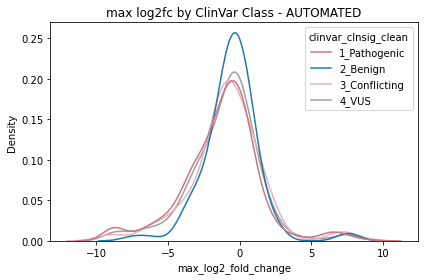

In [ ]:
variables = ["max_log2_fold_change", "frac_per_0.0", "frac_per_0.2", "cosine_distance"]

# Define color mapping for classes
color_map = {
    "1_Pathogenic": "red",
    "2_Benign": "green",
    "3_Conflicting": "orange",
    "4_VUS": "blue"
}

# Only plot the first variable
var = variables[0]
hue_order = ["1_Pathogenic", "2_Benign", "3_Conflicting", "4_VUS"]

sns.kdeplot(
    data=max_perturbation_final_filtered,
    x=var,
    hue="clinvar_clnsig_clean",
    hue_order=hue_order,
    # palette=[color_map.get(k, "gray") for k in hue_order],
    palette=palette_dict['clinvar_clnsig_clean'],
    common_norm=False
)

plt.title('max log2fc by ClinVar Class - AUTOMATED')
plt.tight_layout()
plt.show()

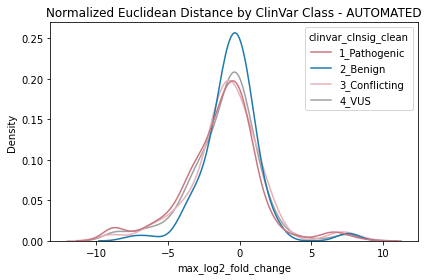

In [ ]:
max_perturbation_final_filtered_log2_filtered = max_perturbation_final_filtered.filter(
    (pl.col("max_log2_fold_change") > -25) & (pl.col("max_log2_fold_change") < 25)
)

variables = ["max_log2_fold_change", "frac_per_0.0", "frac_per_0.2", "cosine_distance"]

# Define color mapping for classes
color_map = {
    "1_Pathogenic": "red",
    "2_Benign": "green",
    "3_Conflicting": "orange",
    "4_VUS": "blue"
}

# Only plot the first variable
var = variables[0]
hue_order = ["1_Pathogenic", "2_Benign", "3_Conflicting", "4_VUS"]

sns.kdeplot(
    data=max_perturbation_final_filtered_log2_filtered,
    x=var,
    hue="clinvar_clnsig_clean",
    hue_order=hue_order,
    # palette=[color_map.get(k, "gray") for k in hue_order],
    palette=palette_dict['clinvar_clnsig_clean'],
    common_norm=False
)

plt.title('Normalized Euclidean Distance by ClinVar Class - AUTOMATED')
plt.tight_layout()
plt.show()

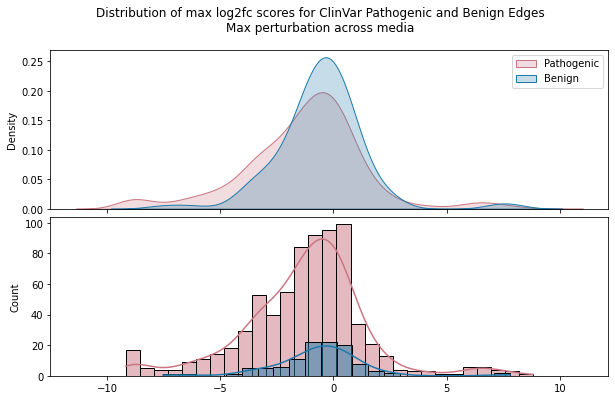

In [ ]:

path_thres = 0.42

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
sns.kdeplot(data=max_perturbation_final_filtered_log2_filtered.filter(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")["max_log2_fold_change"].to_numpy(), label='Pathogenic', color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], fill=True, ax=axes[0])
sns.kdeplot(data=max_perturbation_final_filtered_log2_filtered.filter(pl.col("clinvar_clnsig_clean")=="2_Benign")["max_log2_fold_change"].to_numpy(), label='Benign', color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], fill=True, ax=axes[0])
# axes[0].axvline(x=path_thres, color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres.')
axes[0].legend()

sns.histplot(max_perturbation_final_filtered_log2_filtered.filter(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")["max_log2_fold_change"].to_numpy(), label='Pathogenic', color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], kde=True, ax=axes[1])
sns.histplot(max_perturbation_final_filtered_log2_filtered.filter(pl.col("clinvar_clnsig_clean")=="2_Benign")["max_log2_fold_change"].to_numpy(), label='Benign', color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], kde=True, ax=axes[1])
# axes[1].axvline(x=path_thres, color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres.')
plt.subplots_adjust(hspace=.05)
plt.suptitle('Distribution of max log2fc scores for ClinVar Pathogenic and Benign Edges\nMax perturbation across media')
plt.show()

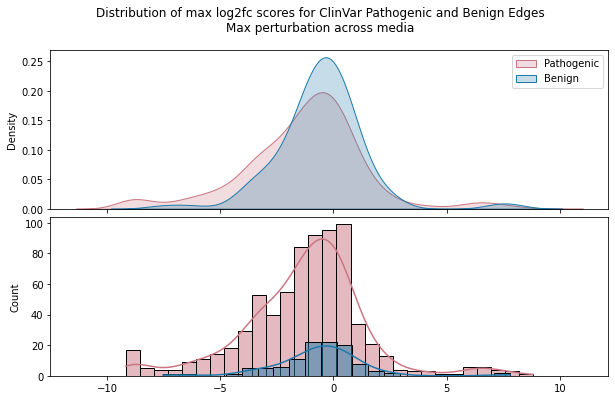

In [ ]:

path_thres = 0.42

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
sns.kdeplot(data=max_perturbation_final_filtered.filter(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")["max_log2_fold_change"].to_numpy(), label='Pathogenic', color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], fill=True, ax=axes[0])
sns.kdeplot(data=max_perturbation_final_filtered.filter(pl.col("clinvar_clnsig_clean")=="2_Benign")["max_log2_fold_change"].to_numpy(), label='Benign', color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], fill=True, ax=axes[0])
# axes[0].axvline(x=path_thres, color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres.')
axes[0].legend()

sns.histplot(max_perturbation_final_filtered.filter(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")["max_log2_fold_change"].to_numpy(), label='Pathogenic', color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], kde=True, ax=axes[1])
sns.histplot(max_perturbation_final_filtered.filter(pl.col("clinvar_clnsig_clean")=="2_Benign")["max_log2_fold_change"].to_numpy(), label='Benign', color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], kde=True, ax=axes[1])
# axes[1].axvline(x=path_thres, color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres.')
plt.subplots_adjust(hspace=.05)
plt.suptitle('Distribution of max log2fc scores for ClinVar Pathogenic and Benign Edges\nMax perturbation across media')
plt.show()



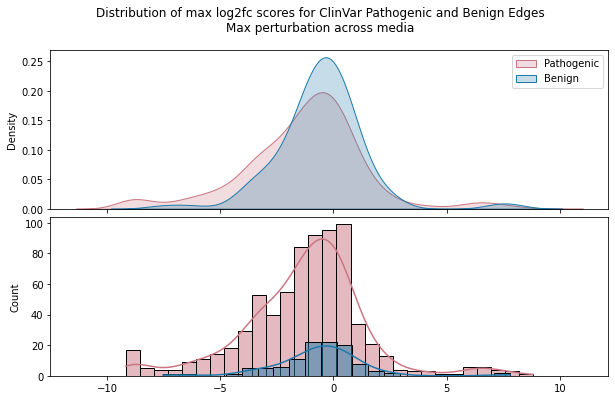

In [ ]:

path_thres = 0.42

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
sns.kdeplot(data=max_perturbation_final_filtered.filter(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")["max_log2_fold_change"].to_numpy(), label='Pathogenic', color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], fill=True, ax=axes[0])
sns.kdeplot(data=max_perturbation_final_filtered.filter(pl.col("clinvar_clnsig_clean")=="2_Benign")["max_log2_fold_change"].to_numpy(), label='Benign', color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], fill=True, ax=axes[0])
# axes[0].axvline(x=path_thres, color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres.')
axes[0].legend()

sns.histplot(max_perturbation_final_filtered.filter(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")["max_log2_fold_change"].to_numpy(), label='Pathogenic', color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], kde=True, ax=axes[1])
sns.histplot(max_perturbation_final_filtered.filter(pl.col("clinvar_clnsig_clean")=="2_Benign")["max_log2_fold_change"].to_numpy(), label='Benign', color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], kde=True, ax=axes[1])
# axes[1].axvline(x=path_thres, color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres.')
plt.subplots_adjust(hspace=.05)
plt.suptitle('Distribution of max log2fc scores for ClinVar Pathogenic and Benign Edges\nMax perturbation across media')
plt.show()



In [ ]:
max_perturbation_final_filtered

ad_orf_id,db_orf_id,db_mut_id,retest_batch,max_perturbation_condition,max_perturbation_variant_score,max_perturbation_wt_score,max_perturbation,max_perturbation_fold,max_log2_fold_change,max_perturbation_abs,max_perturbation_fold_abs,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0
i64,i64,i64,str,str,f64,f64,f64,f64,f64,f64,f64,str,str,str,str,str,str,f64,f64,str
1611,2713,449,"""VUSAPWT1B1""","""LWA""",9.891177,430.258502,420.367326,0.025254,-5.307321,420.367326,0.484067,"""MLH1""","""Pro28Leu""","""83C>T""","""ENSG00000076242""","""Edgotyping3""","""1_Pathogenic""",6.8405e-7,3.0,"""MLH1_Pro28Leu"""
10064,52920,2689,"""VUSAPWT2B1""","""LWH1""",553.193486,451.626816,-101.566671,1.224394,0.292068,101.566671,1.233792,"""LITAF""","""Ser15Leu""","""44C>T""","""ENSG00000189067""","""Edgotyping3""","""3_Conflicting""",null,1.0,"""LITAF_Ser15Leu"""
1769,3535,6172,"""VUSAPWT1B1""","""LWH25""",500.446425,351.682356,-148.764069,1.421808,0.507726,148.764069,1.421808,"""EMD""","""Pro183His""","""548C>A""","""ENSG00000102119""","""RC4""","""1_Pathogenic""",null,1.0,"""EMD_Pro183His"""
2615,7652,1802,"""VUSAPWT2B1""","""LWA""",290.764057,594.233034,303.468977,0.490168,-1.028652,303.468977,0.83936,"""STXBP1""","""Lys196Arg""","""587A>G""","""ENSG00000136854""","""Edgotyping3""","""4_VUS""",null,null,"""STXBP1_Lys196Arg"""
9342,3535,6172,"""VUSAPWT1B1""","""LWA""",130.08072,0.0,-130.08072,131.08072,7.034312,130.08072,131.08072,"""EMD""","""Pro183His""","""548C>A""","""ENSG00000102119""","""RC4""","""1_Pathogenic""",null,1.0,"""EMD_Pro183His"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
13662,70497,3780,"""VUSAPWT1B1""","""LWH10""",2.797386,454.03106,451.233675,0.008345,-6.904815,451.233675,0.283604,"""AGXT""","""Pro10Ala""","""28C>G""","""ENSG00000172482""","""Edgotyping3""","""4_VUS""",0.000008,1.0,"""AGXT_Pro10Ala"""
8297,13796,218146,"""VUSAPWT1B2""","""LWH25""",55.870262,558.782374,502.912112,0.101594,-3.29912,502.912112,0.101594,"""HBD""","""Asn58Lys""","""174C>A""","""ENSG00000223609""","""CEGS2""","""5_Others""",null,null,"""HBD_Asn58Lys"""
71001,52920,2665,"""VUSAPWT1B1""","""LWH25""",375.66602,473.579749,97.913729,0.793683,-0.333365,97.913729,1.163756,"""LITAF""","""Val144Met""","""430G>A""","""ENSG00000189067""","""Edgotyping3""","""4_VUS""",null,1.0,"""LITAF_Val144Met"""


In [ ]:
# Finding maximum perturbation scores for MANUAL scoring (using adjusted_score)

# Keep a reference to original data with condition names for manual scoring
original_conditions_manual = scores.filter(pl.col("condition_name").is_in(scoring_conditions)).select([
    'ad_orf_id', 'db_orf_id', 'db_mut_id', 'retest_batch', 'condition_name'
]).unique()

# Get the scores data for manual scoring analysis (using adjusted_score from the QA/QC pipeline)
perturbation_scores_manual = scores.filter(pl.col("condition_name").is_in(scoring_conditions))

# Use the manual_score_growth that's already in the scores dataframe
# Get WT manual scores for each condition
wt_scores_manual = perturbation_scores_manual.filter(pl.col("db_mut_id") == 0).select([
    "ad_orf_id", "db_orf_id", "retest_batch", "condition_name", "manual_score_growth"
]).rename({"manual_score_growth": "wt_manual_score"})

# Join variant scores with their corresponding WT scores for each condition
perturbation_scores_manual = perturbation_scores_manual.join(
    wt_scores_manual, 
    on=["ad_orf_id", "db_orf_id", "retest_batch", "condition_name"], 
    how="left"
).filter(
    pl.col("wt_manual_score").is_not_null()  # Only keep variants that have a WT reference
)

# Calculate score difference for each condition using manual scores
perturbation_scores_manual = perturbation_scores_manual.with_columns(
    (pl.col("wt_manual_score") - pl.col("manual_score_growth")).alias("manual_score_difference"),
    ((pl.col("manual_score_growth") + 0.1) / (pl.col("wt_manual_score") + 1e-8)).alias("manual_fold_change"),
    ((pl.col("manual_score_growth") + 0.1) / (pl.col("wt_manual_score") + 1e-8)).log().alias("manual_log2_fold_change") / np.log(2)
)

# Add a within-group row number to match with arg_max
perturbation_scores_manual = perturbation_scores_manual.with_columns(
    pl.int_range(pl.len()).over(['ad_orf_id', 'db_orf_id', 'db_mut_id', 'retest_batch']).alias("group_row_nr_manual")
)

# For each variant, find the condition with maximum perturbation (absolute difference) for manual scores
max_perturbation_idx_manual = perturbation_scores_manual.group_by([
    'ad_orf_id', 'db_orf_id', 'db_mut_id', 'retest_batch'
]).agg([
    pl.col("manual_score_difference").abs().arg_max().alias("max_perturbation_idx_manual")
])

# Join back to get the actual condition information for manual scores
max_perturbation_with_condition_manual = max_perturbation_idx_manual.join(
    perturbation_scores_manual,
    left_on=["ad_orf_id", "db_orf_id", "db_mut_id", "retest_batch", "max_perturbation_idx_manual"],
    right_on=["ad_orf_id", "db_orf_id", "db_mut_id", "retest_batch", "group_row_nr_manual"],
    how="left"
).select([
    "ad_orf_id", "db_orf_id", "db_mut_id", "retest_batch",
    "condition_name", "manual_score_growth", "wt_manual_score", 
    "manual_score_difference", "manual_fold_change", "manual_log2_fold_change"
]).rename({
    "condition_name": "max_perturbation_condition_manual",
    "manual_score_growth": "max_perturbation_variant_manual_score", 
    "wt_manual_score": "max_perturbation_wt_manual_score",
    "manual_score_difference": "max_perturbation_manual",
    "manual_fold_change": "max_perturbation_manual_fold",
    "manual_log2_fold_change": "max_manual_log2_fold_change"
})

# Also calculate the summary statistics for manual scores
max_perturbation_stats_manual = perturbation_scores_manual.group_by([
    'ad_orf_id', 'db_orf_id', 'db_mut_id', 'retest_batch'
]).agg([
    pl.col("manual_score_difference").abs().max().alias("max_perturbation_manual_abs"),
    pl.col("manual_fold_change").abs().max().alias("max_perturbation_manual_fold_abs")
])

# Combine everything for manual scores
max_perturbation_final_manual = max_perturbation_with_condition_manual.join(
    max_perturbation_stats_manual,
    on=["ad_orf_id", "db_orf_id", "db_mut_id", "retest_batch"],
    how="left"
)

print(f"Max perturbation manual scores shape: {max_perturbation_final_manual.shape}")

# Add metadata to manual results
max_perturbation_final_manual = max_perturbation_final_manual.join(metadata, on=["db_orf_id", "db_mut_id"], how="left")

# Filter for edges that have both WT and at least one variant (same logic as automated)
edges_with_wt_manual = max_perturbation_final_manual.filter(pl.col("db_mut_id") == 0).select([
    "db_orf_id"
]).unique()

edges_with_variants_manual = max_perturbation_final_manual.filter(pl.col("db_mut_id") != 0).select([
    "db_orf_id"
]).unique()

edges_with_both_manual = edges_with_wt_manual.join(
    edges_with_variants_manual, 
    on=["db_orf_id"], 
    how="inner"
)

# Filter max_perturbation_final_manual to only include these edges
max_perturbation_final_filtered_manual = max_perturbation_final_manual.join(
    edges_with_both_manual,
    on=["db_orf_id"],
    how="inner"
)

# Remove WT rows (db_mut_id == 0) to keep only variants
max_perturbation_final_filtered_manual = max_perturbation_final_filtered_manual.filter(pl.col("db_mut_id") != 0)

print(f"Max perturbation manual scores filtered shape: {max_perturbation_final_filtered_manual.shape}")
print(f"Manual filtered db orfs: {max_perturbation_final_filtered_manual.select(pl.col('db_orf_id').n_unique()).item()}")
print(f"Manual filtered ad orfs: {max_perturbation_final_filtered_manual.select(pl.col('ad_orf_id').n_unique()).item()}")

# Now merge the manual results with the automated results
# Convert both to pandas for easier merging
max_perturbation_final_filtered_pd = max_perturbation_final_filtered.to_pandas()
max_perturbation_final_filtered_manual_pd = max_perturbation_final_filtered_manual.to_pandas()

# Merge on the key columns to combine automated and manual results
combined_results = max_perturbation_final_filtered_pd.merge(
    max_perturbation_final_filtered_manual_pd[["db_orf_id", "ad_orf_id", "db_mut_id", "retest_batch", 
                                               "max_perturbation_condition_manual", "max_perturbation_variant_manual_score",
                                               "max_perturbation_wt_manual_score", "max_perturbation_manual",
                                               "max_perturbation_manual_fold", "max_manual_log2_fold_change",
                                               "max_perturbation_manual_abs", "max_perturbation_manual_fold_abs"]],
    on=["db_orf_id", "ad_orf_id", "db_mut_id", "retest_batch"],
    how="left"
)

print(f"Combined results shape: {combined_results.shape}")
combined_results

Max perturbation manual scores shape: (2359, 12)
Max perturbation manual scores filtered shape: (1539, 21)
Manual filtered db orfs: 73
Manual filtered ad orfs: 225
Combined results shape: (1539, 29)


,ad_orf_id,db_orf_id,db_mut_id,retest_batch,max_perturbation_condition,max_perturbation_variant_score,max_perturbation_wt_score,max_perturbation,max_perturbation_fold,max_log2_fold_change,max_perturbation_abs,max_perturbation_fold_abs,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,max_perturbation_condition_manual,max_perturbation_variant_manual_score,max_perturbation_wt_manual_score,max_perturbation_manual,max_perturbation_manual_fold,max_manual_log2_fold_change,max_perturbation_manual_abs,max_perturbation_manual_fold_abs
0,1611,2713,449,VUSAPWT1B1,LWA,9.891177,430.258502,420.367326,0.025254,-5.307321,420.367326,0.484067,MLH1,Pro28Leu,83C>T,ENSG00000076242,Edgotyping3,1_Pathogenic,6.840530e-07,3.0,MLH1_Pro28Leu,LWA,0.0,4.0,4.0,0.025000,-5.321928,4.0,7.750000e-01
1,10064,52920,2689,VUSAPWT2B1,LWH1,553.193486,451.626816,-101.566671,1.224394,0.292068,101.566671,1.233792,LITAF,Ser15Leu,44C>T,ENSG00000189067,Edgotyping3,3_Conflicting,NaN,1.0,LITAF_Ser15Leu,LWA,3.0,4.0,1.0,0.775000,-0.367732,1.0,1.050000e+00
2,1769,3535,6172,VUSAPWT1B1,LWH25,500.446425,351.682356,-148.764069,1.421808,0.507726,148.764069,1.421808,EMD,Pro183His,548C>A,ENSG00000102119,RC4,1_Pathogenic,NaN,1.0,EMD_Pro183His,LWA,1.0,2.0,1.0,0.550000,-0.862496,1.0,1.033333e+00
3,2615,7652,1802,VUSAPWT2B1,LWA,290.764057,594.233034,303.468977,0.490168,-1.028652,303.468977,0.839360,STXBP1,Lys196Arg,587A>G,ENSG00000136854,Edgotyping3,4_VUS,NaN,NaN,STXBP1_Lys196Arg,LWA,2.0,4.0,2.0,0.525000,-0.929611,2.0,7.750000e-01
4,9342,3535,6172,VUSAPWT1B1,LWA,130.080720,0.000000,-130.080720,131.080720,7.034312,130.080720,131.080720,EMD,Pro183His,548C>A,ENSG00000102119,RC4,1_Pathogenic,NaN,1.0,EMD_Pro183His,LWH10,2.0,3.0,1.0,0.700000,-0.514573,1.0,1.000000e+07
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1534,13662,70497,3780,VUSAPWT1B1,LWH10,2.797386,454.031060,451.233675,0.008345,-6.904815,451.233675,0.283604,AGXT,Pro10Ala,28C>G,ENSG00000172482,Edgotyping3,4_VUS,8.215570e-06,1.0,AGXT_Pro10Ala,LWH1,0.0,3.0,3.0,0.033333,-4.906891,3.0,5.000000e-02
1535,8297,13796,218146,VUSAPWT1B2,LWH25,55.870262,558.782374,502.912112,0.101594,-3.299120,502.912112,0.101594,HBD,Asn58Lys,174C>A,ENSG00000223609,CEGS2,5_Others,NaN,NaN,HBD_Asn58Lys,LWH1,0.0,4.0,4.0,0.025000,-5.321928,4.0,1.000000e+07
1536,71001,52920,2665,VUSAPWT1B1,LWH25,375.666020,473.579749,97.913729,0.793683,-0.333365,97.913729,1.163756,LITAF,Val144Met,430G>A,ENSG00000189067,Edgotyping3,4_VUS,NaN,1.0,LITAF_Val144Met,LWA,4.0,4.0,0.0,1.025000,0.035624,0.0,1.033333e+00
1537,7233,7652,1818,VUSAPWT1B1,LWH10,509.660474,443.365698,-66.294776,1.149190,0.200617,66.294776,4.172549,STXBP1,Lys333Glu,997A>G,ENSG00000136854,Edgotyping3,4_VUS,6.840600e-07,1.0,STXBP1_Lys333Glu,LWH1,3.0,4.0,1.0,0.775000,-0.367732,1.0,1.000000e+07


In [ ]:
perturbation_scores_manual_pd = perturbation_scores_manual.to_pandas()

perturbation_scores_manual_pd[
    (perturbation_scores_manual_pd.db_orf_id == 14221) &
    (perturbation_scores_manual_pd.db_mut_id == 218281) &
    (perturbation_scores_manual_pd.condition_name == "LWH25") &
    (perturbation_scores_manual_pd.ad_orf_id == 14221)
]

,scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,db_source_plate,db_source_well,ad_source_plate,ad_source_well,manual_score_growth,per_well_integrated_intensity_gray,contamination,automated_log2,consensus_score,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,db_group,db_condition_group,ppi_group,edge_group,seq_ad,seq_db,db_seq_final,aa_score,consensus_manual_score_growth,wt_manual_score,manual_score_difference,manual_fold_change,manual_log2_fold_change,group_row_nr_manual
4684,VUSAPWT1B2r05_028,O13,VUSAPWT1B2r05_025_026_027_028_029_030,VUSAPWT1B2,r11,LWH25,1,False,14221,NaN,14221,218281,VUSMutY8Dh030,C02,CEGSint_Y8A_7,H01,4.0,495.143803,False,9.090493,514.606218,KCTD1,KCTD1,Pro31His,92C>A,ENSG00000134504,CEGS2,1_Pathogenic,NaN,NaN,KCTD1_Pro31His,14221.0_218281.0,14221.0_218281.0_LWH25_VUSAPWT1B2,14221.0_14221.0_218281.0_VUSAPWT1B2,14221.0_14221.0_VUSAPWT1B2,1,1,Y,56.223857,4.0,0.0,-4.0,410000000.0,28.611049,3


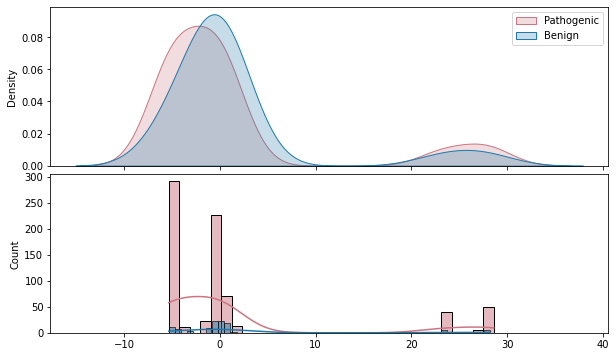

In [ ]:

path_thres = 0.42

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
sns.kdeplot(data=max_perturbation_final_filtered_manual.filter(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")["max_manual_log2_fold_change"].to_numpy(), label='Pathogenic', color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], fill=True, ax=axes[0])
sns.kdeplot(data=max_perturbation_final_filtered_manual.filter(pl.col("clinvar_clnsig_clean")=="2_Benign")["max_manual_log2_fold_change"].to_numpy(), label='Benign', color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], fill=True, ax=axes[0])
# axes[0].axvline(x=path_thres, color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres.')
axes[0].legend()

sns.histplot(max_perturbation_final_filtered_manual.filter(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")["max_manual_log2_fold_change"].to_numpy(), label='Pathogenic', color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], kde=True, ax=axes[1])
sns.histplot(max_perturbation_final_filtered_manual.filter(pl.col("clinvar_clnsig_clean")=="2_Benign")["max_manual_log2_fold_change"].to_numpy(), label='Benign', color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], kde=True, ax=axes[1])
# axes[1].axvline(x=path_thres, color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres.')
plt.subplots_adjust(hspace=.05)
plt.show()

## dropped orfs

In [ ]:
# ...existing code...

def track_db_orf_id_filtering(target_db_orf_id, scores_before_seq=scores_before_seq, aa_id=aa_id, rrs_id=rrs_id, scoring_conditions=scoring_conditions):
    """
    Track where a specific db_orf_id gets dropped during the QA/QC filtering workflow
    
    Parameters:
    target_db_orf_id: The db_orf_id to track
    scores_before_seq: The initial scores dataframe before sequence filtering
    aa_id: autoactivation ID
    rrs_id: RRS ID
    scoring_conditions: list of scoring conditions
    
    Returns:
    dict: Summary of where the db_orf_id was present/dropped
    """
    
    tracking_results = {
        'db_orf_id': target_db_orf_id,
        'steps': [],
        'dropped_at_step': None,
        'final_status': 'Unknown'
    }
    
    def check_presence(df, step_name):
        """Check if target_db_orf_id is present in the dataframe"""
        present = df.filter(pl.col("db_orf_id") == target_db_orf_id).height > 0
        if present:
            count = df.filter(pl.col("db_orf_id") == target_db_orf_id).height
            unique_variants = df.filter(pl.col("db_orf_id") == target_db_orf_id).select("db_mut_id").n_unique()
            unique_ads = df.filter(pl.col("db_orf_id") == target_db_orf_id).select("ad_orf_id").n_unique()
            
            # Get sample of the data
            sample_data = df.filter(pl.col("db_orf_id") == target_db_orf_id).head(3).select([
                "ad_orf_id", "db_mut_id", "condition_name", "consensus_score", "retest_batch"
            ]).to_pandas()
            
            return {
                'present': True,
                'total_rows': count,
                'unique_variants': unique_variants,
                'unique_ads': unique_ads,
                'sample_data': sample_data.to_dict('records') if len(sample_data) > 0 else []
            }
        else:
            return {'present': False, 'total_rows': 0, 'unique_variants': 0, 'unique_ads': 0, 'sample_data': []}
    
    print(f"Tracking db_orf_id {target_db_orf_id} through QA/QC filtering workflow...")
    print("="*80)
    
    # Step 0: Original data
    current_scores = scores_before_seq.clone()
    step_info = check_presence(current_scores, "0. Original Data")
    step_info['step_name'] = "0. Original Data"
    tracking_results['steps'].append(step_info)
    print(f"Step 0 - Original Data: {'✓ Present' if step_info['present'] else '✗ Not Present'} "
          f"({step_info['total_rows']} rows, {step_info['unique_variants']} variants, {step_info['unique_ads']} ADs)")
    
    if not step_info['present']:
        tracking_results['dropped_at_step'] = "0. Original Data (Never present)"
        tracking_results['final_status'] = 'Never present in original data'
        return tracking_results
    
    # Step 1: After sequence filtering (approximated by scores_after_seq if available)
    try:
        # Try to use the actual scores_after_seq from the workflow
        step_info = check_presence(scores_after_seq, "1. After Sequencing QC")
        step_info['step_name'] = "1. After Sequencing QC"
        tracking_results['steps'].append(step_info)
        print(f"Step 1 - After Sequencing QC: {'✓ Present' if step_info['present'] else '✗ DROPPED'} "
              f"({step_info['total_rows']} rows, {step_info['unique_variants']} variants, {step_info['unique_ads']} ADs)")
        
        if not step_info['present'] and tracking_results['dropped_at_step'] is None:
            tracking_results['dropped_at_step'] = "1. After Sequencing QC"
            tracking_results['final_status'] = 'Dropped during sequence confirmation filtering'
            return tracking_results
        
        current_scores = scores_after_seq.clone()
    except NameError:
        print("Warning: scores_after_seq not available, using current_scores")
    
    # Step 2: AA mating failures (db_group level)
    aa_db_group_mating_failures = (current_scores.filter(pl.col("ad_orf_id") == aa_id)
                                  .filter(pl.col("condition_name") == "LW")
                                  .filter(pl.col("consensus_score") <= 300)
                                  .select("db_group")
                                  .to_series().unique().to_list())
    current_scores = current_scores.filter(~pl.col("db_group").is_in(aa_db_group_mating_failures))
    
    step_info = check_presence(current_scores, "2. After AA Mating Failures (db_group)")
    step_info['step_name'] = "2. After AA Mating Failures (db_group)"
    step_info['aa_failures_removed'] = len(aa_db_group_mating_failures)
    tracking_results['steps'].append(step_info)
    print(f"Step 2 - After AA Mating Failures: {'✓ Present' if step_info['present'] else '✗ DROPPED'} "
          f"({step_info['total_rows']} rows, {step_info['unique_variants']} variants, {step_info['unique_ads']} ADs)")
    
    if not step_info['present'] and tracking_results['dropped_at_step'] is None:
        tracking_results['dropped_at_step'] = "2. After AA Mating Failures (db_group)"
        tracking_results['final_status'] = 'Dropped due to autoactivation mating failures'
        return tracking_results
    
    # Step 3: AA technical failures
    aa_db_group_tech_failures = (current_scores.filter(pl.col("ad_orf_id") == aa_id)
                                       .filter(pl.col("consensus_score").is_nan())
                                       .select("db_condition_group")
                                       .to_series().unique().to_list())
    current_scores = current_scores.filter(~pl.col("db_condition_group").is_in(aa_db_group_tech_failures))
    
    step_info = check_presence(current_scores, "3. After AA Technical Failures")
    step_info['step_name'] = "3. After AA Technical Failures"
    tracking_results['steps'].append(step_info)
    print(f"Step 3 - After AA Technical Failures: {'✓ Present' if step_info['present'] else '✗ DROPPED'} "
          f"({step_info['total_rows']} rows, {step_info['unique_variants']} variants, {step_info['unique_ads']} ADs)")
    
    if not step_info['present'] and tracking_results['dropped_at_step'] is None:
        tracking_results['dropped_at_step'] = "3. After AA Technical Failures"
        tracking_results['final_status'] = 'Dropped due to autoactivation technical failures'
        return tracking_results
    
    # Step 4: Mating failures - LW <= 300
    mating_failures = (current_scores.filter(pl.col("condition_name") == "LW")
                             .filter(pl.col("consensus_score") <= 300)
                             .select("ppi_group").to_series().unique().to_list())
    current_scores = current_scores.filter(~pl.col("ppi_group").is_in(mating_failures))
    
    step_info = check_presence(current_scores, "4. After Mating Failures (LW <= 300)")
    step_info['step_name'] = "4. After Mating Failures (LW <= 300)"
    step_info['mating_failures_removed'] = len(mating_failures)
    tracking_results['steps'].append(step_info)
    print(f"Step 4 - After Mating Failures (LW <= 300): {'✓ Present' if step_info['present'] else '✗ DROPPED'} "
          f"({step_info['total_rows']} rows, {step_info['unique_variants']} variants, {step_info['unique_ads']} ADs)")
    
    if not step_info['present'] and tracking_results['dropped_at_step'] is None:
        tracking_results['dropped_at_step'] = "4. After Mating Failures (LW <= 300)"
        tracking_results['final_status'] = 'Dropped due to mating failures (LW score <= 300)'
        return tracking_results
    
    # Step 5: Mating failures - LW null
    mating_failures_2 = (current_scores.filter(pl.col("condition_name") == "LW")
                               .filter(pl.col("consensus_score").is_null())
                               .select("ppi_group").to_series().unique().to_list())
    current_scores = current_scores.filter(~pl.col("ppi_group").is_in(mating_failures_2))
    
    step_info = check_presence(current_scores, "5. After Mating Failures (LW null)")
    step_info['step_name'] = "5. After Mating Failures (LW null)"
    tracking_results['steps'].append(step_info)
    print(f"Step 5 - After Mating Failures (LW null): {'✓ Present' if step_info['present'] else '✗ DROPPED'} "
          f"({step_info['total_rows']} rows, {step_info['unique_variants']} variants, {step_info['unique_ads']} ADs)")
    
    if not step_info['present'] and tracking_results['dropped_at_step'] is None:
        tracking_results['dropped_at_step'] = "5. After Mating Failures (LW null)"
        tracking_results['final_status'] = 'Dropped due to mating failures (LW score null)'
        return tracking_results
    
    # Step 6: Remove autoactivation rows and add AA scores
    aa_scores = current_scores.filter(pl.col("ad_orf_id") == aa_id).select([
        "db_condition_group", "consensus_score"
    ]).group_by("db_condition_group").agg(
        pl.col("consensus_score").mean().alias("aa_score")
    )
    current_scores = current_scores.filter(pl.col("ad_orf_id") != aa_id).join(aa_scores, on="db_condition_group", how="left")
    
    step_info = check_presence(current_scores, "6. After AA Row Removal")
    step_info['step_name'] = "6. After AA Row Removal"
    tracking_results['steps'].append(step_info)
    print(f"Step 6 - After AA Row Removal: {'✓ Present' if step_info['present'] else '✗ DROPPED'} "
          f"({step_info['total_rows']} rows, {step_info['unique_variants']} variants, {step_info['unique_ads']} ADs)")
    
    if not step_info['present'] and tracking_results['dropped_at_step'] is None:
        tracking_results['dropped_at_step'] = "6. After AA Row Removal"
        tracking_results['final_status'] = 'Was only present as autoactivation rows'
        return tracking_results
    
    # Step 7: AA score filtering (300 threshold)
    current_scores = current_scores.filter(pl.col("aa_score").is_null() | (pl.col("aa_score") <= 300))
    
    step_info = check_presence(current_scores, "7. After AA Score Filter (<=300)")
    step_info['step_name'] = "7. After AA Score Filter (<=300)"
    tracking_results['steps'].append(step_info)
    print(f"Step 7 - After AA Score Filter (<=300): {'✓ Present' if step_info['present'] else '✗ DROPPED'} "
          f"({step_info['total_rows']} rows, {step_info['unique_variants']} variants, {step_info['unique_ads']} ADs)")
    
    if not step_info['present'] and tracking_results['dropped_at_step'] is None:
        tracking_results['dropped_at_step'] = "7. After AA Score Filter (<=300)"
        tracking_results['final_status'] = 'Dropped due to high autoactivation score (>300)'
        return tracking_results
    
    # Step 8: Remove RRS pairs
    current_scores = current_scores.filter(pl.col('db_mut_id') != rrs_id)
    
    step_info = check_presence(current_scores, "8. After RRS Removal")
    step_info['step_name'] = "8. After RRS Removal"
    tracking_results['steps'].append(step_info)
    print(f"Step 8 - After RRS Removal: {'✓ Present' if step_info['present'] else '✗ DROPPED'} "
          f"({step_info['total_rows']} rows, {step_info['unique_variants']} variants, {step_info['unique_ads']} ADs)")
    
    if not step_info['present'] and tracking_results['dropped_at_step'] is None:
        tracking_results['dropped_at_step'] = "8. After RRS Removal"
        tracking_results['final_status'] = 'Was only present as RRS pairs'
        return tracking_results
    
    # Step 9: WT failures (LWH1 condition)
    wt_failures = (current_scores.filter(pl.col("condition_name") == "LWH1")
                        .filter(pl.col("db_mut_id") == 0)
                        .filter(pl.col("consensus_score") < 300)
                        .select("edge_group").to_series().unique().to_list())
    current_scores = current_scores.filter(~pl.col("edge_group").is_in(wt_failures))
    
    step_info = check_presence(current_scores, "9. After WT Failures (LWH1 < 300)")
    step_info['step_name'] = "9. After WT Failures (LWH1 < 300)"
    step_info['wt_failures_removed'] = len(wt_failures)
    tracking_results['steps'].append(step_info)
    print(f"Step 9 - After WT Failures: {'✓ Present' if step_info['present'] else '✗ DROPPED'} "
          f"({step_info['total_rows']} rows, {step_info['unique_variants']} variants, {step_info['unique_ads']} ADs)")
    
    if not step_info['present'] and tracking_results['dropped_at_step'] is None:
        tracking_results['dropped_at_step'] = "9. After WT Failures (LWH1 < 300)"
        tracking_results['final_status'] = 'Dropped due to WT failure in LWH1 condition'
        return tracking_results
    
    # Step 10: Final summed score filtering (simulated)
    try:
        # Simulate the summed score filtering logic
        summed_temp = current_scores.filter(pl.col("condition_name").is_in(scoring_conditions))
        summed_temp = summed_temp.group_by([
            'ad_orf_id', 'db_orf_id', 'db_mut_id', 'retest_batch'
        ]).agg(
            pl.col("consensus_score").sum().alias("summed_consensus_score")
        )
        
        # Get WT scores for normalization
        wt_scores_temp = summed_temp.filter(pl.col("db_mut_id") == 0).select([
            "ad_orf_id", "db_orf_id", "retest_batch", "summed_consensus_score"
        ]).rename({"summed_consensus_score": "wt_summed_score"})
        
        # Join and filter to only keep variants with valid WT references
        summed_with_wt = summed_temp.join(
            wt_scores_temp, 
            on=["ad_orf_id", "db_orf_id", "retest_batch"], 
            how="left"
        ).filter(
            pl.col("wt_summed_score").is_not_null()
        )
        
        # Check if target is still present
        target_present = summed_with_wt.filter(pl.col("db_orf_id") == target_db_orf_id).height > 0
        
        step_info = {
            'present': target_present,
            'step_name': "10. After Summed Score WT Filtering",
            'total_rows': summed_with_wt.filter(pl.col("db_orf_id") == target_db_orf_id).height if target_present else 0,
            'unique_variants': summed_with_wt.filter(pl.col("db_orf_id") == target_db_orf_id).select("db_mut_id").n_unique() if target_present else 0,
            'unique_ads': summed_with_wt.filter(pl.col("db_orf_id") == target_db_orf_id).select("ad_orf_id").n_unique() if target_present else 0
        }
        
        tracking_results['steps'].append(step_info)
        print(f"Step 10 - After Summed Score WT Filtering: {'✓ Present' if step_info['present'] else '✗ DROPPED'} "
              f"({step_info['total_rows']} rows, {step_info['unique_variants']} variants, {step_info['unique_ads']} ADs)")
        
        if not step_info['present'] and tracking_results['dropped_at_step'] is None:
            tracking_results['dropped_at_step'] = "10. After Summed Score WT Filtering"
            tracking_results['final_status'] = 'Dropped because no valid WT reference for summed scoring'
            return tracking_results
        
    except Exception as e:
        print(f"Warning: Could not simulate summed score filtering: {e}")
    
    # Final status
    if tracking_results['dropped_at_step'] is None:
        tracking_results['final_status'] = 'Present in final dataset'
    
    print("="*80)
    print(f"SUMMARY for db_orf_id {target_db_orf_id}:")
    print(f"Final Status: {tracking_results['final_status']}")
    if tracking_results['dropped_at_step']:
        print(f"Dropped at: {tracking_results['dropped_at_step']}")
    
    return tracking_results

# Example usage:
# Track a specific db_orf_id through the filtering workflow
target_id = 2803  # Replace with the db_orf_id you want to track
tracking_result = track_db_orf_id_filtering(target_id, scores_before_seq, aa_id, rrs_id, scoring_conditions)

# Print detailed results
print(f"\nDetailed tracking results for db_orf_id {target_id}:")
for i, step in enumerate(tracking_result['steps']):
    print(f"\nStep {i}: {step['step_name']}")
    print(f"  Present: {step['present']}")
    if step['present']:
        print(f"  Total rows: {step['total_rows']}")
        print(f"  Unique variants: {step['unique_variants']}")
        print(f"  Unique ADs: {step['unique_ads']}")
        if step.get('sample_data') and len(step['sample_data']) > 0:
            print(f"  Sample data: {step['sample_data'][:2]}")  # Show first 2 samples

Tracking db_orf_id 2803 through QA/QC filtering workflow...
Step 0 - Original Data: ✓ Present (288 rows, 24 variants, 2 ADs)
Step 1 - After Sequencing QC: ✓ Present (270 rows, 24 variants, 2 ADs)
Step 2 - After AA Mating Failures: ✓ Present (270 rows, 24 variants, 2 ADs)
Step 3 - After AA Technical Failures: ✓ Present (270 rows, 24 variants, 2 ADs)
Step 4 - After Mating Failures (LW <= 300): ✓ Present (264 rows, 24 variants, 2 ADs)
Step 5 - After Mating Failures (LW null): ✓ Present (228 rows, 22 variants, 2 ADs)
Step 6 - After AA Row Removal: ✓ Present (96 rows, 16 variants, 1 ADs)
Step 7 - After AA Score Filter (<=300): ✓ Present (73 rows, 16 variants, 1 ADs)
Step 8 - After RRS Removal: ✓ Present (73 rows, 16 variants, 1 ADs)
Step 9 - After WT Failures: ✓ Present (73 rows, 16 variants, 1 ADs)
Step 10 - After Summed Score WT Filtering: ✗ DROPPED (0 rows, 0 variants, 0 ADs)

Detailed tracking results for db_orf_id 2803:

Step 0: 0. Original Data
  Present: True
  Total rows: 288
  Uniq

In [ ]:
target_id = 281  # Replace with the db_orf_id you want to track
tracking_result = track_db_orf_id_filtering(target_id, scores_before_seq, aa_id, rrs_id, scoring_conditions)

# Print detailed results
print(f"\nDetailed tracking results for db_orf_id {target_id}:")
for i, step in enumerate(tracking_result['steps']):
    print(f"\nStep {i}: {step['step_name']}")
    print(f"  Present: {step['present']}")
    if step['present']:
        print(f"  Total rows: {step['total_rows']}")
        print(f"  Unique variants: {step['unique_variants']}")
        print(f"  Unique ADs: {step['unique_ads']}")
        if step.get('sample_data') and len(step['sample_data']) > 0:
            print(f"  Sample data: {step['sample_data'][:2]}")  # Show first 2 samples

Tracking db_orf_id 281 through QA/QC filtering workflow...
Step 0 - Original Data: ✓ Present (396 rows, 33 variants, 2 ADs)
Step 1 - After Sequencing QC: ✓ Present (264 rows, 33 variants, 2 ADs)
Step 2 - After AA Mating Failures: ✓ Present (252 rows, 31 variants, 2 ADs)
Step 3 - After AA Technical Failures: ✓ Present (252 rows, 31 variants, 2 ADs)
Step 4 - After Mating Failures (LW <= 300): ✓ Present (252 rows, 31 variants, 2 ADs)
Step 5 - After Mating Failures (LW null): ✓ Present (252 rows, 31 variants, 2 ADs)
Step 6 - After AA Row Removal: ✓ Present (66 rows, 11 variants, 1 ADs)
Step 7 - After AA Score Filter (<=300): ✓ Present (55 rows, 11 variants, 1 ADs)
Step 8 - After RRS Removal: ✓ Present (55 rows, 11 variants, 1 ADs)
Step 9 - After WT Failures: ✓ Present (55 rows, 11 variants, 1 ADs)
Step 10 - After Summed Score WT Filtering: ✓ Present (11 rows, 11 variants, 1 ADs)
SUMMARY for db_orf_id 281:
Final Status: Present in final dataset

Detailed tracking results for db_orf_id 281:


In [ ]:
scores_pd[scores_pd.symbol == 'MVK']

,scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,db_source_plate,db_source_well,ad_source_plate,ad_source_well,manual_score_growth,per_well_integrated_intensity_gray,contamination,automated_log2,consensus_score,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,db_group,db_condition_group,ppi_group,edge_group,seq_ad,seq_db,db_seq_final,aa_score
10,VUSAPWT1B1r01_001,G07,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1,False,281,NaN,281,0,DisWTGDEh03,E03,CEGSint_Y8A_1,H11,4.0,553.367343,False,9.236893,533.711460,MVK,MVK,None,None,ENSG00000110921,None,None,NaN,NaN,MVK,281.0_0.0,281.0_0.0_LW_VUSAPWT1B1,281.0_281.0_0.0_VUSAPWT1B1,281.0_281.0_VUSAPWT1B1,1,1,None,522.089892
430,VUSAPWT1B1r01_039,A09,VUSAPWT1B1r01_037_038_039_040_041_042,VUSAPWT1B1,r07,LW,1,False,281,NaN,281,744,VUSMutY8Dh024,C01,CEGSint_Y8A_1,H11,4.0,NaN,False,NaN,374.774308,MVK,MVK,Asn205Asp,613A>G,ENSG00000110921,RC4,1_Pathogenic,0.000027,2.0,MVK_Asn205Asp,281.0_744.0,281.0_744.0_LW_VUSAPWT1B1,281.0_281.0_744.0_VUSAPWT1B1,281.0_281.0_VUSAPWT1B1,1,1,Y,590.542182
472,VUSAPWT1B1r02_001,G07,VUSAPWT1B1r02_001_002_003_004_005_006,VUSAPWT1B1,r08,LWA,1,False,281,NaN,281,0,DisWTGDEh03,E03,CEGSint_Y8A_1,H11,0.0,0.000000,False,5.643856,0.000000,MVK,MVK,None,None,ENSG00000110921,None,None,NaN,NaN,MVK,281.0_0.0,281.0_0.0_LWA_VUSAPWT1B1,281.0_281.0_0.0_VUSAPWT1B1,281.0_281.0_VUSAPWT1B1,1,1,None,0.000000
892,VUSAPWT1B1r02_039,A09,VUSAPWT1B1r02_037_038_039_040_041_042,VUSAPWT1B1,r08,LWA,1,False,281,NaN,281,744,VUSMutY8Dh024,C01,CEGSint_Y8A_1,H11,0.0,7.985621,False,5.857623,1.996405,MVK,MVK,Asn205Asp,613A>G,ENSG00000110921,RC4,1_Pathogenic,0.000027,2.0,MVK_Asn205Asp,281.0_744.0,281.0_744.0_LWA_VUSAPWT1B1,281.0_281.0_744.0_VUSAPWT1B1,281.0_281.0_VUSAPWT1B1,1,1,Y,0.000000
932,VUSAPWT1B1r03_001,G07,VUSAPWT1B1r03_001_002_003_004_005_006,VUSAPWT1B1,r09,LWH1,1,False,281,NaN,281,0,DisWTGDEh03,E03,CEGSint_Y8A_1,H11,3.0,532.894137,False,9.187090,502.541845,MVK,MVK,None,None,ENSG00000110921,None,None,NaN,NaN,MVK,281.0_0.0,281.0_0.0_LWH1_VUSAPWT1B1,281.0_281.0_0.0_VUSAPWT1B1,281.0_281.0_VUSAPWT1B1,1,1,None,58.002288
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17340,VUSAPWT1B1r06_020,C03,VUSAPWT1B1r06_019_020_021_022_023_024,VUSAPWT1B1,r12,LWAH1,1,False,281,NaN,281,19,VUSMutY8Dh010,B01,CEGSint_Y8A_1,H11,0.0,19.360785,False,6.116048,12.554249,MVK,MVK,Ile268Val,802A>G,ENSG00000110921,Edgotyping3,3_Conflicting,0.000005,1.0,MVK_Ile268Val,281.0_19.0,281.0_19.0_LWAH1_VUSAPWT1B1,281.0_281.0_19.0_VUSAPWT1B1,281.0_281.0_VUSAPWT1B1,1,1,Y,4.905556
17342,VUSAPWT1B1r06_020,E01,VUSAPWT1B1r06_019_020_021_022_023_024,VUSAPWT1B1,r12,LWAH1,1,False,281,NaN,281,13,VUSMutY8Dh009,C12,CEGSint_Y8A_1,H11,0.0,10.879739,False,5.927890,2.719935,MVK,MVK,Pro167Leu,500C>T,ENSG00000110921,RC4,1_Pathogenic,0.000009,2.0,MVK_Pro167Leu,281.0_13.0,281.0_13.0_LWAH1_VUSAPWT1B1,281.0_281.0_13.0_VUSAPWT1B1,281.0_281.0_VUSAPWT1B1,1,1,Y,0.000000
17343,VUSAPWT1B1r06_020,E05,VUSAPWT1B1r06_019_020_021_022_023_024,VUSAPWT1B1,r12,LWAH1,1,False,281,NaN,281,23,VUSMutY8Dh010,F01,CEGSint_Y8A_1,H11,0.0,5.973856,False,5.806681,1.493464,MVK,MVK,Asn301Thr,902A>C,ENSG00000110921,RC4,1_Pathogenic,0.000004,NaN,MVK_Asn301Thr,281.0_23.0,281.0_23.0_LWAH1_VUSAPWT1B1,281.0_281.0_23.0_VUSAPWT1B1,281.0_281.0_VUSAPWT1B1,1,1,Y,2.959477
17358,VUSAPWT1B1r06_020,M03,VUSAPWT1B1r06_019_020_021_022_023_024,VUSAPWT1B1,r12,LWAH1,1,False,281,NaN,281,21,VUSMutY8Dh010,D01,CEGSint_Y8A_1,H11,0.0,0.000000,False,5.643856,17.319281,MVK,MVK,Val278Met,832G>A,ENSG00000110921,Edgotyping3,4_VUS,0.000026,2.0,MVK_Val278Met,281.0_21.0,281.0_21.0_LWAH1_VUSAPWT1B1,281.0_281.0_21.0_VUSAPWT1B1,281.0_281.0_VUSAPWT1B1,1,1,Y,9.564052


In [ ]:
summed_scores_for_export_pd[summed_scores_for_export_pd.db_orf_id == 281]

,ad_orf_id,db_orf_id,db_mut_id,retest_batch,n_conditions,summed_consensus_score,lwh1_consensus_score,summed_consensus_score_normalized,lwh1_consensus_score_normalized,wt_summed_score,wt_summed_score_normalized,wt_lwh1_score,wt_lwh1_score_normalized,condition_name,assay_id,ppi_group,seq_ad,seq_db,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,log2fc
265,281,281,21,VUSAPWT1B1,4,631.186618,435.353609,0.210396,0.580471,584.739559,0.194913,502.541845,0.670056,LWH10,1,281_281_21_VUSAPWT1B1,1,1,MVK,MVK,Val278Met,832G>A,ENSG00000110921,Edgotyping3,4_VUS,0.000026,2.0,MVK_Val278Met,0.110091
273,281,281,0,VUSAPWT1B1,4,584.739559,502.541845,0.194913,0.670056,584.739559,0.194913,502.541845,0.670056,LWA,1,281_281_0_VUSAPWT1B1,1,1,MVK,MVK,None,None,ENSG00000110921,None,None,NaN,NaN,MVK,0.000000
327,281,281,19,VUSAPWT1B1,4,458.708504,292.040202,0.152903,0.389387,584.739559,0.194913,502.541845,0.670056,LWH1,1,281_281_19_VUSAPWT1B1,1,1,MVK,MVK,Ile268Val,802A>G,ENSG00000110921,Edgotyping3,3_Conflicting,0.000005,1.0,MVK_Ile268Val,-0.349540
372,281,281,5,VUSAPWT1B1,4,765.754605,633.674864,0.255252,0.844900,584.739559,0.194913,502.541845,0.670056,LWH25,1,281_281_5_VUSAPWT1B1,1,1,MVK,MVK,Ser52Asn,155G>A,ENSG00000110921,Edgotyping3,2_Benign,0.110614,2.0,MVK_Ser52Asn,0.388506
619,281,281,13,VUSAPWT1B1,4,337.587587,158.464709,0.112529,0.211286,584.739559,0.194913,502.541845,0.670056,LWH10,1,281_281_13_VUSAPWT1B1,1,1,MVK,MVK,Pro167Leu,500C>T,ENSG00000110921,RC4,1_Pathogenic,0.000009,2.0,MVK_Pro167Leu,-0.790730
672,281,281,18,VUSAPWT1B1,4,780.509163,264.787260,0.260170,0.353050,584.739559,0.194913,502.541845,0.670056,LWH10,1,281_281_18_VUSAPWT1B1,1,1,MVK,MVK,Leu255Pro,764T>C,ENSG00000110921,Edgotyping3,1_Pathogenic,NaN,NaN,MVK_Leu255Pro,0.416003
714,281,281,744,VUSAPWT1B1,4,371.457852,274.240857,0.123819,0.365654,584.739559,0.194913,502.541845,0.670056,LWH10,1,281_281_744_VUSAPWT1B1,1,1,MVK,MVK,Asn205Asp,613A>G,ENSG00000110921,RC4,1_Pathogenic,0.000027,2.0,MVK_Asn205Asp,-0.653182
776,281,281,3,VUSAPWT1B1,4,211.330069,130.326800,0.070443,0.173769,584.739559,0.194913,502.541845,0.670056,LWH10,1,281_281_3_VUSAPWT1B1,1,1,MVK,MVK,His20Pro,59A>C,ENSG00000110921,Edgotyping3,1_Pathogenic,0.000010,2.0,MVK_His20Pro,-1.463951
1227,281,281,11,VUSAPWT1B1,4,321.531704,175.138238,0.107177,0.233518,584.739559,0.194913,502.541845,0.670056,LWH10,1,281_281_11_VUSAPWT1B1,1,1,MVK,MVK,Ala148Thr,442G>A,ENSG00000110921,Edgotyping3,1_Pathogenic,0.000005,2.0,MVK_Ala148Thr,-0.860818
1678,281,281,7,VUSAPWT1B1,4,915.443171,630.790879,0.305148,0.841055,584.739559,0.194913,502.541845,0.670056,LWH25,1,281_281_7_VUSAPWT1B1,1,1,MVK,MVK,Cys101Tyr,302G>A,ENSG00000110921,Edgotyping3,4_VUS,NaN,1.0,MVK_Cys101Tyr,0.645786


In [ ]:
scores_before_seq_pd = scores_before_seq.to_pandas()
scores_before_seq_pd[scores_before_seq_pd.aa_change == 'Val377Ile']

# scores_before_seq.filter(pl.col("aa_change") == 'Val377Ile')

,scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,db_source_plate,db_source_well,ad_source_plate,ad_source_well,manual_score_growth,per_well_integrated_intensity_gray,contamination,automated_log2,consensus_score,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,db_group,db_condition_group,ppi_group,edge_group
62483,VUSAPWT1B1r01_020,I05,VUSAPWT1B1r01_019_020_021_022_023_024,VUSAPWT1B1,r07,LW,1,False,0.0,NaN,281.0,27.0,VUSMutY8Dh010,A02,CEGSint_Y8A1_2_6,B01,4.0,541.592173,False,9.208459,517.377465,empty_ad,MVK,Val377Ile,1129G>A,ENSG00000110921,Edgotyping3,1_Pathogenic,0.002163,2.0,MVK_Val377Ile,281.0_27.0,281.0_27.0_LW_VUSAPWT1B1,0.0_281.0_27.0_VUSAPWT1B1,0.0_281.0_VUSAPWT1B1
62506,VUSAPWT1B1r01_020,K05,VUSAPWT1B1r01_019_020_021_022_023_024,VUSAPWT1B1,r07,LW,1,False,281.0,NaN,281.0,27.0,VUSMutY8Dh010,A02,CEGSint_Y8A_1,H11,4.0,532.058842,False,9.185021,493.991189,MVK,MVK,Val377Ile,1129G>A,ENSG00000110921,Edgotyping3,1_Pathogenic,0.002163,2.0,MVK_Val377Ile,281.0_27.0,281.0_27.0_LW_VUSAPWT1B1,281.0_281.0_27.0_VUSAPWT1B1,281.0_281.0_VUSAPWT1B1
64121,VUSAPWT1B1r02_020,I05,VUSAPWT1B1r02_019_020_021_022_023_024,VUSAPWT1B1,r08,LWA,1,False,0.0,NaN,281.0,27.0,VUSMutY8Dh010,A02,CEGSint_Y8A1_2_6,B01,0.0,5.325490,False,5.789872,2.456863,empty_ad,MVK,Val377Ile,1129G>A,ENSG00000110921,Edgotyping3,1_Pathogenic,0.002163,2.0,MVK_Val377Ile,281.0_27.0,281.0_27.0_LWA_VUSAPWT1B1,0.0_281.0_27.0_VUSAPWT1B1,0.0_281.0_VUSAPWT1B1
64144,VUSAPWT1B1r02_020,K05,VUSAPWT1B1r02_019_020_021_022_023_024,VUSAPWT1B1,r08,LWA,1,False,281.0,NaN,281.0,27.0,VUSMutY8Dh010,A02,CEGSint_Y8A_1,H11,0.0,0.000000,False,5.643856,1.590523,MVK,MVK,Val377Ile,1129G>A,ENSG00000110921,Edgotyping3,1_Pathogenic,0.002163,2.0,MVK_Val377Ile,281.0_27.0,281.0_27.0_LWA_VUSAPWT1B1,281.0_281.0_27.0_VUSAPWT1B1,281.0_281.0_VUSAPWT1B1
65759,VUSAPWT1B1r03_020,I05,VUSAPWT1B1r03_019_020_021_022_023_024,VUSAPWT1B1,r09,LWH1,1,False,0.0,NaN,281.0,27.0,VUSMutY8Dh010,A02,CEGSint_Y8A1_2_6,B01,0.0,100.355557,False,7.232234,97.360132,empty_ad,MVK,Val377Ile,1129G>A,ENSG00000110921,Edgotyping3,1_Pathogenic,0.002163,2.0,MVK_Val377Ile,281.0_27.0,281.0_27.0_LWH1_VUSAPWT1B1,0.0_281.0_27.0_VUSAPWT1B1,0.0_281.0_VUSAPWT1B1
65782,VUSAPWT1B1r03_020,K05,VUSAPWT1B1r03_019_020_021_022_023_024,VUSAPWT1B1,r09,LWH1,1,False,281.0,NaN,281.0,27.0,VUSMutY8Dh010,A02,CEGSint_Y8A_1,H11,2.0,341.583015,False,8.613174,360.229420,MVK,MVK,Val377Ile,1129G>A,ENSG00000110921,Edgotyping3,1_Pathogenic,0.002163,2.0,MVK_Val377Ile,281.0_27.0,281.0_27.0_LWH1_VUSAPWT1B1,281.0_281.0_27.0_VUSAPWT1B1,281.0_281.0_VUSAPWT1B1
67397,VUSAPWT1B1r04_020,I05,VUSAPWT1B1r04_019_020_021_022_023_024,VUSAPWT1B1,r10,LWH10,1,False,0.0,NaN,281.0,27.0,VUSMutY8Dh010,A02,CEGSint_Y8A1_2_6,B01,0.0,90.921569,False,7.138749,65.737256,empty_ad,MVK,Val377Ile,1129G>A,ENSG00000110921,Edgotyping3,1_Pathogenic,0.002163,2.0,MVK_Val377Ile,281.0_27.0,281.0_27.0_LWH10_VUSAPWT1B1,0.0_281.0_27.0_VUSAPWT1B1,0.0_281.0_VUSAPWT1B1
67420,VUSAPWT1B1r04_020,K05,VUSAPWT1B1r04_019_020_021_022_023_024,VUSAPWT1B1,r10,LWH10,1,False,281.0,NaN,281.0,27.0,VUSMutY8Dh010,A02,CEGSint_Y8A_1,H11,0.0,55.681046,False,6.723573,61.652615,MVK,MVK,Val377Ile,1129G>A,ENSG00000110921,Edgotyping3,1_Pathogenic,0.002163,2.0,MVK_Val377Ile,281.0_27.0,281.0_27.0_LWH10_VUSAPWT1B1,281.0_281.0_27.0_VUSAPWT1B1,281.0_281.0_VUSAPWT1B1
69035,VUSAPWT1B1r05_020,I05,VUSAPWT1B1r05_019_020_021_022_023_024,VUSAPWT1B1,r11,LWH25,1,False,0.0,NaN,281.0,27.0,VUSMutY8Dh010,A02,CEGSint_Y8A1_2_6,B01,0.0,80.627452,False,7.029314,94.545426,empty_ad,MVK,Val377Ile,1129G>A,ENSG00000110921,Edgotyping3,1_Pathogenic,0.002163,2.0,MVK_Val377Ile,281.0_27.0,281.0_27.0_LWH25_VUSAPWT1B1,0.0_281.0_27.0_VUSAPWT1B1,0.0_281.0_VUSAPWT1B1
69058,VUSAPWT1B1r05_020,K05,VUSAPWT1B1r05_019_020_021_022_023_024,VUSAPWT1B1,r11,LWH25,1,False,281.0,NaN,281.0,27.0,VUSMutY8Dh010,A02,CEGSint_Y8A_1,H11,0.0,78.105883,F

In [ ]:
scores_after_seq_pd = scores_after_seq.to_pandas()
scores_after_seq_pd[scores_after_seq_pd.aa_change == 'Val377Ile']

# scores_after_seq.filter(pl.col("aa_change") == 'Val377Ile')

,scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,db_source_plate,db_source_well,ad_source_plate,ad_source_well,manual_score_growth,per_well_integrated_intensity_gray,contamination,automated_log2,consensus_score,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,db_group,db_condition_group,ppi_group,edge_group,seq_ad,seq_db,db_seq_final
45892,VUSAPWT1B1r01_020,I05,VUSAPWT1B1r01_019_020_021_022_023_024,VUSAPWT1B1,r07,LW,1,False,0,NaN,281,27,VUSMutY8Dh010,A02,CEGSint_Y8A1_2_6,B01,4.0,541.592173,False,9.208459,517.377465,empty_ad,MVK,Val377Ile,1129G>A,ENSG00000110921,Edgotyping3,1_Pathogenic,0.002163,2.0,MVK_Val377Ile,281.0_27.0,281.0_27.0_LW_VUSAPWT1B1,0.0_281.0_27.0_VUSAPWT1B1,0.0_281.0_VUSAPWT1B1,None,1,N
46324,VUSAPWT1B1r02_020,I05,VUSAPWT1B1r02_019_020_021_022_023_024,VUSAPWT1B1,r08,LWA,1,False,0,NaN,281,27,VUSMutY8Dh010,A02,CEGSint_Y8A1_2_6,B01,0.0,5.325490,False,5.789872,2.456863,empty_ad,MVK,Val377Ile,1129G>A,ENSG00000110921,Edgotyping3,1_Pathogenic,0.002163,2.0,MVK_Val377Ile,281.0_27.0,281.0_27.0_LWA_VUSAPWT1B1,0.0_281.0_27.0_VUSAPWT1B1,0.0_281.0_VUSAPWT1B1,None,1,N
46756,VUSAPWT1B1r03_020,I05,VUSAPWT1B1r03_019_020_021_022_023_024,VUSAPWT1B1,r09,LWH1,1,False,0,NaN,281,27,VUSMutY8Dh010,A02,CEGSint_Y8A1_2_6,B01,0.0,100.355557,False,7.232234,97.360132,empty_ad,MVK,Val377Ile,1129G>A,ENSG00000110921,Edgotyping3,1_Pathogenic,0.002163,2.0,MVK_Val377Ile,281.0_27.0,281.0_27.0_LWH1_VUSAPWT1B1,0.0_281.0_27.0_VUSAPWT1B1,0.0_281.0_VUSAPWT1B1,None,1,N
47188,VUSAPWT1B1r04_020,I05,VUSAPWT1B1r04_019_020_021_022_023_024,VUSAPWT1B1,r10,LWH10,1,False,0,NaN,281,27,VUSMutY8Dh010,A02,CEGSint_Y8A1_2_6,B01,0.0,90.921569,False,7.138749,65.737256,empty_ad,MVK,Val377Ile,1129G>A,ENSG00000110921,Edgotyping3,1_Pathogenic,0.002163,2.0,MVK_Val377Ile,281.0_27.0,281.0_27.0_LWH10_VUSAPWT1B1,0.0_281.0_27.0_VUSAPWT1B1,0.0_281.0_VUSAPWT1B1,None,1,N
47620,VUSAPWT1B1r05_020,I05,VUSAPWT1B1r05_019_020_021_022_023_024,VUSAPWT1B1,r11,LWH25,1,False,0,NaN,281,27,VUSMutY8Dh010,A02,CEGSint_Y8A1_2_6,B01,0.0,80.627452,False,7.029314,94.545426,empty_ad,MVK,Val377Ile,1129G>A,ENSG00000110921,Edgotyping3,1_Pathogenic,0.002163,2.0,MVK_Val377Ile,281.0_27.0,281.0_27.0_LWH25_VUSAPWT1B1,0.0_281.0_27.0_VUSAPWT1B1,0.0_281.0_VUSAPWT1B1,None,1,N
48052,VUSAPWT1B1r06_020,I05,VUSAPWT1B1r06_019_020_021_022_023_024,VUSAPWT1B1,r12,LWAH1,1,False,0,NaN,281,27,VUSMutY8Dh010,A02,CEGSint_Y8A1_2_6,B01,0.0,0.000000,False,5.643856,3.635948,empty_ad,MVK,Val377Ile,1129G>A,ENSG00000110921,Edgotyping3,1_Pathogenic,0.002163,2.0,MVK_Val377Ile,281.0_27.0,281.0_27.0_LWAH1_VUSAPWT1B1,0.0_281.0_27.0_VUSAPWT1B1,0.0_281.0_VUSAPWT1B1,None,1,N


In [ ]:
scores_pd[scores_pd.aa_change == 'Val377Ile']

,scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,db_source_plate,db_source_well,ad_source_plate,ad_source_well,manual_score_growth,per_well_integrated_intensity_gray,contamination,automated_log2,consensus_score,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,db_group,db_condition_group,ppi_group,edge_group,seq_ad,seq_db,db_seq_final,aa_score


## dropped muts

In [ ]:
# ...existing code...

def track_db_mut_id_filtering(target_db_mut_id, scores_before_seq=scores_before_seq, aa_id=aa_id, rrs_id=rrs_id, scoring_conditions=scoring_conditions):
    """
    Track where a specific db_mut_id gets dropped during the QA/QC filtering workflow
    
    Parameters:
    target_db_mut_id: The db_mut_id to track
    scores_before_seq: The initial scores dataframe before sequence filtering
    aa_id: autoactivation ID
    rrs_id: RRS ID
    scoring_conditions: list of scoring conditions
    
    Returns:
    dict: Summary of where the db_mut_id was present/dropped
    """
    
    tracking_results = {
        'db_mut_id': target_db_mut_id,
        'steps': [],
        'dropped_at_step': None,
        'final_status': 'Unknown'
    }
    
    def check_presence(df, step_name):
        """Check if target_db_mut_id is present in the dataframe"""
        present = df.filter(pl.col("db_mut_id") == target_db_mut_id).height > 0
        if present:
            count = df.filter(pl.col("db_mut_id") == target_db_mut_id).height
            unique_genes = df.filter(pl.col("db_mut_id") == target_db_mut_id).select("db_orf_id").n_unique()
            unique_ads = df.filter(pl.col("db_mut_id") == target_db_mut_id).select("ad_orf_id").n_unique()
            
            # Get sample of the data including gene info
            sample_data = df.filter(pl.col("db_mut_id") == target_db_mut_id).head(3).select([
                "db_orf_id", "ad_orf_id", "condition_name", "consensus_score", "retest_batch"
            ]).to_pandas()
            
            # Get variant info if available
            variant_info = df.filter(pl.col("db_mut_id") == target_db_mut_id).head(1).select([
                "symbol", "aa_change", "clinvar_clnsig_clean"
            ] if all(col in df.columns for col in ["symbol", "aa_change", "clinvar_clnsig_clean"]) else ["db_orf_id"]).to_pandas()
            
            return {
                'present': True,
                'total_rows': count,
                'unique_genes': unique_genes,
                'unique_ads': unique_ads,
                'sample_data': sample_data.to_dict('records') if len(sample_data) > 0 else [],
                'variant_info': variant_info.to_dict('records')[0] if len(variant_info) > 0 else {}
            }
        else:
            return {'present': False, 'total_rows': 0, 'unique_genes': 0, 'unique_ads': 0, 'sample_data': [], 'variant_info': {}}
    
    print(f"Tracking db_mut_id {target_db_mut_id} through QA/QC filtering workflow...")
    print("="*80)
    
    # Step 0: Original data
    current_scores = scores_before_seq.clone()
    step_info = check_presence(current_scores, "0. Original Data")
    step_info['step_name'] = "0. Original Data"
    tracking_results['steps'].append(step_info)
    print(f"Step 0 - Original Data: {'✓ Present' if step_info['present'] else '✗ Not Present'} "
          f"({step_info['total_rows']} rows, {step_info['unique_genes']} genes, {step_info['unique_ads']} ADs)")
    
    if step_info['present'] and step_info['variant_info']:
        print(f"  Variant info: {step_info['variant_info']}")
    
    if not step_info['present']:
        tracking_results['dropped_at_step'] = "0. Original Data (Never present)"
        tracking_results['final_status'] = 'Never present in original data'
        return tracking_results
    
    # Step 1: After sequence filtering
    try:
        step_info = check_presence(scores_after_seq, "1. After Sequencing QC")
        step_info['step_name'] = "1. After Sequencing QC"
        tracking_results['steps'].append(step_info)
        print(f"Step 1 - After Sequencing QC: {'✓ Present' if step_info['present'] else '✗ DROPPED'} "
              f"({step_info['total_rows']} rows, {step_info['unique_genes']} genes, {step_info['unique_ads']} ADs)")
        
        if not step_info['present'] and tracking_results['dropped_at_step'] is None:
            tracking_results['dropped_at_step'] = "1. After Sequencing QC"
            tracking_results['final_status'] = 'Dropped during sequence confirmation filtering'
            return tracking_results
        
        current_scores = scores_after_seq.clone()
    except NameError:
        print("Warning: scores_after_seq not available, using current_scores")
    
    # Step 2: AA mating failures (db_group level)
    aa_db_group_mating_failures = (current_scores.filter(pl.col("ad_orf_id") == aa_id)
                                  .filter(pl.col("condition_name") == "LW")
                                  .filter(pl.col("consensus_score") <= 300)
                                  .select("db_group")
                                  .to_series().unique().to_list())
    current_scores = current_scores.filter(~pl.col("db_group").is_in(aa_db_group_mating_failures))
    
    step_info = check_presence(current_scores, "2. After AA Mating Failures (db_group)")
    step_info['step_name'] = "2. After AA Mating Failures (db_group)"
    step_info['aa_failures_removed'] = len(aa_db_group_mating_failures)
    tracking_results['steps'].append(step_info)
    print(f"Step 2 - After AA Mating Failures: {'✓ Present' if step_info['present'] else '✗ DROPPED'} "
          f"({step_info['total_rows']} rows, {step_info['unique_genes']} genes, {step_info['unique_ads']} ADs)")
    
    if not step_info['present'] and tracking_results['dropped_at_step'] is None:
        tracking_results['dropped_at_step'] = "2. After AA Mating Failures (db_group)"
        tracking_results['final_status'] = 'Dropped due to autoactivation mating failures'
        return tracking_results
    
    # Step 3: AA technical failures
    aa_db_group_tech_failures = (current_scores.filter(pl.col("ad_orf_id") == aa_id)
                                       .filter(pl.col("consensus_score").is_nan())
                                       .select("db_condition_group")
                                       .to_series().unique().to_list())
    current_scores = current_scores.filter(~pl.col("db_condition_group").is_in(aa_db_group_tech_failures))
    
    step_info = check_presence(current_scores, "3. After AA Technical Failures")
    step_info['step_name'] = "3. After AA Technical Failures"
    tracking_results['steps'].append(step_info)
    print(f"Step 3 - After AA Technical Failures: {'✓ Present' if step_info['present'] else '✗ DROPPED'} "
          f"({step_info['total_rows']} rows, {step_info['unique_genes']} genes, {step_info['unique_ads']} ADs)")
    
    if not step_info['present'] and tracking_results['dropped_at_step'] is None:
        tracking_results['dropped_at_step'] = "3. After AA Technical Failures"
        tracking_results['final_status'] = 'Dropped due to autoactivation technical failures'
        return tracking_results
    
    # Step 4: Mating failures - LW <= 300
    mating_failures = (current_scores.filter(pl.col("condition_name") == "LW")
                             .filter(pl.col("consensus_score") <= 300)
                             .select("ppi_group").to_series().unique().to_list())
    current_scores = current_scores.filter(~pl.col("ppi_group").is_in(mating_failures))
    
    step_info = check_presence(current_scores, "4. After Mating Failures (LW <= 300)")
    step_info['step_name'] = "4. After Mating Failures (LW <= 300)"
    step_info['mating_failures_removed'] = len(mating_failures)
    tracking_results['steps'].append(step_info)
    print(f"Step 4 - After Mating Failures (LW <= 300): {'✓ Present' if step_info['present'] else '✗ DROPPED'} "
          f"({step_info['total_rows']} rows, {step_info['unique_genes']} genes, {step_info['unique_ads']} ADs)")
    
    if not step_info['present'] and tracking_results['dropped_at_step'] is None:
        tracking_results['dropped_at_step'] = "4. After Mating Failures (LW <= 300)"
        tracking_results['final_status'] = 'Dropped due to mating failures (LW score <= 300)'
        return tracking_results
    
    # Step 5: Mating failures - LW null
    mating_failures_2 = (current_scores.filter(pl.col("condition_name") == "LW")
                               .filter(pl.col("consensus_score").is_null())
                               .select("ppi_group").to_series().unique().to_list())
    current_scores = current_scores.filter(~pl.col("ppi_group").is_in(mating_failures_2))
    
    step_info = check_presence(current_scores, "5. After Mating Failures (LW null)")
    step_info['step_name'] = "5. After Mating Failures (LW null)"
    tracking_results['steps'].append(step_info)
    print(f"Step 5 - After Mating Failures (LW null): {'✓ Present' if step_info['present'] else '✗ DROPPED'} "
          f"({step_info['total_rows']} rows, {step_info['unique_genes']} genes, {step_info['unique_ads']} ADs)")
    
    if not step_info['present'] and tracking_results['dropped_at_step'] is None:
        tracking_results['dropped_at_step'] = "5. After Mating Failures (LW null)"
        tracking_results['final_status'] = 'Dropped due to mating failures (LW score null)'
        return tracking_results
    
    # Step 6: Remove autoactivation rows and add AA scores
    aa_scores = current_scores.filter(pl.col("ad_orf_id") == aa_id).select([
        "db_condition_group", "consensus_score"
    ]).group_by("db_condition_group").agg(
        pl.col("consensus_score").mean().alias("aa_score")
    )
    current_scores = current_scores.filter(pl.col("ad_orf_id") != aa_id).join(aa_scores, on="db_condition_group", how="left")
    
    step_info = check_presence(current_scores, "6. After AA Row Removal")
    step_info['step_name'] = "6. After AA Row Removal"
    tracking_results['steps'].append(step_info)
    print(f"Step 6 - After AA Row Removal: {'✓ Present' if step_info['present'] else '✗ DROPPED'} "
          f"({step_info['total_rows']} rows, {step_info['unique_genes']} genes, {step_info['unique_ads']} ADs)")
    
    if not step_info['present'] and tracking_results['dropped_at_step'] is None:
        tracking_results['dropped_at_step'] = "6. After AA Row Removal"
        tracking_results['final_status'] = 'Was only present as autoactivation rows'
        return tracking_results
    
    # Step 7: AA score filtering (300 threshold)
    current_scores = current_scores.filter(pl.col("aa_score").is_null() | (pl.col("aa_score") <= 300))
    
    step_info = check_presence(current_scores, "7. After AA Score Filter (<=300)")
    step_info['step_name'] = "7. After AA Score Filter (<=300)"
    tracking_results['steps'].append(step_info)
    print(f"Step 7 - After AA Score Filter (<=300): {'✓ Present' if step_info['present'] else '✗ DROPPED'} "
          f"({step_info['total_rows']} rows, {step_info['unique_genes']} genes, {step_info['unique_ads']} ADs)")
    
    if not step_info['present'] and tracking_results['dropped_at_step'] is None:
        tracking_results['dropped_at_step'] = "7. After AA Score Filter (<=300)"
        tracking_results['final_status'] = 'Dropped due to high autoactivation score (>300)'
        return tracking_results
    
    # Step 8: Remove RRS pairs
    current_scores = current_scores.filter(pl.col('db_mut_id') != rrs_id)
    
    step_info = check_presence(current_scores, "8. After RRS Removal")
    step_info['step_name'] = "8. After RRS Removal"
    tracking_results['steps'].append(step_info)
    print(f"Step 8 - After RRS Removal: {'✓ Present' if step_info['present'] else '✗ DROPPED'} "
          f"({step_info['total_rows']} rows, {step_info['unique_genes']} genes, {step_info['unique_ads']} ADs)")
    
    if not step_info['present'] and tracking_results['dropped_at_step'] is None:
        tracking_results['dropped_at_step'] = "8. After RRS Removal"
        tracking_results['final_status'] = f'This variant is the RRS control (db_mut_id == {rrs_id})'
        return tracking_results
    
    # Step 9: WT failures (LWH1 condition) - this removes entire edges, so variants can be affected
    wt_failures = (current_scores.filter(pl.col("condition_name") == "LWH1")
                        .filter(pl.col("db_mut_id") == 0)
                        .filter(pl.col("consensus_score") < 300)
                        .select("edge_group").to_series().unique().to_list())
    current_scores = current_scores.filter(~pl.col("edge_group").is_in(wt_failures))
    
    step_info = check_presence(current_scores, "9. After WT Failures (LWH1 < 300)")
    step_info['step_name'] = "9. After WT Failures (LWH1 < 300)"
    step_info['wt_failures_removed'] = len(wt_failures)
    tracking_results['steps'].append(step_info)
    print(f"Step 9 - After WT Failures: {'✓ Present' if step_info['present'] else '✗ DROPPED'} "
          f"({step_info['total_rows']} rows, {step_info['unique_genes']} genes, {step_info['unique_ads']} ADs)")
    
    if not step_info['present'] and tracking_results['dropped_at_step'] is None:
        tracking_results['dropped_at_step'] = "9. After WT Failures (LWH1 < 300)"
        tracking_results['final_status'] = 'Dropped because corresponding WT failed in LWH1 condition'
        return tracking_results
    
    # Step 10: Final summed score filtering (simulated)
    try:
        # Simulate the summed score filtering logic
        summed_temp = current_scores.filter(pl.col("condition_name").is_in(scoring_conditions))
        summed_temp = summed_temp.group_by([
            'ad_orf_id', 'db_orf_id', 'db_mut_id', 'retest_batch'
        ]).agg(
            pl.col("consensus_score").sum().alias("summed_consensus_score")
        )
        
        # Get WT scores for normalization
        wt_scores_temp = summed_temp.filter(pl.col("db_mut_id") == 0).select([
            "ad_orf_id", "db_orf_id", "retest_batch", "summed_consensus_score"
        ]).rename({"summed_consensus_score": "wt_summed_score"})
        
        # Join and filter to only keep variants with valid WT references
        summed_with_wt = summed_temp.join(
            wt_scores_temp, 
            on=["ad_orf_id", "db_orf_id", "retest_batch"], 
            how="left"
        ).filter(
            pl.col("wt_summed_score").is_not_null()
        )
        
        # Check if target is still present
        target_present = summed_with_wt.filter(pl.col("db_mut_id") == target_db_mut_id).height > 0
        
        step_info = {
            'present': target_present,
            'step_name': "10. After Summed Score WT Filtering",
            'total_rows': summed_with_wt.filter(pl.col("db_mut_id") == target_db_mut_id).height if target_present else 0,
            'unique_genes': summed_with_wt.filter(pl.col("db_mut_id") == target_db_mut_id).select("db_orf_id").n_unique() if target_present else 0,
            'unique_ads': summed_with_wt.filter(pl.col("db_mut_id") == target_db_mut_id).select("ad_orf_id").n_unique() if target_present else 0
        }
        
        tracking_results['steps'].append(step_info)
        print(f"Step 10 - After Summed Score WT Filtering: {'✓ Present' if step_info['present'] else '✗ DROPPED'} "
              f"({step_info['total_rows']} rows, {step_info['unique_genes']} genes, {step_info['unique_ads']} ADs)")
        
        if not step_info['present'] and tracking_results['dropped_at_step'] is None:
            tracking_results['dropped_at_step'] = "10. After Summed Score WT Filtering"
            tracking_results['final_status'] = 'Dropped because no valid WT reference for summed scoring'
            return tracking_results
        
    except Exception as e:
        print(f"Warning: Could not simulate summed score filtering: {e}")
    
    # Final status
    if tracking_results['dropped_at_step'] is None:
        tracking_results['final_status'] = 'Present in final dataset'
    
    print("="*80)
    print(f"SUMMARY for db_mut_id {target_db_mut_id}:")
    print(f"Final Status: {tracking_results['final_status']}")
    if tracking_results['dropped_at_step']:
        print(f"Dropped at: {tracking_results['dropped_at_step']}")
    
    return tracking_results

# Example usage - track a specific variant:
target_mut_id = 200947  # Replace with the db_mut_id you want to track
tracking_result_mut = track_db_mut_id_filtering(target_mut_id, scores_before_seq, aa_id, rrs_id, scoring_conditions)

# Print detailed results
print(f"\nDetailed tracking results for db_mut_id {target_mut_id}:")
for i, step in enumerate(tracking_result_mut['steps']):
    print(f"\nStep {i}: {step['step_name']}")
    print(f"  Present: {step['present']}")
    if step['present']:
        print(f"  Total rows: {step['total_rows']}")
        print(f"  Unique genes: {step['unique_genes']}")
        print(f"  Unique ADs: {step['unique_ads']}")
        if step.get('sample_data') and len(step['sample_data']) > 0:
            print(f"  Sample data: {step['sample_data'][:2]}")  # Show first 2 samples
        if step.get('variant_info'):
            print(f"  Variant info: {step['variant_info']}")

Tracking db_mut_id 200947 through QA/QC filtering workflow...
Step 0 - Original Data: ✓ Present (12 rows, 1 genes, 2 ADs)
  Variant info: {'symbol': 'HMBS', 'aa_change': 'Asp359Asn', 'clinvar_clnsig_clean': '2_Benign'}
Step 1 - After Sequencing QC: ✓ Present (12 rows, 1 genes, 2 ADs)
Step 2 - After AA Mating Failures: ✓ Present (12 rows, 1 genes, 2 ADs)
Step 3 - After AA Technical Failures: ✓ Present (12 rows, 1 genes, 2 ADs)
Step 4 - After Mating Failures (LW <= 300): ✓ Present (12 rows, 1 genes, 2 ADs)
Step 5 - After Mating Failures (LW null): ✗ DROPPED (0 rows, 0 genes, 0 ADs)

Detailed tracking results for db_mut_id 200947:

Step 0: 0. Original Data
  Present: True
  Total rows: 12
  Unique genes: 1
  Unique ADs: 2
  Sample data: [{'db_orf_id': 2803.0, 'ad_orf_id': 0.0, 'condition_name': 'LW', 'consensus_score': nan, 'retest_batch': 'VUSAPWT1B2'}, {'db_orf_id': 2803.0, 'ad_orf_id': 100000407.0, 'condition_name': 'LW', 'consensus_score': nan, 'retest_batch': 'VUSAPWT1B2'}]
  Variant

In [ ]:
target_mut_id = 27  # Replace with the db_mut_id you want to track
tracking_result_mut = track_db_mut_id_filtering(target_mut_id, scores_before_seq, aa_id, rrs_id, scoring_conditions)

# Print detailed results
print(f"\nDetailed tracking results for db_mut_id {target_mut_id}:")
for i, step in enumerate(tracking_result_mut['steps']):
    print(f"\nStep {i}: {step['step_name']}")
    print(f"  Present: {step['present']}")
    if step['present']:
        print(f"  Total rows: {step['total_rows']}")
        print(f"  Unique genes: {step['unique_genes']}")
        print(f"  Unique ADs: {step['unique_ads']}")
        if step.get('sample_data') and len(step['sample_data']) > 0:
            print(f"  Sample data: {step['sample_data'][:2]}")  # Show first 2 samples
        if step.get('variant_info'):
            print(f"  Variant info: {step['variant_info']}")

Tracking db_mut_id 27 through QA/QC filtering workflow...
Step 0 - Original Data: ✓ Present (12 rows, 1 genes, 2 ADs)
  Variant info: {'symbol': 'MVK', 'aa_change': 'Val377Ile', 'clinvar_clnsig_clean': '1_Pathogenic'}
Step 1 - After Sequencing QC: ✓ Present (6 rows, 1 genes, 1 ADs)
Step 2 - After AA Mating Failures: ✓ Present (6 rows, 1 genes, 1 ADs)
Step 3 - After AA Technical Failures: ✓ Present (6 rows, 1 genes, 1 ADs)
Step 4 - After Mating Failures (LW <= 300): ✓ Present (6 rows, 1 genes, 1 ADs)
Step 5 - After Mating Failures (LW null): ✓ Present (6 rows, 1 genes, 1 ADs)
Step 6 - After AA Row Removal: ✗ DROPPED (0 rows, 0 genes, 0 ADs)

Detailed tracking results for db_mut_id 27:

Step 0: 0. Original Data
  Present: True
  Total rows: 12
  Unique genes: 1
  Unique ADs: 2
  Sample data: [{'db_orf_id': 281.0, 'ad_orf_id': 0.0, 'condition_name': 'LW', 'consensus_score': 517.3774646520615, 'retest_batch': 'VUSAPWT1B1'}, {'db_orf_id': 281.0, 'ad_orf_id': 281.0, 'condition_name': 'LW', '

In [ ]:
summed_scores_for_export_pd_pl_filtered_pd_alleles = summed_scores_for_export_pd_pl_filtered_pd[summed_scores_for_export_pd_pl_filtered_pd.db_mut_id != 0]
summed_scores_for_export_pd_pl_filtered_pd_alleles['n_edges'] = summed_scores_for_export_pd_pl_filtered_pd_alleles.groupby('db_orf_id')['ad_orf_id'].transform('nunique')
summed_scores_for_export_pd_pl_filtered_pd_alleles

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_50480/1672559019.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  summed_scores_for_export_pd_pl_filtered_pd_alleles['n_edges'] = summed_scores_for_export_pd_pl_filtered_pd_alleles.groupby('db_orf_id')['ad_orf_id'].transform('nunique')


,ad_orf_id,db_orf_id,db_mut_id,retest_batch,n_conditions,summed_consensus_score,lwh1_consensus_score,summed_consensus_score_normalized,lwh1_consensus_score_normalized,wt_summed_score,wt_summed_score_normalized,wt_lwh1_score,wt_lwh1_score_normalized,condition_name,assay_id,ppi_group,seq_ad,seq_db,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,log2fc,n_edges
0,14441,52920,2686,VUSAPWT1B1,4,1359.299064,542.828128,0.453100,0.723771,1230.273887,0.410091,552.494468,0.736659,LWH10,1,14441_52920_2686_VUSAPWT1B1,1,1,GGA3,LITAF,Pro39Ser,115C>T,ENSG00000189067,Edgotyping3,4_VUS,NaN,1.0,LITAF_Pro39Ser,0.143772,15
2,71163,52920,2681,VUSAPWT2B1,4,290.952620,193.119939,0.096984,0.257493,1247.363108,0.415788,523.020282,0.697360,LWH25,2,71163_52920_2681_VUSAPWT2B1,1,1,KCNIP1,LITAF,Pro84Leu,251C>T,ENSG00000189067,Edgotyping3,4_VUS,NaN,2.0,LITAF_Pro84Leu,-2.096231,15
3,12920,7323,216370,VUSAPWT2B1,4,318.705886,178.802290,0.106235,0.238403,658.327792,0.219443,399.655240,0.532874,LWH1,2,12920_7323_216370_VUSAPWT2B1,1,1,SDC4,PMP22,Gly150Cys,448G>T,ENSG00000109099,CEGS2,3_Conflicting,NaN,1.0,PMP22_Gly150Cys,-1.044251,6
4,14441,52920,2675,VUSAPWT1B1,4,1373.111809,578.396104,0.457704,0.771195,1230.273887,0.410091,552.494468,0.736659,LWA,1,14441_52920_2675_VUSAPWT1B1,1,1,GGA3,LITAF,Trp116Gly,346T>G,ENSG00000189067,Edgotyping3,1_Pathogenic,NaN,1.0,LITAF_Trp116Gly,0.158348,15
5,2918,3180,214556,VUSAPWT6B1,4,2050.095387,432.429648,0.683365,0.576573,1019.636313,0.339879,NaN,NaN,LWH1,6,2918_3180_214556_VUSAPWT6B1,1,1,BAALC,NAA10,Arg116Trp,346C>T,ENSG00000102030,CEGS2,1_Pathogenic,NaN,2.0,NAA10_Arg116Trp,1.006926,11
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1803,2860,7982,202803,VUSAPWT1B2,4,1401.269993,660.027805,0.467090,0.880037,2316.993879,0.772331,604.870945,0.806495,LWH1,1,2860_7982_202803_VUSAPWT1B2,1,1,PRTFDC1,HPRT1,Thr168Ile,503C>T,ENSG00000165704,CEGS2,1_Pathogenic,NaN,NaN,HPRT1_Thr168Ile,-0.725113,2
1804,54341,2713,200850,VUSAPWT1B1,4,548.592826,335.080077,0.182864,0.446773,977.437927,0.325813,505.551320,0.674068,LWA,1,54341_2713_200850_VUSAPWT1B1,1,1,PTPN3,MLH1,Ser295Thr,884G>C,ENSG00000076242,CEGS2,4_VUS,NaN,3.0,MLH1_Ser295Thr,-0.832117,15
1805,10441,71337,205770,VUSAPWT6B1,4,275.321574,184.775495,0.091774,0.246367,2002.449417,0.667483,453.093156,0.604124,LWH1,6,10441_71337_205770_VUSAPWT6B1,1,1,RAB28,ACSF3,Glu359Lys,1075G>A,ENSG00000176715,Edgotyping3,1_Pathogenic,0.001167,2.0,ACSF3_Glu359Lys,-2.858066,3
1806,439,52920,2682,VUSAPWT6B1,4,1036.794373,468.464070,0.345598,0.624619,167.461769,0.055821,NaN,NaN,LWA,6,439_52920_2682_VUSAPWT6B1,1,1,RNF208,LITAF,Val81Met,241G>A,ENSG00000189067,Edgotyping3,2_Benign,NaN,2.0,LITAF_Val81Met,2.623027,15


In [ ]:
summed_scores_for_export_pd_pl_filtered_pd.ppi_group.unique().tolist()[1000:]

['13628_4062_201422_VUSAPWT2B1',
 '13795_3535_0_VUSAPWT1B1',
 '2615_7652_1801_VUSAPWT2B1',
 '71704_11805_2117_VUSAPWT1B1',
 '71163_52920_2675_VUSAPWT2B1',
 '100064217_3535_201190_VUSAPWT1B1',
 '6552_2713_200856_VUSAPWT1B1',
 '12825_4062_201432_VUSAPWT6B1',
 '14232_4062_201428_VUSAPWT2B1',
 '6963_7167_216178_VUSAPWT1B1',
 '7233_7652_1798_VUSAPWT1B1',
 '1235_52920_2674_VUSAPWT2B1',
 '71715_52920_0_VUSAPWT1B1',
 '2767_2767_214361_VUSAPWT1B2',
 '100010020_3732_201260_VUSAPWT1B2',
 '4761_2713_200850_VUSAPWT1B1',
 '70565_3535_201190_VUSAPWT6B1',
 '100015084_14966_0_VUSAPWT1B2',
 '1611_2713_200868_VUSAPWT1B1',
 '10677_2713_0_VUSAPWT2B1',
 '2615_7652_0_VUSAPWT2B1',
 '1769_3535_201190_VUSAPWT1B1',
 '14408_2713_1005_VUSAPWT6B1',
 '1235_52920_2670_VUSAPWT2B1',
 '11567_52920_2675_VUSAPWT1B1',
 '2778_71191_0_VUSAPWT2B1',
 '53964_2713_200850_VUSAPWT1B1',
 '3598_5066_0_VUSAPWT1B2',
 '11567_52920_2678_VUSAPWT1B1',
 '1235_52920_218637_VUSAPWT2B1',
 '100070143_13320_203989_VUSAPWT1B2',
 '71704_11805_213

In [ ]:
summed_scores_for_export_pd_pl_filtered_pd.ppi_group.unique().tolist()[:1000]

['14441_52920_2686_VUSAPWT1B1',
 '12260_2651_0_VUSAPWT1B1',
 '71163_52920_2681_VUSAPWT2B1',
 '12920_7323_216370_VUSAPWT2B1',
 '14441_52920_2675_VUSAPWT1B1',
 '2918_3180_214556_VUSAPWT6B1',
 '11648_54175_218808_VUSAPWT1B2',
 '56644_54175_218808_VUSAPWT1B2',
 '71163_52920_2682_VUSAPWT2B1',
 '6552_2713_200832_VUSAPWT1B1',
 '4621_4723_201750_VUSAPWT1B1',
 '56139_4062_201424_VUSAPWT6B1',
 '11132_52920_2682_VUSAPWT1B1',
 '100016069_100016069_2639_VUSAPWT1B1',
 '4351_2713_200837_VUSAPWT6B1',
 '7982_7982_0_VUSAPWT1B2',
 '55664_4870_215289_VUSAPWT1B2',
 '5894_4043_0_VUSAPWT1B2',
 '10677_2713_200837_VUSAPWT2B1',
 '8359_11805_2158_VUSAPWT1B1',
 '5065_2455_200620_VUSAPWT1B2',
 '730_52920_2686_VUSAPWT6B1',
 '2845_4043_0_VUSAPWT1B2',
 '10064_52920_2669_VUSAPWT2B1',
 '100010307_6983_216123_VUSAPWT1B2',
 '13662_70497_3826_VUSAPWT1B1',
 '13662_6983_216124_VUSAPWT1B2',
 '2286_6408_215946_VUSAPWT2B1',
 '100080183_71191_205704_VUSAPWT6B1',
 '100011278_4870_215295_VUSAPWT1B2',
 '70989_4062_201422_VUSAPWT6B

In [ ]:
for db_mut, df in summed_scores_for_export_pd_pl_filtered_pd_alleles.groupby('db_mut_id'):
    clinsig = df.clinvar_clnsig_clean.unique()
    n_edges = df.n_edges.values[0]
    print(f"db_mut_id: {db_mut}, clinvar_clnsig_clean: {clinsig}, n_edges: {n_edges}")


db_mut_id: 3, clinvar_clnsig_clean: ['1_Pathogenic'], n_edges: 1
db_mut_id: 5, clinvar_clnsig_clean: ['2_Benign'], n_edges: 1
db_mut_id: 7, clinvar_clnsig_clean: ['4_VUS'], n_edges: 1
db_mut_id: 11, clinvar_clnsig_clean: ['1_Pathogenic'], n_edges: 1
db_mut_id: 13, clinvar_clnsig_clean: ['1_Pathogenic'], n_edges: 1
db_mut_id: 18, clinvar_clnsig_clean: ['1_Pathogenic'], n_edges: 1
db_mut_id: 19, clinvar_clnsig_clean: ['3_Conflicting'], n_edges: 1
db_mut_id: 21, clinvar_clnsig_clean: ['4_VUS'], n_edges: 1
db_mut_id: 23, clinvar_clnsig_clean: ['1_Pathogenic'], n_edges: 1
db_mut_id: 449, clinvar_clnsig_clean: ['1_Pathogenic'], n_edges: 15
db_mut_id: 472, clinvar_clnsig_clean: ['4_VUS'], n_edges: 15
db_mut_id: 473, clinvar_clnsig_clean: ['4_VUS'], n_edges: 15
db_mut_id: 744, clinvar_clnsig_clean: ['1_Pathogenic'], n_edges: 1
db_mut_id: 838, clinvar_clnsig_clean: ['4_VUS'], n_edges: 15
db_mut_id: 1005, clinvar_clnsig_clean: ['1_Pathogenic'], n_edges: 15
db_mut_id: 1794, clinvar_clnsig_clean: 

In [ ]:
summed_scores_for_export_pd_pl_filtered_pd_alleles.columns

Index(['ad_orf_id', 'db_orf_id', 'db_mut_id', 'retest_batch', 'n_conditions',
       'summed_consensus_score', 'lwh1_consensus_score',
       'summed_consensus_score_normalized', 'lwh1_consensus_score_normalized',
       'wt_summed_score', 'wt_summed_score_normalized', 'wt_lwh1_score',
       'wt_lwh1_score_normalized', 'condition_name', 'assay_id', 'ppi_group',
       'seq_ad', 'seq_db', 'ad_symbol', 'symbol', 'aa_change', 'nt_change',
       'ensembl_gene_id', 'collection', 'clinvar_clnsig_clean', 'gnomad_af',
       'StarStatus', 'allele_0', 'log2fc', 'n_edges'],
      dtype='object')

In [ ]:
cols = ['ad_orf_id', 'db_orf_id', 'db_mut_id', 'retest_batch', 'symbol', 'ad_symbol', 'aa_change', 'nt_change',
       'summed_consensus_score', 'wt_summed_score',
       'assay_id',
       'ensembl_gene_id', 'collection',
       'clinvar_clnsig_clean', 'gnomad_af', 'StarStatus']

alleles_edge_level_for_mike = summed_scores_for_export_pd_pl_filtered_pd_alleles[cols].copy()

alleles_edge_level_for_mike.to_csv(f'{outputs_dir}/alleles_edge_level_for_mike_2025-08-15.tsv', sep='\t', index=False)
alleles_edge_level_for_mike.to_excel(f'{outputs_dir}/alleles_edge_level_for_mike_2025-08-15.xlsx', index=False)

In [ ]:

alleles_edge_level_for_mike.to_csv(f'{outputs_dir}/sqY2H_allele_edge_summed_scores.csv', index=False)

In [ ]:

def track_db_mut_id_filtering(
    target_db_mut_id,
    scores_before_seq=scores_before_seq,
    aa_id=aa_id,
    rrs_id=rrs_id,
    scoring_conditions=scoring_conditions,
    target_db_orf_id=None,
    target_condition_names=None  # NEW: str | list[str] | None
):
    """
    Track a db_mut_id (optionally restricted to a db_orf_id and/or condition_name set)
    """
    tracking_results = {
        'db_mut_id': target_db_mut_id,
        'db_orf_id': target_db_orf_id,
        'condition_names': target_condition_names,
        'steps': [],
        'dropped_at_step': None,
        'final_status': 'Unknown'
    }

    # Normalize condition filter input
    if isinstance(target_condition_names, str):
        target_condition_list = [target_condition_names]
    elif target_condition_names is None:
        target_condition_list = None
    else:
        target_condition_list = list(target_condition_names)

    # Flexible base filter
    def base_filter():
        exprs = [pl.col("db_mut_id") == target_db_mut_id]
        if target_db_orf_id is not None:
            exprs.append(pl.col("db_orf_id") == target_db_orf_id)
        if target_condition_list is not None:
            exprs.append(pl.col("condition_name").is_in(target_condition_list))
        # Combine all with AND
        out = exprs[0]
        for e in exprs[1:]:
            out = out & e
        return out

    def check_presence(df, step_name):
        filt_df = df.filter(base_filter())
        present = filt_df.height > 0
        if not present:
            return {
                'present': False,
                'total_rows': 0,
                'unique_genes': 0,
                'unique_ads': 0,
                'sample_data': [],
                'variant_info': {}
            }
        variant_cols = ["symbol","aa_change","clinvar_clnsig_clean"]
        have_variant_cols = all(c in df.columns for c in variant_cols)
        sample = filt_df.head(3).select([
            "db_orf_id","db_mut_id","ad_orf_id","condition_name","consensus_score","retest_batch"
        ])
        var_info = filt_df.head(1).select(variant_cols if have_variant_cols else ["db_orf_id"])
        return {
            'present': True,
            'total_rows': filt_df.height,
            'unique_genes': filt_df.select("db_orf_id").n_unique(),
            'unique_ads': filt_df.select("ad_orf_id").n_unique(),
            'sample_data': sample.to_pandas().to_dict("records"),
            'variant_info': var_info.to_pandas().to_dict("records")[0]
        }

    id_desc = f"db_mut_id {target_db_mut_id}"
    if target_db_orf_id is not None:
        id_desc += f" (db_orf_id {target_db_orf_id})"
    if target_condition_list is not None:
        id_desc += f" | conditions={target_condition_list}"
    print(f"Tracking {id_desc}")
    print("="*60)
    
    
    # Step 0
    current_scores = scores_before_seq.clone()
    step_info = check_presence(current_scores,"0. Original Data")
    step_info['step_name'] = "0. Original Data"
    tracking_results['steps'].append(step_info)
    print(f"Step 0 - Original Data: {'✓ Present' if step_info['present'] else '✗ Not Present'} "
          f"({step_info['total_rows']} rows, {step_info['unique_genes']} genes, {step_info['unique_ads']} ADs)")
    if step_info['present'] and step_info['variant_info']:
        print(f"  Variant info: {step_info['variant_info']}")
    if not step_info['present']:
        tracking_results['dropped_at_step'] = "0. Original Data (Never present)"
        tracking_results['final_status'] = 'Never present in original data'
        return tracking_results

    # Step 1
    try:
        step_info = check_presence(scores_after_seq,"1. After Sequencing QC")
        step_info['step_name'] = "1. After Sequencing QC"
        tracking_results['steps'].append(step_info)
        print(f"Step 1 - After Sequencing QC: {'✓ Present' if step_info['present'] else '✗ DROPPED'} "
              f"({step_info['total_rows']} rows, {step_info['unique_genes']} genes, {step_info['unique_ads']} ADs)")
        if not step_info['present']:
            tracking_results['dropped_at_step'] = "1. After Sequencing QC"
            tracking_results['final_status'] = 'Dropped during sequence confirmation filtering'
            return tracking_results
        current_scores = scores_after_seq.clone()
    except NameError:
        print("Warning: scores_after_seq not available, proceeding with original scores.")

    # Step 2
    aa_db_group_mating_failures = (current_scores
        .filter(pl.col("ad_orf_id")==aa_id)
        .filter(pl.col("condition_name")=="LW")
        .filter(pl.col("consensus_score")<=300)
        .select("db_group").to_series().unique().to_list())
    current_scores = current_scores.filter(~pl.col("db_group").is_in(aa_db_group_mating_failures))
    step_info = check_presence(current_scores,"2. After AA Mating Failures (db_group)")
    step_info['step_name'] = "2. After AA Mating Failures (db_group)"
    step_info['aa_failures_removed'] = len(aa_db_group_mating_failures)
    tracking_results['steps'].append(step_info)
    print(f"Step 2 - After AA Mating Failures: {'✓ Present' if step_info['present'] else '✗ DROPPED'} "
          f"({step_info['total_rows']} rows, {step_info['unique_genes']} genes, {step_info['unique_ads']} ADs)")
    if not step_info['present']:
        tracking_results['dropped_at_step'] = "2. After AA Mating Failures (db_group)"
        tracking_results['final_status'] = 'Dropped due to autoactivation mating failures'
        return tracking_results

    # Step 3
    aa_db_group_tech_failures = (current_scores
        .filter(pl.col("ad_orf_id")==aa_id)
        .filter(pl.col("consensus_score").is_nan())
        .select("db_condition_group").to_series().unique().to_list())
    current_scores = current_scores.filter(~pl.col("db_condition_group").is_in(aa_db_group_tech_failures))
    step_info = check_presence(current_scores,"3. After AA Technical Failures")
    step_info['step_name'] = "3. After AA Technical Failures"
    tracking_results['steps'].append(step_info)
    print(f"Step 3 - After AA Technical Failures: {'✓ Present' if step_info['present'] else '✗ DROPPED'} "
          f"({step_info['total_rows']} rows, {step_info['unique_genes']} genes, {step_info['unique_ads']} ADs)")
    if not step_info['present']:
        tracking_results['dropped_at_step'] = "3. After AA Technical Failures"
        tracking_results['final_status'] = 'Dropped due to autoactivation technical failures'
        return tracking_results

    # Step 4
    mating_failures = (current_scores
        .filter(pl.col("condition_name")=="LW")
        .filter(pl.col("consensus_score")<=300)
        .select("ppi_group").to_series().unique().to_list())
    current_scores = current_scores.filter(~pl.col("ppi_group").is_in(mating_failures))
    step_info = check_presence(current_scores,"4. After Mating Failures (LW <= 300)")
    step_info['step_name'] = "4. After Mating Failures (LW <= 300)"
    step_info['mating_failures_removed'] = len(mating_failures)
    tracking_results['steps'].append(step_info)
    print(f"Step 4 - After Mating Failures (LW <= 300): {'✓ Present' if step_info['present'] else '✗ DROPPED'} "
          f"({step_info['total_rows']} rows, {step_info['unique_genes']} genes, {step_info['unique_ads']} ADs)")
    if not step_info['present']:
        tracking_results['dropped_at_step'] = "4. After Mating Failures (LW <= 300)"
        tracking_results['final_status'] = 'Dropped due to mating failures (LW score <= 300)'
        return tracking_results

    # Step 5
    mating_failures_2 = (current_scores
        .filter(pl.col("condition_name")=="LW")
        .filter(pl.col("consensus_score").is_null())
        .select("ppi_group").to_series().unique().to_list())
    current_scores = current_scores.filter(~pl.col("ppi_group").is_in(mating_failures_2))
    step_info = check_presence(current_scores,"5. After Mating Failures (LW null)")
    step_info['step_name'] = "5. After Mating Failures (LW null)"
    tracking_results['steps'].append(step_info)
    print(f"Step 5 - After Mating Failures (LW null): {'✓ Present' if step_info['present'] else '✗ DROPPED'} "
          f"({step_info['total_rows']} rows, {step_info['unique_genes']} genes, {step_info['unique_ads']} ADs)")
    if not step_info['present']:
        tracking_results['dropped_at_step'] = "5. After Mating Failures (LW null)"
        tracking_results['final_status'] = 'Dropped due to mating failures (LW score null)'
        return tracking_results

    # Step 6
    aa_scores = (current_scores
        .filter(pl.col("ad_orf_id")==aa_id)
        .select(["db_condition_group","consensus_score"])
        .group_by("db_condition_group")
        .agg(pl.col("consensus_score").mean().alias("aa_score")))
    current_scores = (current_scores
        .filter(pl.col("ad_orf_id")!=aa_id)
        .join(aa_scores,on="db_condition_group",how="left"))
    step_info = check_presence(current_scores,"6. After AA Row Removal")
    step_info['step_name'] = "6. After AA Row Removal"
    tracking_results['steps'].append(step_info)
    print(f"Step 6 - After AA Row Removal: {'✓ Present' if step_info['present'] else '✗ DROPPED'} "
          f"({step_info['total_rows']} rows, {step_info['unique_genes']} genes, {step_info['unique_ads']} ADs)")
    if not step_info['present']:
        tracking_results['dropped_at_step'] = "6. After AA Row Removal"
        tracking_results['final_status'] = 'Was only present as autoactivation rows'
        return tracking_results

    # Step 7
    current_scores = current_scores.filter(pl.col("aa_score").is_null() | (pl.col("aa_score")<=300))
    step_info = check_presence(current_scores,"7. After AA Score Filter (<=300)")
    step_info['step_name'] = "7. After AA Score Filter (<=300)"
    tracking_results['steps'].append(step_info)
    print(f"Step 7 - After AA Score Filter (<=300): {'✓ Present' if step_info['present'] else '✗ DROPPED'} "
          f"({step_info['total_rows']} rows, {step_info['unique_genes']} genes, {step_info['unique_ads']} ADs)")
    if not step_info['present']:
        tracking_results['dropped_at_step'] = "7. After AA Score Filter (<=300)"
        tracking_results['final_status'] = 'Dropped due to high autoactivation score (>300)'
        return tracking_results

    # Step 8
    current_scores = current_scores.filter(pl.col("db_mut_id") != rrs_id)
    step_info = check_presence(current_scores,"8. After RRS Removal")
    step_info['step_name'] = "8. After RRS Removal"
    tracking_results['steps'].append(step_info)
    print(f"Step 8 - After RRS Removal: {'✓ Present' if step_info['present'] else '✗ DROPPED'} "
          f"({step_info['total_rows']} rows, {step_info['unique_genes']} genes, {step_info['unique_ads']} ADs)")
    if not step_info['present']:
        tracking_results['dropped_at_step'] = "8. After RRS Removal"
        tracking_results['final_status'] = f'Dropped (RRS control or only existed as RRS)'
        return tracking_results

    # Step 9
    wt_failures = (current_scores
        .filter(pl.col("condition_name")=="LWH1")
        .filter(pl.col("db_mut_id")==0)
        .filter(pl.col("consensus_score")<300)
        .select("edge_group").to_series().unique().to_list())
    current_scores = current_scores.filter(~pl.col("edge_group").is_in(wt_failures))
    step_info = check_presence(current_scores,"9. After WT Failures (LWH1 < 300)")
    step_info['step_name'] = "9. After WT Failures (LWH1 < 300)"
    step_info['wt_failures_removed'] = len(wt_failures)
    tracking_results['steps'].append(step_info)
    print(f"Step 9 - After WT Failures: {'✓ Present' if step_info['present'] else '✗ DROPPED'} "
          f"({step_info['total_rows']} rows, {step_info['unique_genes']} genes, {step_info['unique_ads']} ADs)")
    if not step_info['present']:
        tracking_results['dropped_at_step'] = "9. After WT Failures (LWH1 < 300)"
        tracking_results['final_status'] = 'Dropped (WT edge failure)'
        return tracking_results

    # Step 10
    try:
        summed_temp = (current_scores
            .filter(pl.col("condition_name").is_in(scoring_conditions))
            .group_by(['ad_orf_id','db_orf_id','db_mut_id','retest_batch'])
            .agg(pl.col("consensus_score").sum().alias("summed_consensus_score")))
        wt_scores_temp = (summed_temp
            .filter(pl.col("db_mut_id")==0)
            .select(["ad_orf_id","db_orf_id","retest_batch","summed_consensus_score"])
            .rename({"summed_consensus_score":"wt_summed_score"}))
        summed_with_wt = (summed_temp
            .join(wt_scores_temp,on=["ad_orf_id","db_orf_id","retest_batch"],how="left")
            .filter(pl.col("wt_summed_score").is_not_null()))
        target_filter = base_filter()
        target_present = summed_with_wt.filter(target_filter).height > 0
        step_info = {
            'present': target_present,
            'step_name': "10. After Summed Score WT Filtering",
            'total_rows': summed_with_wt.filter(target_filter).height if target_present else 0,
            'unique_genes': summed_with_wt.filter(target_filter).select("db_orf_id").n_unique() if target_present else 0,
            'unique_ads': summed_with_wt.filter(target_filter).select("ad_orf_id").n_unique() if target_present else 0
        }
        tracking_results['steps'].append(step_info)
        print(f"Step 10 - After Summed Score WT Filtering: {'✓ Present' if step_info['present'] else '✗ DROPPED'} "
              f"({step_info['total_rows']} rows, {step_info['unique_genes']} genes, {step_info['unique_ads']} ADs)")
        if not step_info['present']:
            tracking_results['dropped_at_step'] = "10. After Summed Score WT Filtering"
            tracking_results['final_status'] = 'Dropped (no WT reference for summed scoring)'
            return tracking_results
    except Exception as e:
        print(f"Warning: Could not simulate summed score filtering: {e}")

    if tracking_results['dropped_at_step'] is None:
        tracking_results['final_status'] = 'Present in final dataset'

    print("="*80)
    print(f"SUMMARY for {id_desc}:")
    print(f"Final Status: {tracking_results['final_status']}")
    if tracking_results['dropped_at_step']:
        print(f"Dropped at: {tracking_results['dropped_at_step']}")
    return tracking_results

# Example usage for a variant
target_mut_id = 200947
tracking_result_mut = track_db_mut_id_filtering(target_mut_id, scores_before_seq, aa_id, rrs_id, scoring_conditions)

# Example usage for a specific WT (db_mut_id == 0 and a specific db_orf_id)
wt_db_orf_id = 2803  # replace with an ORF id that has WT rows
tracking_result_wt = track_db_mut_id_filtering(0, scores_before_seq, aa_id, rrs_id, scoring_conditions, target_db_orf_id=wt_db_orf_id)

# Print detailed WT tracking results
print(f"\nDetailed tracking results for WT db_orf_id {wt_db_orf_id}:")
for i, step in enumerate(tracking_result_wt['steps']):
    print(f"\nStep {i}: {step['step_name']}")
    print(f"  Present: {step['present']}")
    if step['present']:
        print(f"  Total rows: {step['total_rows']}")
        print(f"  Unique genes: {step['unique_genes']}")
        print(f"  Unique ADs: {step['unique_ads']}")
        if step.get('sample_data') and len(step['sample_data']) > 0:
            print(f"  Sample data: {step['sample_data'][:2]}")  # Show first 2 samples
        if step.get('variant_info'):
            print(f"  Variant info: {step['variant_info']}")

Tracking db_mut_id 200947
Step 0 - Original Data: ✓ Present (12 rows, 1 genes, 2 ADs)
  Variant info: {'symbol': 'HMBS', 'aa_change': 'Asp359Asn', 'clinvar_clnsig_clean': '2_Benign'}
Step 1 - After Sequencing QC: ✓ Present (12 rows, 1 genes, 2 ADs)
Step 2 - After AA Mating Failures: ✓ Present (12 rows, 1 genes, 2 ADs)
Step 3 - After AA Technical Failures: ✓ Present (12 rows, 1 genes, 2 ADs)
Step 4 - After Mating Failures (LW <= 300): ✓ Present (12 rows, 1 genes, 2 ADs)
Step 5 - After Mating Failures (LW null): ✗ DROPPED (0 rows, 0 genes, 0 ADs)
Tracking db_mut_id 0 (db_orf_id 2803)
Step 0 - Original Data: ✓ Present (12 rows, 1 genes, 2 ADs)
  Variant info: {'symbol': 'HMBS', 'aa_change': None, 'clinvar_clnsig_clean': None}
Step 1 - After Sequencing QC: ✓ Present (12 rows, 1 genes, 2 ADs)
Step 2 - After AA Mating Failures: ✓ Present (12 rows, 1 genes, 2 ADs)
Step 3 - After AA Technical Failures: ✓ Present (12 rows, 1 genes, 2 ADs)
Step 4 - After Mating Failures (LW <= 300): ✓ Present (1

In [ ]:
# Example usage for a specific WT (db_mut_id == 0 and a specific db_orf_id)
wt_db_orf_id = 2651  # replace with an ORF id that has WT rows
tracking_result_wt = track_db_mut_id_filtering(0, scores_before_seq, aa_id, rrs_id, scoring_conditions, target_db_orf_id=wt_db_orf_id, target_condition_names="LW")

# Print detailed WT tracking results
print(f"\nDetailed tracking results for WT db_orf_id {wt_db_orf_id}:")
for i, step in enumerate(tracking_result_wt['steps']):
    print(f"\nStep {i}: {step['step_name']}")
    print(f"  Present: {step['present']}")
    if step['present']:
        print(f"  Total rows: {step['total_rows']}")
        print(f"  Unique genes: {step['unique_genes']}")
        print(f"  Unique ADs: {step['unique_ads']}")
        if step.get('sample_data') and len(step['sample_data']) > 0:
            print(f"  Sample data: {step['sample_data'][:2]}")  # Show first 2 samples
        if step.get('variant_info'):
            print(f"  Variant info: {step['variant_info']}")

Tracking db_mut_id 0 (db_orf_id 2651) | conditions=['LW']
Step 0 - Original Data: ✓ Present (4 rows, 1 genes, 3 ADs)
  Variant info: {'symbol': 'CLN6', 'aa_change': None, 'clinvar_clnsig_clean': None}
Step 1 - After Sequencing QC: ✓ Present (4 rows, 1 genes, 3 ADs)
Step 2 - After AA Mating Failures: ✓ Present (4 rows, 1 genes, 3 ADs)
Step 3 - After AA Technical Failures: ✓ Present (4 rows, 1 genes, 3 ADs)
Step 4 - After Mating Failures (LW <= 300): ✓ Present (4 rows, 1 genes, 3 ADs)
Step 5 - After Mating Failures (LW null): ✓ Present (3 rows, 1 genes, 2 ADs)
Step 6 - After AA Row Removal: ✓ Present (1 rows, 1 genes, 1 ADs)
Step 7 - After AA Score Filter (<=300): ✗ DROPPED (0 rows, 0 genes, 0 ADs)

Detailed tracking results for WT db_orf_id 2651:

Step 0: 0. Original Data
  Present: True
  Total rows: 4
  Unique genes: 1
  Unique ADs: 3
  Sample data: [{'db_orf_id': 2651.0, 'db_mut_id': 0.0, 'ad_orf_id': 0.0, 'condition_name': 'LW', 'consensus_score': 494.701982922852, 'retest_batch': '

In [ ]:
scores_before_aa.filter(
    (pl.col('db_orf_id') == 2651)
)

scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,db_source_plate,db_source_well,ad_source_plate,ad_source_well,manual_score_growth,per_well_integrated_intensity_gray,contamination,automated_log2,consensus_score,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,db_group,db_condition_group,ppi_group,edge_group,seq_ad,seq_db,db_seq_final,aa_score
str,str,str,str,str,str,str,bool,i64,f64,i64,i64,str,str,str,str,f64,f64,bool,f64,f64,str,str,str,str,str,str,str,f64,f64,str,str,str,str,str,str,str,str,f64
"""VUSAPWT1B1r01_001""","""C03""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,12260,null,2651,0,"""DisWTGDEh02""","""G09""","""CEGSint_Y8A_7""","""B05""",4.0,476.3242,false,9.039808,509.349041,"""STX1A""","""CLN6""",null,null,"""ENSG00000128973""",null,null,null,null,"""CLN6""","""2651.0_0.0""","""2651.0_0.0_LW_VUSAPWT1B1""","""12260.0_2651.0_0.0_VUSAPWT1B1""","""12260.0_2651.0_VUSAPWT1B1""","""1""","""1""",null,494.701983
"""VUSAPWT1B1r02_001""","""C03""","""VUSAPWT1B1r02_001_002_003_004_…","""VUSAPWT1B1""","""r08""","""LWA""","""1""",false,12260,null,2651,0,"""DisWTGDEh02""","""G09""","""CEGSint_Y8A_7""","""B05""",0.0,0.0,false,5.643856,5.598366,"""STX1A""","""CLN6""",null,null,"""ENSG00000128973""",null,null,null,null,"""CLN6""","""2651.0_0.0""","""2651.0_0.0_LWA_VUSAPWT1B1""","""12260.0_2651.0_0.0_VUSAPWT1B1""","""12260.0_2651.0_VUSAPWT1B1""","""1""","""1""",null,3.002941
"""VUSAPWT1B1r03_001""","""C03""","""VUSAPWT1B1r03_001_002_003_004_…","""VUSAPWT1B1""","""r09""","""LWH1""","""1""",false,12260,null,2651,0,"""DisWTGDEh02""","""G09""","""CEGSint_Y8A_7""","""B05""",2.0,291.452293,false,8.41554,327.398046,"""STX1A""","""CLN6""",null,null,"""ENSG00000128973""",null,null,null,null,"""CLN6""","""2651.0_0.0""","""2651.0_0.0_LWH1_VUSAPWT1B1""","""12260.0_2651.0_0.0_VUSAPWT1B1""","""12260.0_2651.0_VUSAPWT1B1""","""1""","""1""",null,73.996733
"""VUSAPWT1B1r04_001""","""C03""","""VUSAPWT1B1r04_001_002_003_004_…","""VUSAPWT1B1""","""r10""","""LWH10""","""1""",false,12260,null,2651,0,"""DisWTGDEh02""","""G09""","""CEGSint_Y8A_7""","""B05""",2.0,124.135951,false,7.44407,179.286278,"""STX1A""","""CLN6""",null,null,"""ENSG00000128973""",null,null,null,null,"""CLN6""","""2651.0_0.0""","""2651.0_0.0_LWH10_VUSAPWT1B1""","""12260.0_2651.0_0.0_VUSAPWT1B1""","""12260.0_2651.0_VUSAPWT1B1""","""1""","""1""",null,59.064053
"""VUSAPWT1B1r05_001""","""C03""","""VUSAPWT1B1r05_001_002_003_004_…","""VUSAPWT1B1""","""r11""","""LWH25""","""1""",false,12260,null,2651,0,"""DisWTGDEh02""","""G09""","""CEGSint_Y8A_7""","""B05""",0.0,122.173858,false,7.427722,121.866342,"""STX1A""","""CLN6""",null,null,"""ENSG00000128973""",null,null,null,null,"""CLN6""","""2651.0_0.0""","""2651.0_0.0_LWH25_VUSAPWT1B1""","""12260.0_2651.0_0.0_VUSAPWT1B1""","""12260.0_2651.0_VUSAPWT1B1""","""1""","""1""",null,51.1317
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""VUSAPWT1B1r05_031""","""O17""","""VUSAPWT1B1r05_031_032_033_034_…","""VUSAPWT1B1""","""r11""","""LWH25""","""1""",false,12260,null,2651,214302,"""VUSMutY8Dh018""","""F01""","""CEGSint_Y8A_7""","""B05""",0.0,0.0,false,5.643856,18.224837,"""STX1A""","""CLN6""","""Gly123Asp""","""368G>A""","""ENSG00000128973""","""CEGS2""","""3_Conflicting""",null,1.0,"""CLN6_Gly123Asp""","""2651.0_214302.0""","""2651.0_214302.0_LWH25_VUSAPWT1…","""12260.0_2651.0_214302.0_VUSAPW…","""12260.0_2651.0_VUSAPWT1B1""","""1""","""1""","""Y""",42.213399
"""VUSAPWT1B1r06_031""","""C17""","""VUSAPWT1B1r06_031_032_033_034_…","""VUSAPWT1B1""","""r12""","""LWAH1""","""1""",false,12260,null,2651,214303,"""VUSMutY8Dh018""","""C01""","""CEGSint_Y8A_7""","""B05""",0.0,0.0,false,5.643856,0.0,"""STX1A""","""CLN6""","""Arg103Gln""","""308G>A""","""ENSG00000128973""","""CEGS2""","""1_Pathogenic""",null,2.0,"""CLN6_Arg103Gln""","""2

In [ ]:
# alternative approach, remove rows where aa score is greater than 300
# BUT keep all LW rows regardless of aa_score
scores_300test = scores_before_aa.filter(
    (pl.col("condition_name") == "LW") |          # keep all LW
    pl.col("aa_score").is_null() |                # or no AA score
    (pl.col("aa_score") <= 300)                   # or AA score acceptable
)

scores_300test.filter(
    (pl.col('db_orf_id') == 2651)
)

scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,db_source_plate,db_source_well,ad_source_plate,ad_source_well,manual_score_growth,per_well_integrated_intensity_gray,contamination,automated_log2,consensus_score,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,db_group,db_condition_group,ppi_group,edge_group,seq_ad,seq_db,db_seq_final,aa_score
str,str,str,str,str,str,str,bool,i64,f64,i64,i64,str,str,str,str,f64,f64,bool,f64,f64,str,str,str,str,str,str,str,f64,f64,str,str,str,str,str,str,str,str,f64
"""VUSAPWT1B1r01_001""","""C03""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,12260,null,2651,0,"""DisWTGDEh02""","""G09""","""CEGSint_Y8A_7""","""B05""",4.0,476.3242,false,9.039808,509.349041,"""STX1A""","""CLN6""",null,null,"""ENSG00000128973""",null,null,null,null,"""CLN6""","""2651.0_0.0""","""2651.0_0.0_LW_VUSAPWT1B1""","""12260.0_2651.0_0.0_VUSAPWT1B1""","""12260.0_2651.0_VUSAPWT1B1""","""1""","""1""",null,494.701983
"""VUSAPWT1B1r02_001""","""C03""","""VUSAPWT1B1r02_001_002_003_004_…","""VUSAPWT1B1""","""r08""","""LWA""","""1""",false,12260,null,2651,0,"""DisWTGDEh02""","""G09""","""CEGSint_Y8A_7""","""B05""",0.0,0.0,false,5.643856,5.598366,"""STX1A""","""CLN6""",null,null,"""ENSG00000128973""",null,null,null,null,"""CLN6""","""2651.0_0.0""","""2651.0_0.0_LWA_VUSAPWT1B1""","""12260.0_2651.0_0.0_VUSAPWT1B1""","""12260.0_2651.0_VUSAPWT1B1""","""1""","""1""",null,3.002941
"""VUSAPWT1B1r03_001""","""C03""","""VUSAPWT1B1r03_001_002_003_004_…","""VUSAPWT1B1""","""r09""","""LWH1""","""1""",false,12260,null,2651,0,"""DisWTGDEh02""","""G09""","""CEGSint_Y8A_7""","""B05""",2.0,291.452293,false,8.41554,327.398046,"""STX1A""","""CLN6""",null,null,"""ENSG00000128973""",null,null,null,null,"""CLN6""","""2651.0_0.0""","""2651.0_0.0_LWH1_VUSAPWT1B1""","""12260.0_2651.0_0.0_VUSAPWT1B1""","""12260.0_2651.0_VUSAPWT1B1""","""1""","""1""",null,73.996733
"""VUSAPWT1B1r04_001""","""C03""","""VUSAPWT1B1r04_001_002_003_004_…","""VUSAPWT1B1""","""r10""","""LWH10""","""1""",false,12260,null,2651,0,"""DisWTGDEh02""","""G09""","""CEGSint_Y8A_7""","""B05""",2.0,124.135951,false,7.44407,179.286278,"""STX1A""","""CLN6""",null,null,"""ENSG00000128973""",null,null,null,null,"""CLN6""","""2651.0_0.0""","""2651.0_0.0_LWH10_VUSAPWT1B1""","""12260.0_2651.0_0.0_VUSAPWT1B1""","""12260.0_2651.0_VUSAPWT1B1""","""1""","""1""",null,59.064053
"""VUSAPWT1B1r05_001""","""C03""","""VUSAPWT1B1r05_001_002_003_004_…","""VUSAPWT1B1""","""r11""","""LWH25""","""1""",false,12260,null,2651,0,"""DisWTGDEh02""","""G09""","""CEGSint_Y8A_7""","""B05""",0.0,122.173858,false,7.427722,121.866342,"""STX1A""","""CLN6""",null,null,"""ENSG00000128973""",null,null,null,null,"""CLN6""","""2651.0_0.0""","""2651.0_0.0_LWH25_VUSAPWT1B1""","""12260.0_2651.0_0.0_VUSAPWT1B1""","""12260.0_2651.0_VUSAPWT1B1""","""1""","""1""",null,51.1317
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""VUSAPWT1B1r05_031""","""O17""","""VUSAPWT1B1r05_031_032_033_034_…","""VUSAPWT1B1""","""r11""","""LWH25""","""1""",false,12260,null,2651,214302,"""VUSMutY8Dh018""","""F01""","""CEGSint_Y8A_7""","""B05""",0.0,0.0,false,5.643856,18.224837,"""STX1A""","""CLN6""","""Gly123Asp""","""368G>A""","""ENSG00000128973""","""CEGS2""","""3_Conflicting""",null,1.0,"""CLN6_Gly123Asp""","""2651.0_214302.0""","""2651.0_214302.0_LWH25_VUSAPWT1…","""12260.0_2651.0_214302.0_VUSAPW…","""12260.0_2651.0_VUSAPWT1B1""","""1""","""1""","""Y""",42.213399
"""VUSAPWT1B1r06_031""","""C17""","""VUSAPWT1B1r06_031_032_033_034_…","""VUSAPWT1B1""","""r12""","""LWAH1""","""1""",false,12260,null,2651,214303,"""VUSMutY8Dh018""","""C01""","""CEGSint_Y8A_7""","""B05""",0.0,0.0,false,5.643856,0.0,"""STX1A""","""CLN6""","""Arg103Gln""","""308G>A""","""ENSG00000128973""","""CEGS2""","""1_Pathogenic""",null,2.0,"""CLN6_Arg103Gln""","""2

In [ ]:
# alternative approach, remove rows where aa score is greater than 300
# BUT keep all LW rows regardless of aa_score
scores_300 = scores_before_aa.filter(
    # (pl.col("condition_name") == "LW") |          # keep all LW
    pl.col("aa_score").is_null() |                # or no AA score
    (pl.col("aa_score") <= 300)                   # or AA score acceptable
)

scores_300.filter(
    (pl.col('db_orf_id') == 2651)
)

scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,db_source_plate,db_source_well,ad_source_plate,ad_source_well,manual_score_growth,per_well_integrated_intensity_gray,contamination,automated_log2,consensus_score,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,db_group,db_condition_group,ppi_group,edge_group,seq_ad,seq_db,db_seq_final,aa_score
str,str,str,str,str,str,str,bool,i64,f64,i64,i64,str,str,str,str,f64,f64,bool,f64,f64,str,str,str,str,str,str,str,f64,f64,str,str,str,str,str,str,str,str,f64
"""VUSAPWT1B1r02_001""","""C03""","""VUSAPWT1B1r02_001_002_003_004_…","""VUSAPWT1B1""","""r08""","""LWA""","""1""",false,12260,null,2651,0,"""DisWTGDEh02""","""G09""","""CEGSint_Y8A_7""","""B05""",0.0,0.0,false,5.643856,5.598366,"""STX1A""","""CLN6""",null,null,"""ENSG00000128973""",null,null,null,null,"""CLN6""","""2651.0_0.0""","""2651.0_0.0_LWA_VUSAPWT1B1""","""12260.0_2651.0_0.0_VUSAPWT1B1""","""12260.0_2651.0_VUSAPWT1B1""","""1""","""1""",null,3.002941
"""VUSAPWT1B1r03_001""","""C03""","""VUSAPWT1B1r03_001_002_003_004_…","""VUSAPWT1B1""","""r09""","""LWH1""","""1""",false,12260,null,2651,0,"""DisWTGDEh02""","""G09""","""CEGSint_Y8A_7""","""B05""",2.0,291.452293,false,8.41554,327.398046,"""STX1A""","""CLN6""",null,null,"""ENSG00000128973""",null,null,null,null,"""CLN6""","""2651.0_0.0""","""2651.0_0.0_LWH1_VUSAPWT1B1""","""12260.0_2651.0_0.0_VUSAPWT1B1""","""12260.0_2651.0_VUSAPWT1B1""","""1""","""1""",null,73.996733
"""VUSAPWT1B1r04_001""","""C03""","""VUSAPWT1B1r04_001_002_003_004_…","""VUSAPWT1B1""","""r10""","""LWH10""","""1""",false,12260,null,2651,0,"""DisWTGDEh02""","""G09""","""CEGSint_Y8A_7""","""B05""",2.0,124.135951,false,7.44407,179.286278,"""STX1A""","""CLN6""",null,null,"""ENSG00000128973""",null,null,null,null,"""CLN6""","""2651.0_0.0""","""2651.0_0.0_LWH10_VUSAPWT1B1""","""12260.0_2651.0_0.0_VUSAPWT1B1""","""12260.0_2651.0_VUSAPWT1B1""","""1""","""1""",null,59.064053
"""VUSAPWT1B1r05_001""","""C03""","""VUSAPWT1B1r05_001_002_003_004_…","""VUSAPWT1B1""","""r11""","""LWH25""","""1""",false,12260,null,2651,0,"""DisWTGDEh02""","""G09""","""CEGSint_Y8A_7""","""B05""",0.0,122.173858,false,7.427722,121.866342,"""STX1A""","""CLN6""",null,null,"""ENSG00000128973""",null,null,null,null,"""CLN6""","""2651.0_0.0""","""2651.0_0.0_LWH25_VUSAPWT1B1""","""12260.0_2651.0_0.0_VUSAPWT1B1""","""12260.0_2651.0_VUSAPWT1B1""","""1""","""1""",null,51.1317
"""VUSAPWT1B1r06_001""","""C03""","""VUSAPWT1B1r06_001_002_003_004_…","""VUSAPWT1B1""","""r12""","""LWAH1""","""1""",false,12260,null,2651,0,"""DisWTGDEh02""","""G09""","""CEGSint_Y8A_7""","""B05""",0.0,0.0,false,5.643856,0.0,"""STX1A""","""CLN6""",null,null,"""ENSG00000128973""",null,null,null,null,"""CLN6""","""2651.0_0.0""","""2651.0_0.0_LWAH1_VUSAPWT1B1""","""12260.0_2651.0_0.0_VUSAPWT1B1""","""12260.0_2651.0_VUSAPWT1B1""","""1""","""1""",null,0.0
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""VUSAPWT1B1r05_031""","""O17""","""VUSAPWT1B1r05_031_032_033_034_…","""VUSAPWT1B1""","""r11""","""LWH25""","""1""",false,12260,null,2651,214302,"""VUSMutY8Dh018""","""F01""","""CEGSint_Y8A_7""","""B05""",0.0,0.0,false,5.643856,18.224837,"""STX1A""","""CLN6""","""Gly123Asp""","""368G>A""","""ENSG00000128973""","""CEGS2""","""3_Conflicting""",null,1.0,"""CLN6_Gly123Asp""","""2651.0_214302.0""","""2651.0_214302.0_LWH25_VUSAPWT1…","""12260.0_2651.0_214302.0_VUSAPW…","""12260.0_2651.0_VUSAPWT1B1""","""1""","""1""","""Y""",42.213399
"""VUSAPWT1B1r06_031""","""C17""","""VUSAPWT1B1r06_031_032_033_034_…","""VUSAPWT1B1""","""r12""","""LWAH1""","""1""",false,12260,null,2651,214303,"""VUSMutY8Dh018""","""C01""","""CEGSint_Y8A_7""","""B05""",0.0,0.0,false,5.643856,0.0,"""STX1A""","""CLN6""","""Arg103Gln""","""308G>A""","""ENSG00000128973""","""CEGS2""","""1_Pathogenic""",null,2.0,"""CLN6_Arg103Gln""","""2651.0_214303.